# **Shayan_SentimentAnalysis_SocialMedia&Food_DL&Fuzzy_ShayanRokhva_**

## **Inits**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer           # Sentiment Intensity Analyzer
from nltk.corpus import stopwords                                     # Stopwords for preprocessing
import string
import re
nltk.download('stopwords')
stemmer = nltk.SnowballStemmer("english")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
from google.colab import drive
# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Data Loading**

### **Food**

In [ ]:
import pandas as pd

# مسیر فایل اکسل
path_food = "/content/drive/MyDrive/FinalFoodCommentDataset_PersianCommentFood_Shayan_.xlsx"

# خواندن فایل اکسل
df_food = pd.read_excel(path_food)

# نمایش چند سطر اول برای بررسی
df_food.head(20)

,Row Number,Persian Comments,English translation (AI-translated with human supervision),Stars (Rank),Unique Items bought
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2


In [ ]:
df_food.shape

(1266, 5)

In [ ]:
import pandas as pd

# Assuming your df_food dataframe is already loaded:
df_food.rename(columns={"Stars (Rank)": "Scores"}, inplace=True)
df_food.rename(columns={"English translation (AI-translated with human supervision)": "comment"}, inplace=True)

# Verify the rename
df_food.head(20)

,Row Number,Persian Comments,comment,Scores,Unique Items bought
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2


In [ ]:
df_food["Scores"].value_counts()

,count
Scores,
5,548
NAN,237
3,184
4,169
2,128


In [ ]:
# # limiting the counts
# df_food = df_food.iloc[:1000]
# df_food.shape

(1000, 5)

### **TikTok**

In [ ]:
# import pandas as pd

# # مسیر فایل اکسل
# path_tiktok = "/content/drive/MyDrive/TIKTOK_GooglePaly_Reviews_Shayan_.csv"

# # خواندن فایل اکسل
# df_tiktok = pd.read_csv(path_tiktok)

# # نمایش چند سطر اول برای بررسی
# df_tiktok.head(10)

In [ ]:
# df_tiktok.shape

In [ ]:
# # limiting the number of records

# df_tiktok = df_tiktok.iloc[:2000]
# df_tiktok.shape

In [ ]:
# df_tiktok = df_tiktok[["userName","content", "score"]]

# df_tiktok.head(20)

In [ ]:
# df_tiktok["score"].value_counts()

### **Trip Advisor**

In [ ]:
import pandas as pd

# مسیر فایل
path_trip_advisor = "/content/drive/MyDrive/tripadvisor_hotel_reviews_Kaggle.csv"

# خواندن فایل ل
df_trip_advisor = pd.read_csv(path_trip_advisor)

# نمایش چند سطر اول برای بررسی
df_trip_advisor.head(10)

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5
5,love monaco staff husband stayed hotel crazy w...,5
6,"cozy stay rainy city, husband spent 7 nights m...",5
7,"excellent staff, housekeeping quality hotel ch...",4
8,"hotel stayed hotel monaco cruise, rooms genero...",5
9,excellent stayed hotel monaco past w/e delight...,5


In [ ]:
df_trip_advisor.shape

(20491, 2)

In [ ]:
df_trip_advisor["Rating"].value_counts()

,count
Rating,
5,9054
4,6039
3,2184
2,1793
1,1421


In [ ]:
# limiting the number of records

df_trip_advisor = df_trip_advisor.iloc[:1000]
df_trip_advisor.shape

(1000, 2)

In [ ]:
df_trip_advisor.shape

(1000, 2)

### **Flipkart Customer Review**

In [ ]:
import pandas as pd

# مسیر فایل
path_Flipkart = "/content/drive/MyDrive/Flipkart_Customer_Review_and_Rating.csv"

# خواندن فایل ل
df_Flipkart = pd.read_csv(path_Flipkart)

# نمایش چند سطر اول برای بررسی
df_Flipkart.head(10)

,review,rating
0,It was nice produt. I like it's design a lot. ...,5
1,awesome sound....very pretty to see this nd th...,5
2,awesome sound quality. pros 7-8 hrs of battery...,4
3,I think it is such a good product not only as ...,5
4,awesome bass sound quality very good bettary l...,5
5,Awsome sound powerful bass battery backup is a...,5
6,This product sound is clear and excellent bass...,4
7,Should u buy this---Pros:-1. Sound quality and...,4
8,"First of all, I want to talk about sound quali...",5
9,Good looking Super Fine clear Sound and power ...,5


In [ ]:
df_Flipkart.shape

(9976, 2)

In [ ]:
df_Flipkart["rating"].value_counts()

,count
rating,
5,5726
4,2365
3,884
1,691
2,310


In [ ]:
# limiting the number of records

df_Flipkart = df_Flipkart.iloc[:1000]
df_Flipkart.shape

(1000, 2)

In [ ]:
df_Flipkart.shape

(1000, 2)

### **Women's Ecommerce Reviews**

In [ ]:
import pandas as pd

# مسیر فایل
path_women_clothing = "/content/drive/MyDrive/Womens_Clothing _ECommerce_Reviews.csv"

# خواندن فایل ل
df_women_clothing = pd.read_csv(path_women_clothing)

# نمایش چند سطر اول برای بررسی
df_women_clothing.head(10)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,Knits
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,Dresses
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses


In [ ]:
df_women_clothing.shape

(23486, 11)

In [ ]:
df_women_clothing["Rating"].value_counts()

,count
Rating,
5,13131
4,5077
3,2871
2,1565
1,842


In [ ]:
# limiting the number of records

df_women_clothing = df_women_clothing.iloc[:1000]
df_women_clothing.shape

(1000, 11)

In [ ]:
df_women_clothing.shape

(1000, 11)

### Figure

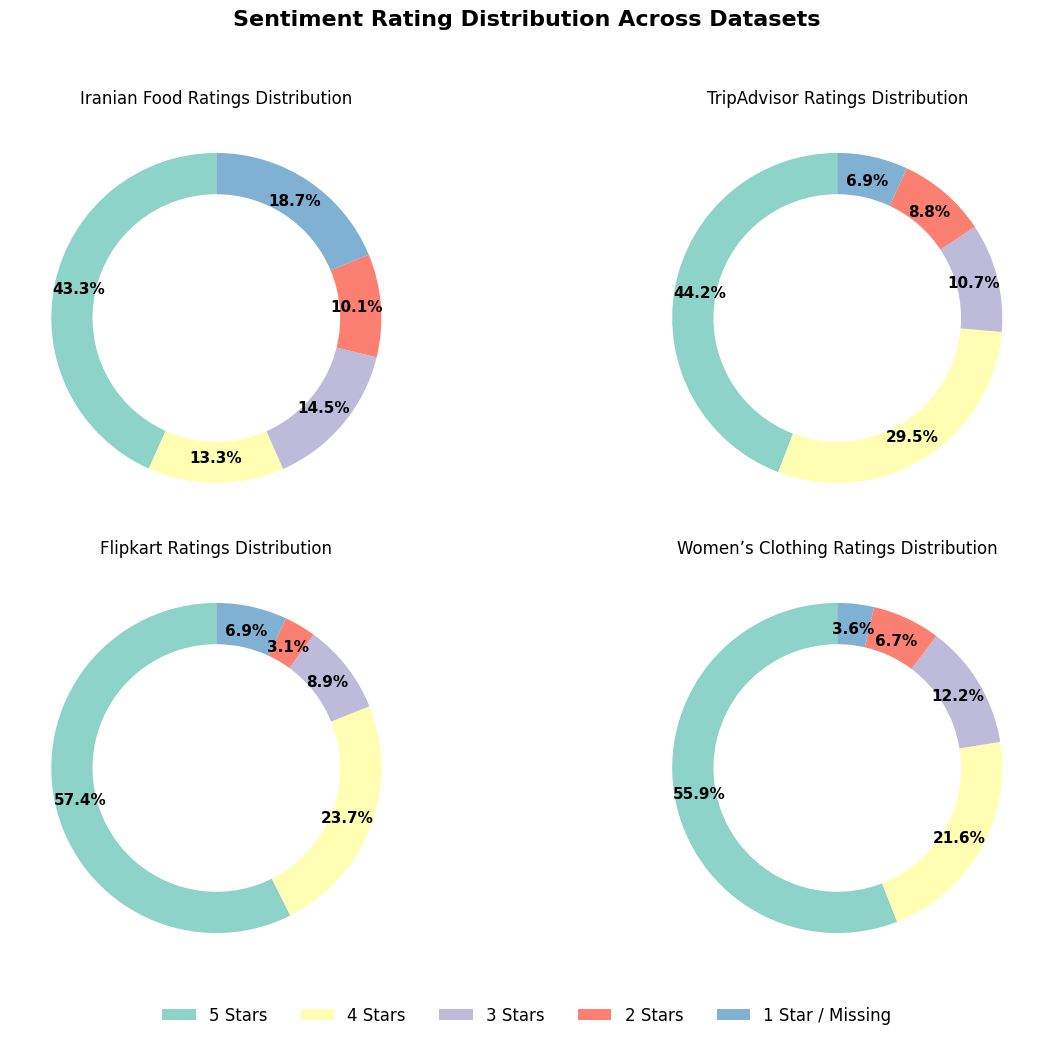

In [ ]:
import matplotlib.pyplot as plt

# === Adjustable Parameters ===
donut_width = 0.25               # Donut thickness (0 to 1)
label_fontsize = 12              # Font size in the legend
percent_fontsize = 11            # Font size for percentages
percent_fontsize_bold = True     # Bold text inside pies
percent_distance = 0.85          # Distance of percentage labels from center (0.5 to 1)
legend_position = 'bottom'       # 'top', 'bottom', 'right'
legend_vertical_offset = -0.05   # Distance of legend box from chart (negative = closer for bottom)

# === Data Setup ===
datasets = {
    "Iranian Food": [548, 169, 184, 128, 237],
    "TripAdvisor": [9054, 6039, 2184, 1793, 1421],
    "Flipkart": [5726, 2365, 884, 310, 691],
    "Women’s Clothing": [13131, 5077, 2871, 1565, 842]
}
labels = ["5 Stars", "4 Stars", "3 Stars", "2 Stars", "1 Star / Missing"]
colors = plt.cm.Set3.colors[:5]

# === Plotting ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (dataset_name, values) in zip(axes, datasets.items()):
    wedges, texts, autotexts = ax.pie(
        values,
        labels=None,
        colors=colors,
        autopct=lambda pct: f"{pct:.1f}%",
        startangle=90,
        pctdistance=percent_distance,
        wedgeprops=dict(width=donut_width),
        textprops=dict(
            fontsize=percent_fontsize,
            fontweight='bold' if percent_fontsize_bold else 'normal',
            color="black"
        )
    )
    ax.set_title(f"{dataset_name} Ratings Distribution", fontsize=12)

# === Legend Position Logic ===
legend_loc = {
    'top': dict(loc='upper center', bbox_to_anchor=(0.5, 1.15)),
    'bottom': dict(loc='lower center', bbox_to_anchor=(0.5, legend_vertical_offset)),
    'right': dict(loc='center left', bbox_to_anchor=(1.02, 0.5))
}.get(legend_position, dict(loc='lower center', bbox_to_anchor=(0.5, legend_vertical_offset)))

fig.legend(labels, ncol=5, fontsize=label_fontsize, frameon=False, **legend_loc)

# === Title and Layout ===
plt.suptitle("Sentiment Rating Distribution Across Datasets", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])

# === Save the Figure ===
plt.savefig("Fig_Rating_Distribution_Datasets.jpeg", dpi=800, format='jpeg', bbox_inches='tight')

# === Show the Plot ===
plt.show()

## **Preprocessing the texts**

### **Food**

In [ ]:
import pandas as pd
import re
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Ensure stopwords and stemmer are available
stopword = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Define the preprocessing function
def clean(text):
    text = str(text).lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = [word for word in text.split(' ') if word not in stopword]
    text = " ".join(text)
    text = [stemmer.stem(word) for word in text.split(' ')]
    text = " ".join(text)
    return text


df_food["preprocessed comment"] = df_food["comment"].apply(clean)

df_food.head(30)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc


### **TikTok**

In [ ]:
# df_tiktok ["preprocessed comment"] = df_tiktok ["content"].apply(clean)

# df_tiktok.head(30)

### **Trip Advisor**

In [ ]:
# Apply the 'clean' function to the review text column in df_trip_advisor
df_trip_advisor["preprocessed comment"] = df_trip_advisor["Review"].apply(clean)

# Show the first 30 rows to verify
df_trip_advisor.head(30)

,Review,Rating,preprocessed comment
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...


### **Women Colthing Reviews**

In [ ]:
# Apply the 'clean' function to the review text column in df_women_clothing
df_women_clothing["preprocessed comment"] = df_women_clothing["Review Text"].apply(clean)

# Show the first 30 rows to verify
df_women_clothing.head(30)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,preprocessed comment
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,absolut wonder silki sexi comfort
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,love dress sooo pretti happen find store im ...
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,high hope dress realli want work initi order p...
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,love love love jumpsuit fun flirti fabul everi...
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,shirt flatter due adjust front tie perfect len...
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses,love traci rees dress one petit feet tall usu...
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,Knits,ade basket hte last mintu see would look like ...
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits,order carbon store pick ton stuff alway tri us...
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,Dresses,love dress usual get xs run littl snug bust or...
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses,im lb order petit make sure length wasnt lon...


### **Flipkart Customer Review**

In [ ]:
# Apply the 'clean' function to the review column in df_Flipkart
df_Flipkart["preprocessed comment"] = df_Flipkart["review"].apply(clean)

# Preview first 30 rows
df_Flipkart.head(30)

,review,rating,preprocessed comment
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...


## **Value_Counts Check**

In [ ]:
df_food["Scores"].value_counts()

,count
Scores,
5,424
NAN,185
3,150
4,135
2,106


In [ ]:
# df_tiktok["score"].value_counts()

In [ ]:
df_trip_advisor["Rating"].value_counts()

,count
Rating,
5,334
4,311
3,137
1,110
2,108


In [ ]:
df_women_clothing["Rating"].value_counts()

,count
Rating,
5,546
4,228
3,127
2,72
1,27


In [ ]:
df_Flipkart["rating"].value_counts()

,count
rating,
5,597
4,304
3,73
1,18
2,8


## **Analysis (NO DL and NO FIS)**

### **Food**

In [ ]:
df_food.head(7)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...


In [ ]:
nltk.download('vader_lexicon')

sentiments = SentimentIntensityAnalyzer()

df_food["Positive_VADER"] = [sentiments.polarity_scores(i)["pos"] for i in df_food["preprocessed comment"]]
df_food["Negative_VADER"] = [sentiments.polarity_scores(i)["neg"] for i in df_food["preprocessed comment"]]
df_food["Neutral_VADER"]  = [sentiments.polarity_scores(i)["neu"] for i in df_food["preprocessed comment"]]

df_food.head(30)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000


### **TikTok**

In [ ]:
# df_tiktok.head(7)

In [ ]:
# nltk.download('vader_lexicon')

# sentiments = SentimentIntensityAnalyzer()

# df_tiktok["Positive_VADER"] = [sentiments.polarity_scores(i)["pos"] for i in df_tiktok["preprocessed comment"]]
# df_tiktok["Negative_VADER"] = [sentiments.polarity_scores(i)["neg"] for i in df_tiktok["preprocessed comment"]]
# df_tiktok["Neutral_VADER"]  = [sentiments.polarity_scores(i)["neu"] for i in df_tiktok["preprocessed comment"]]

# df_tiktok.head(30)

### **Trip Advisor**

In [ ]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

# Initialize sentiment analyzer
sentiments = SentimentIntensityAnalyzer()

# Apply VADER sentiment scoring to the preprocessed comments
df_trip_advisor["Positive_VADER"] = [sentiments.polarity_scores(i)["pos"] for i in df_trip_advisor["preprocessed comment"]]
df_trip_advisor["Negative_VADER"] = [sentiments.polarity_scores(i)["neg"] for i in df_trip_advisor["preprocessed comment"]]
df_trip_advisor["Neutral_VADER"]  = [sentiments.polarity_scores(i)["neu"] for i in df_trip_advisor["preprocessed comment"]]

# Preview the results
df_trip_advisor.head(30)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...,0.153,0.042,0.805
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...,0.248,0.023,0.729
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...,0.173,0.036,0.791
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...,0.193,0.042,0.765
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...,0.468,0.000,0.532


### **Women Clothing Reviews**

In [ ]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

# Initialize sentiment analyzer
sentiments = SentimentIntensityAnalyzer()

# Apply VADER sentiment scoring to the preprocessed comments
df_women_clothing["Positive_VADER"] = [sentiments.polarity_scores(i)["pos"] for i in df_women_clothing["preprocessed comment"]]
df_women_clothing["Negative_VADER"] = [sentiments.polarity_scores(i)["neg"] for i in df_women_clothing["preprocessed comment"]]
df_women_clothing["Neutral_VADER"]  = [sentiments.polarity_scores(i)["neu"] for i in df_women_clothing["preprocessed comment"]]

# Preview the results
df_women_clothing.head(10)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,absolut wonder silki sexi comfort,0.385,0.000,0.615
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,love dress sooo pretti happen find store im ...,0.353,0.000,0.647
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,high hope dress realli want work initi order p...,0.286,0.000,0.714
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,love love love jumpsuit fun flirti fabul everi...,0.743,0.000,0.257
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,shirt flatter due adjust front tie perfect len...,0.487,0.000,0.513
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses,love traci rees dress one petit feet tall usu...,0.182,0.037,0.781
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,Knits,ade basket hte last mintu see would look like ...,0.049,0.051,0.900
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits,order carbon store pick ton stuff alway tri us...,0.122,0.000,0.878
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,Dresses,love dress usual get xs run littl snug bust or...,0.272,0.000,0.728
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses,im lb order petit make sure length wasnt lon...,0.299,0.000,0.701


### **Flipkart customer**

In [ ]:
# Apply VADER sentiment scoring to the preprocessed comments in df_Flipkart
df_Flipkart["Positive_VADER"] = [sentiments.polarity_scores(i)["pos"] for i in df_Flipkart["preprocessed comment"]]
df_Flipkart["Negative_VADER"] = [sentiments.polarity_scores(i)["neg"] for i in df_Flipkart["preprocessed comment"]]
df_Flipkart["Neutral_VADER"]  = [sentiments.polarity_scores(i)["neu"] for i in df_Flipkart["preprocessed comment"]]

# Preview
df_Flipkart.head(10)

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...,0.479,0.029,0.492
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...,0.509,0.000,0.491
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...,0.202,0.069,0.729
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...,0.237,0.076,0.688
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...,0.691,0.000,0.309


## **FIS (general) (This is NOT for each datasets and is general for further general applicability)**

In [ ]:
!pip install scikit-fuzzy

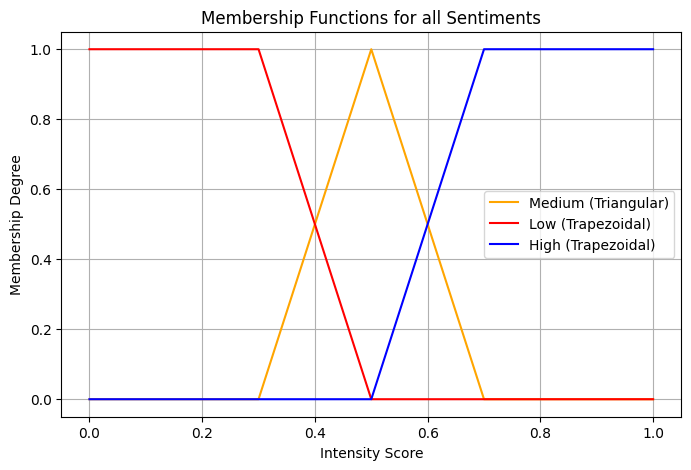

In [ ]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

# Define the universe of discourse (input range)
x = np.arange(0, 1.1, 0.1)

# Define membership functions
low    = fuzz.trapmf  (x, [0, 0, 0.3, 0.5])
medium = fuzz.trimf   (x, [0.3, 0.5, 0.7 ])
high   = fuzz.trapmf  (x, [0.5, 0.7, 1, 1])

# Plot the membership functions
plt.figure(figsize=(8, 5))
plt.plot(x, medium, label="Medium (Triangular)", color="orange")
plt.plot(x, low   , label="Low (Trapezoidal)"  , color="red")
plt.plot(x, high  , label="High (Trapezoidal)" , color="blue")


# Add plot labels and legend
plt.title("Membership Functions for all Sentiments")
plt.xlabel("Intensity Score")
plt.ylabel("Membership Degree")
plt.legend(loc="best")
plt.grid(True)
plt.show()

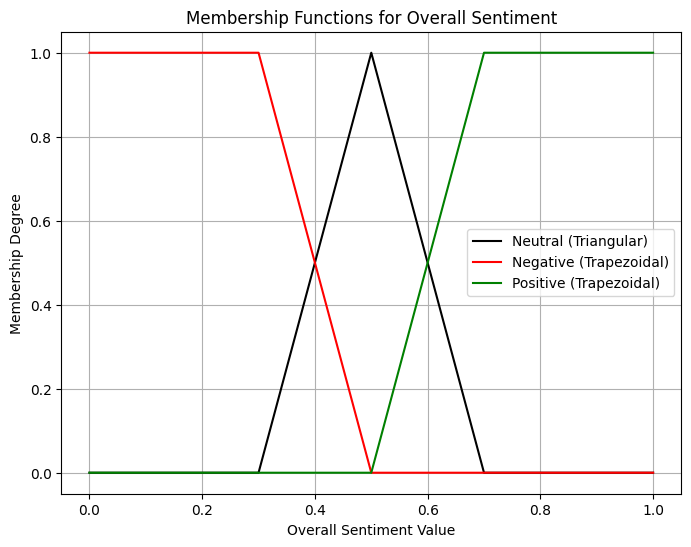

In [ ]:
# Retry plotting the membership functions for Overall Sentiment
plt.figure(figsize=(8, 6))

# Plot membership functions
plt.plot(x, fuzz.trimf(x,  [0.3, 0.5, 0.7]), label='Neutral (Triangular)', color='black')
plt.plot(x, fuzz.trapmf(x, [0, 0, 0.3, 0.5]), label='Negative (Trapezoidal)', color='red')
plt.plot(x, fuzz.trapmf(x, [0.5, 0.7, 1, 1]), label='Positive (Trapezoidal)', color='green')

# Add plot details
plt.title("Membership Functions for Overall Sentiment")
plt.xlabel("Overall Sentiment Value")
plt.ylabel("Membership Degree")
plt.legend(loc="best")
plt.grid(True)

# Display the plot
plt.show()

In [ ]:
#                                     FIS general
# ==============================================================================

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Fuzzy variables and membership functions
# ============================================================================================
# Define fuzzy input variables (antecedents)
positive = ctrl.Antecedent(np.arange(0, 1.1, 0.1), 'positive')
negative = ctrl.Antecedent(np.arange(0, 1.1, 0.1), 'negative')
neutral = ctrl.Antecedent(np.arange(0, 1.1, 0.1), 'neutral')

# Define fuzzy output variable (consequent)
overall_sentiment = ctrl.Consequent(np.arange(0, 1.1, 0.1), 'overall_sentiment')


# Defining the membership function intensity
# => The general strcuture of these functions are eual for all sentiments
# What?
# => This means that whether you are positive, neutral, or negative, the reported numbers and the plot of graph, are equal
# ============================================================================================
# Membership functions for 'positive'
positive['low'] = fuzz.trapmf(positive.universe, [0, 0, 0.3, 0.5])        # trapezoidal
positive['medium'] = fuzz.trimf(positive.universe, [0.3, 0.5, 0.7])       # trinagula
positive['high'] = fuzz.trapmf(positive.universe, [0.5, 0.7, 1, 1])       # trapezoidal

# Membership functions for 'negative'
negative['low'] = fuzz.trapmf(negative.universe, [0, 0, 0.3, 0.5])       # trapezoidal
negative['medium'] = fuzz.trimf(negative.universe, [0.3, 0.5, 0.7])      # triangualr
negative['high'] = fuzz.trapmf(negative.universe, [0.5, 0.7, 1, 1])      # trapezoidal

# Membership functions for 'neutral'
neutral['low'] = fuzz.trapmf(neutral.universe, [0, 0, 0.3, 0.5])         # trapezoidal
neutral['medium'] = fuzz.trimf(neutral.universe, [0.3, 0.5, 0.7])        # triangualr
neutral['high'] = fuzz.trapmf(neutral.universe, [0.5, 0.7, 1, 1])        # tranpezoidal
# ============================================================================================

# For Sentiments
# ============================================================================================
# Membership functions for 'overall_sentiment'
overall_sentiment['negative'] = fuzz.trapmf(overall_sentiment.universe, [0, 0, 0.3, 0.5])
overall_sentiment['neutral'] = fuzz.trimf(overall_sentiment.universe, [0.3, 0.5, 0.7])
overall_sentiment['positive'] = fuzz.trapmf(overall_sentiment.universe, [0.5, 0.7, 1, 1])
# ============================================================================================

# Define rules for all 27 combinations of states
# ============================================================================================
rules = []
rules.append(ctrl.Rule(positive['low'] & negative['low'] & neutral['low'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['low'] & negative['low'] & neutral['medium'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['low'] & negative['low'] & neutral['high'], overall_sentiment['neutral']))

rules.append(ctrl.Rule(positive['low'] & negative['medium'] & neutral['low'], overall_sentiment['negative']))
rules.append(ctrl.Rule(positive['low'] & negative['medium'] & neutral['medium'], overall_sentiment['negative']))
rules.append(ctrl.Rule(positive['low'] & negative['medium'] & neutral['high'], overall_sentiment['negative']))      # negative / netural

rules.append(ctrl.Rule(positive['low'] & negative['high'] & neutral['low'], overall_sentiment['negative']))
rules.append(ctrl.Rule(positive['low'] & negative['high'] & neutral['medium'], overall_sentiment['negative']))
rules.append(ctrl.Rule(positive['low'] & negative['high'] & neutral['high'], overall_sentiment['negative']))

rules.append(ctrl.Rule(positive['medium'] & negative['low'] & neutral['low'], overall_sentiment['positive']))
rules.append(ctrl.Rule(positive['medium'] & negative['low'] & neutral['medium'], overall_sentiment['positive']))
rules.append(ctrl.Rule(positive['medium'] & negative['low'] & neutral['high'], overall_sentiment['positive']))      # positive / netural

rules.append(ctrl.Rule(positive['medium'] & negative['medium'] & neutral['low'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['medium'] & negative['medium'] & neutral['medium'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['medium'] & negative['medium'] & neutral['high'], overall_sentiment['neutral']))

rules.append(ctrl.Rule(positive['medium'] & negative['high'] & neutral['low'], overall_sentiment['negative']))
rules.append(ctrl.Rule(positive['medium'] & negative['high'] & neutral['medium'], overall_sentiment['negative']))      # negative / netural
rules.append(ctrl.Rule(positive['medium'] & negative['high'] & neutral['high'], overall_sentiment['negative']))        # negative / netural

rules.append(ctrl.Rule(positive['high'] & negative['low'] & neutral['low'], overall_sentiment['positive']))
rules.append(ctrl.Rule(positive['high'] & negative['low'] & neutral['medium'], overall_sentiment['positive']))
rules.append(ctrl.Rule(positive['high'] & negative['low'] & neutral['high'], overall_sentiment['positive']))

rules.append(ctrl.Rule(positive['high'] & negative['medium'] & neutral['low'], overall_sentiment['positive']))       # positive
rules.append(ctrl.Rule(positive['high'] & negative['medium'] & neutral['medium'], overall_sentiment['positive']))
rules.append(ctrl.Rule(positive['high'] & negative['medium'] & neutral['high'], overall_sentiment['positive']))

rules.append(ctrl.Rule(positive['high'] & negative['high'] & neutral['low'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['high'] & negative['high'] & neutral['medium'], overall_sentiment['neutral']))
rules.append(ctrl.Rule(positive['high'] & negative['high'] & neutral['high'], overall_sentiment['neutral']))
# ============================================================================================


# Build the control system and simulation
# ============================================================================================
sentiment_ctrl = ctrl.ControlSystem(rules)  # Pass all 27 rules
sentiment_sim = ctrl.ControlSystemSimulation(sentiment_ctrl)
# ============================================================================================

## **FIS with NO refinement (approach 1)**

### **Food**

In [ ]:
df_food

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811
...,...,...,...,...,...,...,...,...,...
995,996,ارسالش یکم طولانی بود ولی در کل خوب,"Delivery took a bit long, but overall, it was ...",4,4,deliveri took bit long overal good,0.367,0.000,0.633
996,997,مثل همیشه خوب,Good as always.,5,2,good alway,0.744,0.000,0.256
997,998,عالی,Excellent.,5,1,excel,1.000,0.000,0.000
998,999,کل جعبه پیتزا به شکل کاملا افتضاحی به هم ریخته...,"The pizza box was completely messed up, making...",NAN,2,pizza box complet mess make food ined,0.000,0.294,0.706


In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments = []

# Loop through each row in the DataFrame
for _, row in df_food.iterrows():
    sentiment_sim.input['positive'] = row['Positive_VADER']
    sentiment_sim.input['negative'] = row['Negative_VADER']
    sentiment_sim.input['neutral']  = row['Neutral_VADER']
    sentiment_sim.compute()
    overall_sentiments.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_food['Overall_Sentiment_NO_refinement'] = overall_sentiments

df_food.head(50)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748,0.500000
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759,0.500000
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000,0.500000
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814,0.500000
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000,0.500000


### **TikTok**

In [ ]:
# # List to store the calculated Overall Sentiment for each record
# overall_sentiments = []

# # Loop through each row in the DataFrame
# for _, row in df_tiktok.iterrows():
#     sentiment_sim.input['positive'] = row['Positive_VADER']
#     sentiment_sim.input['negative'] = row['Negative_VADER']
#     sentiment_sim.input['neutral']  = row['Neutral_VADER']
#     sentiment_sim.compute()
#     overall_sentiments.append(sentiment_sim.output['overall_sentiment'])

# # Add the calculated Overall Sentiment as a new column
# df_tiktok['Overall_Sentiment_NO_refinement'] = overall_sentiments

# df_tiktok.head(50)

### **Trip Advisor**

In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments = []

# Loop through each row in the DataFrame
for _, row in df_trip_advisor.iterrows():
    sentiment_sim.input['positive'] = row['Positive_VADER']
    sentiment_sim.input['negative'] = row['Negative_VADER']
    sentiment_sim.input['neutral']  = row['Neutral_VADER']
    sentiment_sim.compute()
    overall_sentiments.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_trip_advisor['Overall_Sentiment_NO_refinement'] = overall_sentiments

# Show first 50 rows
df_trip_advisor.head(50)

,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...,0.153,0.042,0.805,0.500000
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...,0.248,0.023,0.729,0.500000
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...,0.173,0.036,0.791,0.500000
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...,0.193,0.042,0.765,0.500000
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...,0.468,0.000,0.532,0.754859


### **Women Clothing Reviews**

In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments = []

# Loop through each row in the DataFrame
for _, row in df_women_clothing.iterrows():
    sentiment_sim.input['positive'] = row['Positive_VADER']
    sentiment_sim.input['negative'] = row['Negative_VADER']
    sentiment_sim.input['neutral']  = row['Neutral_VADER']
    sentiment_sim.compute()
    overall_sentiments.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_women_clothing['Overall_Sentiment_NO_refinement'] = overall_sentiments

# Show first 50 rows
df_women_clothing.head(50)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,absolut wonder silki sexi comfort,0.385,0.000,0.615,0.654072
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,love dress sooo pretti happen find store im ...,0.353,0.000,0.647,0.607760
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,high hope dress realli want work initi order p...,0.286,0.000,0.714,0.500000
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,love love love jumpsuit fun flirti fabul everi...,0.743,0.000,0.257,0.795833
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,shirt flatter due adjust front tie perfect len...,0.487,0.000,0.513,0.778644
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses,love traci rees dress one petit feet tall usu...,0.182,0.037,0.781,0.500000
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,Knits,ade basket hte last mintu see would look like ...,0.049,0.051,0.900,0.500000
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits,order carbon store pick ton stuff alway tri us...,0.122,0.000,0.878,0.500000
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,Dresses,love dress usual get xs run littl snug bust or...,0.272,0.000,0.728,0.500000
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses,im lb order petit make sure length wasnt lon...,0.299,0.000,0.701,0.500000


### **Flipkart customer**

In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments = []

# Loop through each row in df_Flipkart
for _, row in df_Flipkart.iterrows():
    sentiment_sim.input['positive'] = row['Positive_VADER']
    sentiment_sim.input['negative'] = row['Negative_VADER']
    sentiment_sim.input['neutral']  = row['Neutral_VADER']
    sentiment_sim.compute()
    overall_sentiments.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_Flipkart['Overall_Sentiment_NO_refinement'] = overall_sentiments

# Show first 50 rows
df_Flipkart.head(50)

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...,0.479,0.029,0.492,0.768462
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...,0.509,0.000,0.491,0.793992
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...,0.202,0.069,0.729,0.500000
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...,0.237,0.076,0.688,0.500000
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...,0.691,0.000,0.309,0.793992


## **Transfomer (DL) Sentiment Analysis**

### **Food**

In [ ]:
df_food.shape

(1000, 10)

In [ ]:
from transformers import pipeline

# Load the sentiment analysis model
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# Function to convert single comment to positive & negative scores
def get_sentiment_scores(text):
    result = sentiment_pipeline(text)[0]
    label = result['label']
    score = result['score']
    if label == 'POSITIVE':
        return score, 1 - score
    else:
        return 1 - score, score

# Apply to each row in 'comment' column
df_food[["Transformer_positive_score", "Transformer_Negative_score"]] = df_food["comment"].apply(
    lambda x: pd.Series(get_sentiment_scores(str(x)))
)

df_food.head(30)

Device set to use cpu


,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748,0.500000,0.003529,0.996471
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759,0.500000,0.999815,0.000185
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000,0.500000,0.003728,0.996272
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814,0.500000,0.000751,0.999249
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000,0.500000,0.001139,0.998861


In [ ]:
df_food.shape

(1000, 12)

In [ ]:
neutral_count_food = (df_food["Neutral_VADER"] == 1).sum()
print("Number of neutral entries (VADER):", neutral_count_food)

Number of neutral entries (VADER): 291


In [ ]:
neutral_count_food / df_food.shape[0] * 100

np.float64(29.099999999999998)

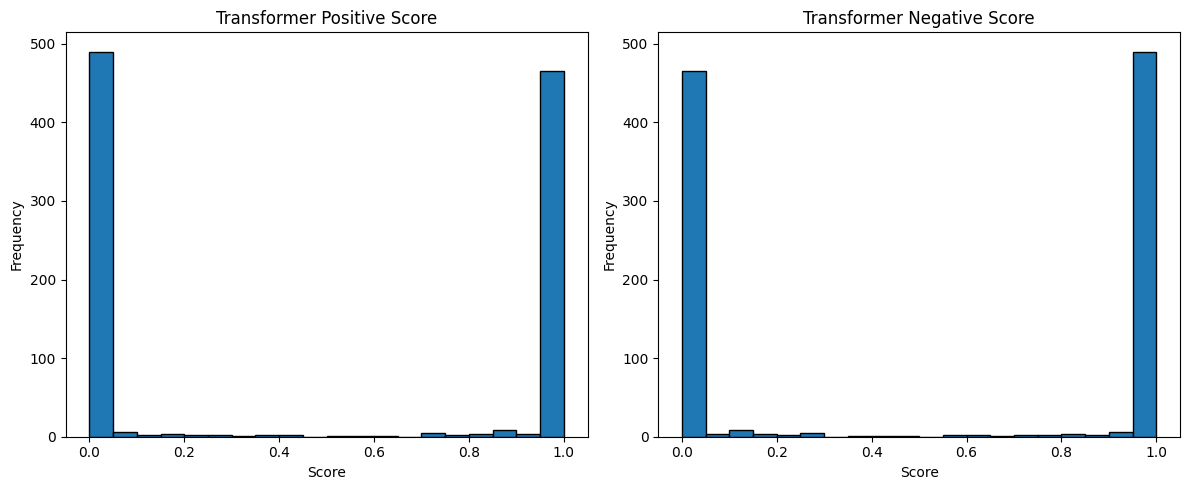

In [ ]:
# Create histograms for both scores side by side
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Positive score histogram
axs[0].hist(df_food["Transformer_positive_score"], bins=20, edgecolor='black')
axs[0].set_title("Transformer Positive Score")
axs[0].set_xlabel("Score")
axs[0].set_ylabel("Frequency")

# Negative score histogram
axs[1].hist(df_food["Transformer_Negative_score"], bins=20, edgecolor='black')
axs[1].set_title("Transformer Negative Score")
axs[1].set_xlabel("Score")
axs[1].set_ylabel("Frequency")

# Adjust spacing
plt.tight_layout()
plt.show()

In [ ]:
# # Mean of Negative_VADER where it's not equal to 0
# mean_negative = df_food[df_food["Negative_VADER"] != 0]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not equal to 0
# mean_positive = df_food[df_food["Positive_VADER"] != 0]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# mean_negative = df_food["Negative_VADER"].mean()
# mean_positive = df_food["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# # Mean of Negative_VADER where it's not equal to 0
# mean_negative = df_food[df_food["Transformer_Negative_score"] > 0.5]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not equal to 0
# mean_positive = df_food[df_food["Transformer_positive_score"] > 0.5]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

### **TikTok**

In [ ]:
# df_tiktok.shape

In [ ]:
# neutral_count_tiktok = (df_tiktok["Neutral_VADER"] == 1).sum()
# print("Number of neutral entries (VADER):", neutral_count_tiktok)

In [ ]:
# neutral_count_tiktok / df_tiktok.shape[0] * 100

In [ ]:
# from transformers import pipeline

# # Load the sentiment analysis model
# sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# # Function to convert single comment to positive & negative scores
# def get_sentiment_scores(text):
#     result = sentiment_pipeline(text)[0]
#     label = result['label']
#     score = result['score']
#     if label == 'POSITIVE':
#         return score, 1 - score
#     else:
#         return 1 - score, score

# # Apply to each row in 'comment' column
# df_tiktok[["Transformer_positive_score", "Transformer_Negative_score"]] = df_tiktok["content"].apply(
#     lambda x: pd.Series(get_sentiment_scores(str(x)))
# )

# df_tiktok.head(30)

In [ ]:
# # Create histograms for both scores side by side
# fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# # Positive score histogram
# axs[0].hist(df_tiktok["Transformer_positive_score"], bins=20, edgecolor='black')
# axs[0].set_title("Transformer Positive Score")
# axs[0].set_xlabel("Score")
# axs[0].set_ylabel("Frequency")

# # Negative score histogram
# axs[1].hist(df_food["Transformer_Negative_score"], bins=20, edgecolor='black')
# axs[1].set_title("Transformer Negative Score")
# axs[1].set_xlabel("Score")
# axs[1].set_ylabel("Frequency")

# # Adjust spacing
# plt.tight_layout()
# plt.show()

In [ ]:
# # Mean of Negative_VADER where it's not equal to 0
# mean_negative = df_tiktok[df_tiktok["Negative_VADER"] != 0]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not equal to 0
# mean_positive = df_tiktok[df_tiktok["Positive_VADER"] != 0]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# mean_negative = df_tiktok["Negative_VADER"].mean()
# mean_positive = df_tiktok["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# # Mean of Negative_VADER where it's not equal to 0
# mean_negative = df_tiktok[df_tiktok["Transformer_Negative_score"] > 0.5]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not equal to 0
# mean_positive = df_tiktok[df_tiktok["Transformer_positive_score"] > 0.5]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

### **Trip Advisor**

In [ ]:
df_trip_advisor.shape

(1000, 7)

In [ ]:
neutral_count_trip = (df_trip_advisor["Neutral_VADER"] == 1).sum()
print("Number of neutral entries (VADER):", neutral_count_trip)

Number of neutral entries (VADER): 1


In [ ]:
neutral_count_trip / df_trip_advisor.shape[0] * 100

np.float64(0.1)

In [ ]:
# from transformers import pipeline

# # لود کردن مدل تحلیل احساسات
# sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# # تابع گرفتن امتیازها از مدل
# def get_sentiment_scores(text):
#     # کوتاه کردن متن به ۵۱۲ کاراکتر
#     truncated = text[:512]
#     result = sentiment_pipeline(truncated)[0]
#     label = result['label']
#     score = result['score']

#     if label == 'POSITIVE':
#         return score, 1 - score
#     else:
#         return 1 - score, score

# # اعمال تحلیل احساسات روی ستون Review
# df_trip_advisor[["Transformer_positive_score", "Transformer_Negative_score"]] = df_trip_advisor["Review"].apply(
#     lambda x: pd.Series(get_sentiment_scores(str(x)))
# )

# # نمایش نمونه‌ها
# df_trip_advisor.head(30)

In [ ]:
from transformers import pipeline, AutoTokenizer

# Load tokenizer and model-based sentiment pipeline
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", tokenizer=tokenizer)

# Function to get sentiment scores with proper token truncation
def get_sentiment_scores(text):
    # Truncate to max 512 tokens using tokenizer
    tokens = tokenizer.encode(text, max_length=512, truncation=True, return_tensors=None)
    truncated_text = tokenizer.decode(tokens, skip_special_tokens=True)

    result = sentiment_pipeline(truncated_text)[0]
    label = result['label']
    score = result['score']

    if label == 'POSITIVE':
        return score, 1 - score
    else:
        return 1 - score, score

# Apply to DataFrame
df_trip_advisor[["Transformer_positive_score", "Transformer_Negative_score"]] = df_trip_advisor["Review"].apply(
    lambda x: pd.Series(get_sentiment_scores(str(x)))
)

df_trip_advisor.head(30)

Device set to use cpu


,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000,0.705108,0.294892
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000,0.003149,0.996851
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000,0.002545,0.997455
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383,0.999213,0.000787
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000,0.201841,0.798159
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...,0.153,0.042,0.805,0.500000,0.909362,0.090638
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...,0.248,0.023,0.729,0.500000,0.999665,0.000335
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...,0.173,0.036,0.791,0.500000,0.998311,0.001689
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...,0.193,0.042,0.765,0.500000,0.998424,0.001576
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...,0.468,0.000,0.532,0.754859,0.996120,0.003880


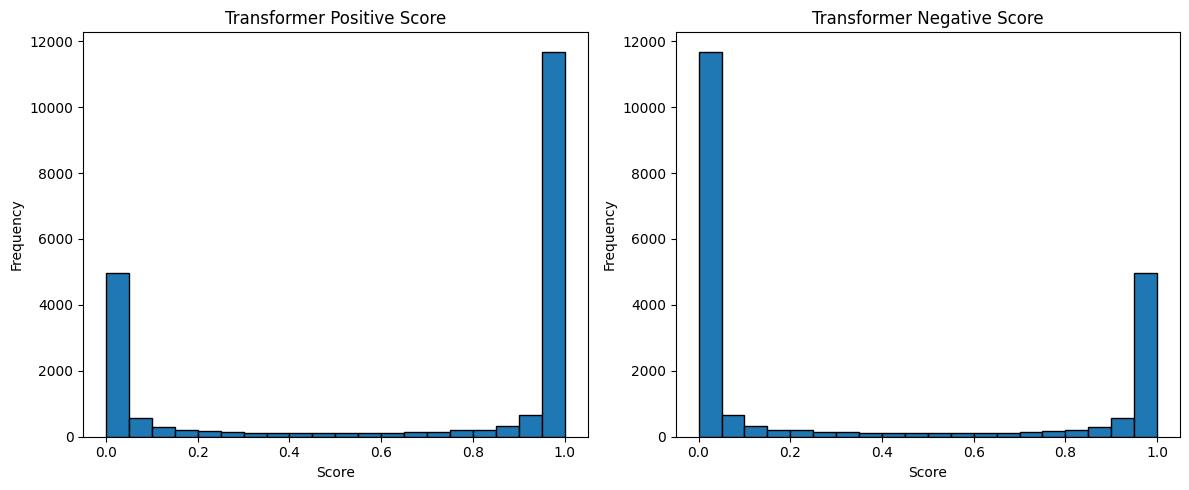

In [ ]:
# Create histograms for both scores side by side
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Positive score histogram
axs[0].hist(df_trip_advisor["Transformer_positive_score"], bins=20, edgecolor='black')
axs[0].set_title("Transformer Positive Score")
axs[0].set_xlabel("Score")
axs[0].set_ylabel("Frequency")

# Negative score histogram
axs[1].hist(df_trip_advisor["Transformer_Negative_score"], bins=20, edgecolor='black')
axs[1].set_title("Transformer Negative Score")
axs[1].set_xlabel("Score")
axs[1].set_ylabel("Frequency")

# Adjust spacing
plt.tight_layout()
plt.show()

In [ ]:
# # Mean of Negative_VADER where it's not equal to 0
# mean_negative = df_trip_advisor[df_trip_advisor["Negative_VADER"] != 0]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not equal to 0
# mean_positive = df_trip_advisor[df_trip_advisor["Positive_VADER"] != 0]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# mean_negative = df_trip_advisor["Negative_VADER"].mean()
# mean_positive = df_trip_advisor["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# # Mean of Negative_VADER where transformer negative score is high
# mean_negative = df_trip_advisor[df_trip_advisor["Transformer_Negative_score"] > 0.5]["Negative_VADER"].mean()

# # Mean of Positive_VADER where transformer positive score is high
# mean_positive = df_trip_advisor[df_trip_advisor["Transformer_positive_score"] > 0.5]["Positive_VADER"].mean()

# # Print the results
# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

### **Women comments clothing**

In [ ]:
# Check the number of rows and columns in df_women_clothing
df_women_clothing.shape

(23486, 16)

In [ ]:
# Count the number of rows where Neutral_VADER is exactly 1 (fully neutral)
neutral_count_women = (df_women_clothing["Neutral_VADER"] == 1).sum()
print("Number of neutral entries (VADER):", neutral_count_women)

Number of neutral entries (VADER): 1226


In [ ]:
# Calculate the percentage of fully neutral entries
neutral_count_women / df_women_clothing.shape[0] * 100

np.float64(5.2201311419569105)

In [ ]:
# from transformers import pipeline

# # Load the sentiment analysis model
# sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# # Function to get sentiment scores from text (char-based truncation)
# def get_sentiment_scores(text):
#     # Truncate the text to 512 characters
#     truncated = text[:512]
#     result = sentiment_pipeline(truncated)[0]
#     label = result['label']
#     score = result['score']

#     if label == 'POSITIVE':
#         return score, 1 - score
#     else:
#         return 1 - score, score

# # Apply to 'Review Text' column
# df_women_clothing[["Transformer_positive_score", "Transformer_Negative_score"]] = df_women_clothing["Review Text"].apply(
#     lambda x: pd.Series(get_sentiment_scores(str(x)))
# )

# df_women_clothing.head(30)

In [ ]:
from transformers import pipeline, AutoTokenizer

# Load tokenizer and sentiment pipeline
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", tokenizer=tokenizer)

# Function to apply token-based truncation
def get_sentiment_scores(text):
    tokens = tokenizer.encode(text, max_length=512, truncation=True, return_tensors=None)
    truncated_text = tokenizer.decode(tokens, skip_special_tokens=True)

    result = sentiment_pipeline(truncated_text)[0]
    label = result['label']
    score = result['score']

    if label == 'POSITIVE':
        return score, 1 - score
    else:
        return 1 - score, score

# Apply transformer sentiment scores
df_women_clothing[["Transformer_positive_score", "Transformer_Negative_score"]] = df_women_clothing["Review Text"].apply(
    lambda x: pd.Series(get_sentiment_scores(str(x)))
)

df_women_clothing.head(30)

Device set to use cpu


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,absolut wonder silki sexi comfort,0.385,0.000,0.615,0.654072,0.999877,0.000123
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,love dress sooo pretti happen find store im ...,0.353,0.000,0.647,0.607760,0.998684,0.001316
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,high hope dress realli want work initi order p...,0.286,0.000,0.714,0.500000,0.988560,0.011440
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,love love love jumpsuit fun flirti fabul everi...,0.743,0.000,0.257,0.795833,0.999888,0.000112
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,shirt flatter due adjust front tie perfect len...,0.487,0.000,0.513,0.778644,0.999393,0.000607
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses,love traci rees dress one petit feet tall usu...,0.182,0.037,0.781,0.500000,0.122256,0.877744
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,Knits,ade basket hte last mintu see would look like ...,0.049,0.051,0.900,0.500000,0.332429,0.667571
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits,order carbon store pick ton stuff alway tri us...,0.122,0.000,0.878,0.500000,0.875515,0.124485
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,Dresses,love dress usual get xs run littl snug bust or...,0.272,0.000,0.728,0.500000,0.995387,0.004613
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses,im lb order petit make sure length wasnt lon...,0.299,0.000,0.701,0.500000,0.997519,0.002481


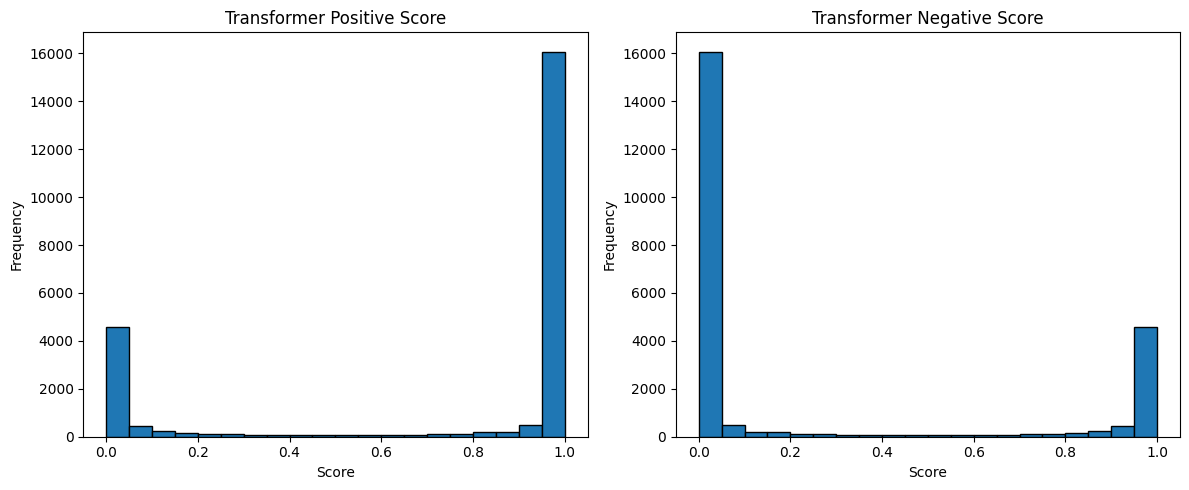

In [ ]:
# Create histograms for both transformer sentiment scores
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Histogram for positive scores
axs[0].hist(df_women_clothing["Transformer_positive_score"], bins=20, edgecolor='black')
axs[0].set_title("Transformer Positive Score")
axs[0].set_xlabel("Score")
axs[0].set_ylabel("Frequency")

# Histogram for negative scores
axs[1].hist(df_women_clothing["Transformer_Negative_score"], bins=20, edgecolor='black')
axs[1].set_title("Transformer Negative Score")
axs[1].set_xlabel("Score")
axs[1].set_ylabel("Frequency")

# Layout adjustment
plt.tight_layout()
plt.show()

In [ ]:
# # Mean of Negative_VADER where it's not zero
# mean_negative = df_women_clothing[df_women_clothing["Negative_VADER"] != 0]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not zero
# mean_positive = df_women_clothing[df_women_clothing["Positive_VADER"] != 0]["Positive_VADER"].mean()

# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# # Mean of Negative and Positive VADER scores (including zeros)
# mean_negative = df_women_clothing["Negative_VADER"].mean()
# mean_positive = df_women_clothing["Positive_VADER"].mean()

# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

In [ ]:
# # Mean of Negative_VADER where Transformer negative score > 0.5
# mean_negative = df_women_clothing[df_women_clothing["Transformer_Negative_score"] > 0.5]["Negative_VADER"].mean()

# # Mean of Positive_VADER where Transformer positive score > 0.5
# mean_positive = df_women_clothing[df_women_clothing["Transformer_positive_score"] > 0.5]["Positive_VADER"].mean()

# print("Mean Positive Score:", mean_positive)
# print("Mean Negative Score:", mean_negative)

### **Flipkart**

In [ ]:
# Check the number of rows and columns in df_Flipkart
df_Flipkart.shape

(9976, 7)

In [ ]:
# Count the number of rows where Neutral_VADER is exactly 1 (fully neutral)
neutral_count_flipkart = (df_Flipkart["Neutral_VADER"] == 1).sum()
print("Number of neutral entries (VADER):", neutral_count_flipkart)

Number of neutral entries (VADER): 2975


In [ ]:
# Calculate the percentage of fully neutral entries
neutral_percentage = neutral_count_flipkart / df_Flipkart.shape[0] * 100
print(f"Percentage of fully neutral entries: {neutral_percentage:.2f}%")

Percentage of fully neutral entries: 29.82%


In [ ]:
# from transformers import pipeline

# # Load sentiment analysis model
# sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

# # Function to get sentiment scores (char-based truncation)
# def get_sentiment_scores(text):
#     truncated = text[:512]
#     result = sentiment_pipeline(truncated)[0]
#     label = result['label']
#     score = result['score']

#     if label == 'POSITIVE':
#         return score, 1 - score
#     else:
#         return 1 - score, score

# # Apply scores
# df_Flipkart[["Transformer_positive_score", "Transformer_Negative_score"]] = df_Flipkart["preprocessed comment"].apply(
#     lambda x: pd.Series(get_sentiment_scores(str(x)))
# )

# df_Flipkart.head(30)

In [ ]:
from transformers import pipeline, AutoTokenizer

# Load model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
sentiment_pipeline = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", tokenizer=tokenizer)

# Function for token-truncated sentiment scoring
def get_sentiment_scores(text):
    tokens = tokenizer.encode(text, max_length=512, truncation=True, return_tensors=None)
    truncated_text = tokenizer.decode(tokens, skip_special_tokens=True)

    result = sentiment_pipeline(truncated_text)[0]
    label = result['label']
    score = result['score']

    if label == 'POSITIVE':
        return score, 1 - score
    else:
        return 1 - score, score

# Apply to 'preprocessed comment'
df_Flipkart[["Transformer_positive_score", "Transformer_Negative_score"]] = df_Flipkart["preprocessed comment"].apply(
    lambda x: pd.Series(get_sentiment_scores(str(x)))
)

df_Flipkart.head(30)

Device set to use cpu


,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128,0.999437,0.000563
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529,0.988514,0.011486
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000,0.008479,0.991521
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943,0.720765,0.279235
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000,0.996558,0.003442
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...,0.479,0.029,0.492,0.768462,0.997893,0.002107
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...,0.509,0.000,0.491,0.793992,0.997390,0.002610
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...,0.202,0.069,0.729,0.500000,0.014374,0.985626
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...,0.237,0.076,0.688,0.500000,0.117956,0.882044
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...,0.691,0.000,0.309,0.793992,0.999753,0.000247


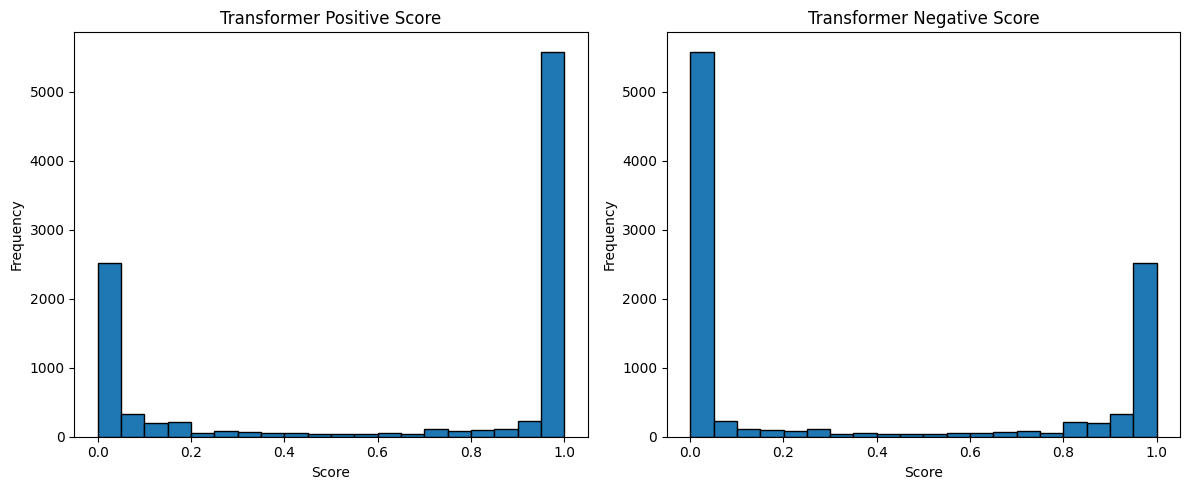

In [ ]:
# Create histograms for both transformer sentiment scores
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Histogram for positive scores
axs[0].hist(df_Flipkart["Transformer_positive_score"], bins=20, edgecolor='black')
axs[0].set_title("Transformer Positive Score")
axs[0].set_xlabel("Score")
axs[0].set_ylabel("Frequency")

# Histogram for negative scores
axs[1].hist(df_Flipkart["Transformer_Negative_score"], bins=20, edgecolor='black')
axs[1].set_title("Transformer Negative Score")
axs[1].set_xlabel("Score")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# # Mean of Negative_VADER where it's not zero
# mean_neg = df_Flipkart[df_Flipkart["Negative_VADER"] != 0]["Negative_VADER"].mean()

# # Mean of Positive_VADER where it's not zero
# mean_pos = df_Flipkart[df_Flipkart["Positive_VADER"] != 0]["Positive_VADER"].mean()

# print("Mean Positive Score (non-zero):", mean_pos)
# print("Mean Negative Score (non-zero):", mean_neg)

In [ ]:
# # Mean of Negative and Positive VADER scores (including zeros)
# mean_neg = df_Flipkart["Negative_VADER"].mean()
# mean_pos = df_Flipkart["Positive_VADER"].mean()

# print("Mean Positive Score (all):", mean_pos)
# print("Mean Negative Score (all):", mean_neg)

In [ ]:
# # Mean of Negative_VADER where Transformer negative score > 0.5
# mean_neg = df_Flipkart[df_Flipkart["Transformer_Negative_score"] > 0.5]["Negative_VADER"].mean()

# # Mean of Positive_VADER where Transformer positive score > 0.5
# mean_pos = df_Flipkart[df_Flipkart["Transformer_positive_score"] > 0.5]["Positive_VADER"].mean()

# print("Mean Positive Score (Transformer > 0.5):", mean_pos)
# print("Mean Negative Score (Transformer > 0.5):", mean_neg)

## **Overview**

In [ ]:
df_food.head(5)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790


In [ ]:
# df_tiktok.head(5)

In [ ]:
df_trip_advisor.head(5)

,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000,0.705108,0.294892
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000,0.003149,0.996851
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000,0.002545,0.997455
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383,0.999213,0.000787
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000,0.201841,0.798159


In [ ]:
df_women_clothing.head(5)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,absolut wonder silki sexi comfort,0.385,0.0,0.615,0.654072,0.999877,0.000123
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,love dress sooo pretti happen find store im ...,0.353,0.0,0.647,0.607760,0.998684,0.001316
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,high hope dress realli want work initi order p...,0.286,0.0,0.714,0.500000,0.988560,0.011440
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,love love love jumpsuit fun flirti fabul everi...,0.743,0.0,0.257,0.795833,0.999888,0.000112
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,shirt flatter due adjust front tie perfect len...,0.487,0.0,0.513,0.778644,0.999393,0.000607


In [ ]:
df_Flipkart.head(5)

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128,0.999437,0.000563
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529,0.988514,0.011486
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000,0.008479,0.991521
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943,0.720765,0.279235
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000,0.996558,0.003442


## **==> Fuzzy Logic Refinements [This is the major part] + FIS (new ReFined score) (approach 2)**

### **df_food**

In [ ]:
df_food.head()

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790


In [ ]:
# Define the ranges to check
ranges = [
    (0.95, 1.0),
    (0.90, 0.95),
    (0.80, 0.90),
    (0.70, 0.80),
    (0.60, 0.70)
]

# Total number of entries
total = len(df_food)

# Loop over each range and calculate proportion
for lower, upper in ranges:
    count = df_food[
        ((df_food["Transformer_positive_score"] >= lower) & (df_food["Transformer_positive_score"] <= upper)) |
        ((df_food["Transformer_Negative_score"] >= lower) & (df_food["Transformer_Negative_score"] <= upper))
    ].shape[0]

    proportion = (count / total)*100
    print(f"Range {lower}–{upper}:     {proportion:.2f}%    of the data ({count} out of {total})")

Range 0.95–1.0:     95.42%    of the data (1208 out of 1266)
Range 0.9–0.95:     1.11%    of the data (14 out of 1266)
Range 0.8–0.9:     1.50%    of the data (19 out of 1266)
Range 0.7–0.8:     1.11%    of the data (14 out of 1266)
Range 0.6–0.7:     0.39%    of the data (5 out of 1266)


In [ ]:
# import numpy as np

# # === Step 0: Make copies of the original VADER scores ===
# df_food["Refined_Positive"] = df_food["Positive_VADER"]
# df_food["Refined_Negative"] = df_food["Negative_VADER"]
# df_food["Refined_Neutral"] = df_food["Neutral_VADER"]

# # === PHASE 1: Redistribution based on Transformer thresholds ===
# def redistribute_sentiment(row):
#     for sentiment, threshold, shift_pct in [
#         ("positive", 0.9, 0.3),
#         ("positive", 0.8, 0.2),
#         ("positive", 0.7, 0.1),
#         ("negative", 0.9, 0.3),
#         ("negative", 0.8, 0.2),
#         ("negative", 0.7, 0.1),
#     ]:
#         if sentiment == "positive":
#             score = row["Transformer_positive_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Positive"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#         elif sentiment == "negative":
#             score = row["Transformer_Negative_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Negative"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#     return row

# df_food = df_food.apply(redistribute_sentiment, axis=1)

# # === PHASE 2: Amplify dominant sentiment & normalize ===
# def amplify_and_normalize(row):
#     pos = row["Refined_Positive"]
#     neg = row["Refined_Negative"]
#     neu = row["Refined_Neutral"]

#     if row["Transformer_positive_score"] > 0.9:
#         pos = np.sqrt(pos)
#     elif row["Transformer_Negative_score"] > 0.9:
#         neg = np.sqrt(neg)

#     # Normalize to sum = 1
#     total = pos + neg + neu
#     if total != 0:
#         row["Refined_Positive"] = pos / total
#         row["Refined_Negative"] = neg / total
#         row["Refined_Neutral"] = neu / total
#     else:
#         row["Refined_Positive"] = 0
#         row["Refined_Negative"] = 0
#         row["Refined_Neutral"] = 0

#     return row

# df_food = df_food.apply(amplify_and_normalize, axis=1)

In [ ]:
import numpy as np

# === Step 0: Make copies of the original VADER scores ===
df_food["Refined_Positive"] = df_food["Positive_VADER"]
df_food["Refined_Negative"] = df_food["Negative_VADER"]
df_food["Refined_Neutral"] = df_food["Neutral_VADER"]

# === PHASE 1: Redistribution based on Transformer thresholds ===
def redistribute_sentiment(row):
    for sentiment, threshold, shift_pct in [
        ("positive", 0.9, 0.3),
        ("positive", 0.8, 0.2),
        ("positive", 0.7, 0.1),
        ("negative", 0.9, 0.3),
        ("negative", 0.8, 0.2),
        ("negative", 0.7, 0.1),
    ]:
        if sentiment == "positive":
            score = row["Transformer_positive_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Positive"] += shift
                row["Refined_Neutral"] -= shift
                break  # Only apply the highest matching threshold
        elif sentiment == "negative":
            score = row["Transformer_Negative_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Negative"] += shift
                row["Refined_Neutral"] -= shift
                break  # Only apply the highest matching threshold
    return row

df_food = df_food.apply(redistribute_sentiment, axis=1)

# === PHASE 2: Amplify dominant sentiment & normalize ===
def amplify_and_normalize(row):
    pos = row["Refined_Positive"]
    neg = row["Refined_Negative"]
    neu = row["Refined_Neutral"]

    # Updated threshold from 0.9 to 0.95
    if row["Transformer_positive_score"] > 0.95:
        pos = np.sqrt(pos)
    elif row["Transformer_Negative_score"] > 0.95:
        neg = np.sqrt(neg)

    # Normalize to sum = 1
    total = pos + neg + neu
    if total != 0:
        row["Refined_Positive"] = pos / total
        row["Refined_Negative"] = neg / total
        row["Refined_Neutral"] = neu / total
    else:
        row["Refined_Positive"] = 0
        row["Refined_Negative"] = 0
        row["Refined_Neutral"] = 0

    return row

df_food = df_food.apply(amplify_and_normalize, axis=1)

In [ ]:
df_food.head(15)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795,0.000000,0.695149,0.304851
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050,0.318206,0.342052,0.339741
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797,0.000000,0.628478,0.371522
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555,0.000000,0.438978,0.561022
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790,0.000000,0.536645,0.463355
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748,0.500000,0.003529,0.996471,0.201712,0.379177,0.419112
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759,0.500000,0.999815,0.000185,0.563046,0.000000,0.436954
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000,0.500000,0.003728,0.996272,0.000000,0.438978,0.561022
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814,0.500000,0.000751,0.999249,0.090690,0.452009,0.457301
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000,0.500000,0.001139,0.998861,0.000000,0.438978,0.561022


In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments_refined = []

# Loop through each row in the DataFrame
for _, row in df_food.iterrows():
    sentiment_sim.input['positive'] = row['Refined_Positive']
    sentiment_sim.input['negative'] = row['Refined_Negative']
    sentiment_sim.input['neutral']  = row['Refined_Neutral']
    sentiment_sim.compute()
    overall_sentiments_refined.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_food['Overall_Sentiment_ReFined'] = overall_sentiments_refined

df_food.head(50)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795,0.000000,0.695149,0.304851,0.205156
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050,0.318206,0.342052,0.339741,0.454443
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797,0.000000,0.628478,0.371522,0.219459
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555,0.000000,0.438978,0.561022,0.279576
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790,0.000000,0.536645,0.463355,0.211819
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748,0.500000,0.003529,0.996471,0.201712,0.379177,0.419112,0.353302
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759,0.500000,0.999815,0.000185,0.563046,0.000000,0.436954,0.782427
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000,0.500000,0.003728,0.996272,0.000000,0.438978,0.561022,0.279576
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814,0.500000,0.000751,0.999249,0.090690,0.452009,0.457301,0.264298
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000,0.500000,0.001139,0.998861,0.000000,0.438978,0.561022,0.279576


### **df_tiktok**

In [ ]:
# import numpy as np

# # Backup original VADER scores into new columns
# df_tiktok["Refined_Positive"] = df_tiktok["Positive_VADER"]
# df_tiktok["Refined_Negative"] = df_tiktok["Negative_VADER"]
# df_tiktok["Refined_Neutral"] = df_tiktok["Neutral_VADER"]

# # === PHASE 1: Adjust strictly neutral rows ===
# neutral_mask = (
#     (df_tiktok["Positive_VADER"] == 0) &
#     (df_tiktok["Negative_VADER"] == 0) &
#     (df_tiktok["Neutral_VADER"] == 1)
# )

# # Transformer-positive-dominant refinements
# pos_refine = neutral_mask & (df_tiktok["Transformer_positive_score"] > 0.8)
# df_tiktok.loc[pos_refine, "Refined_Positive"] = 0.25
# df_tiktok.loc[pos_refine, "Refined_Neutral"] = 0.75
# df_tiktok.loc[pos_refine, "Refined_Negative"] = 0.0

# # Transformer-negative-dominant refinements
# neg_refine = neutral_mask & (df_tiktok["Transformer_Negative_score"] > 0.8)
# df_tiktok.loc[neg_refine, "Refined_Negative"] = 0.25
# df_tiktok.loc[neg_refine, "Refined_Neutral"] = 0.75
# df_tiktok.loc[neg_refine, "Refined_Positive"] = 0.0

# # === PHASE 2: Amplify based on transformer score ===

# # Amplify Positive_VADER where transformer_positive > 0.8
# pos_amplify = df_tiktok["Transformer_positive_score"] > 0.8
# df_tiktok.loc[pos_amplify, "Refined_Positive"] = np.sqrt(df_tiktok.loc[pos_amplify, "Refined_Positive"])

# # Normalize those rows
# pos_sums = df_tiktok.loc[pos_amplify, ["Refined_Positive", "Refined_Negative", "Refined_Neutral"]].sum(axis=1)
# df_tiktok.loc[pos_amplify, "Refined_Positive"] /= pos_sums
# df_tiktok.loc[pos_amplify, "Refined_Negative"] /= pos_sums
# df_tiktok.loc[pos_amplify, "Refined_Neutral"] /= pos_sums

# # Amplify Negative_VADER where transformer_negative > 0.8
# neg_amplify = df_tiktok["Transformer_Negative_score"] > 0.8
# df_tiktok.loc[neg_amplify, "Refined_Negative"] = np.sqrt(df_tiktok.loc[neg_amplify, "Refined_Negative"])

# # Normalize those rows
# neg_sums = df_tiktok.loc[neg_amplify, ["Refined_Positive", "Refined_Negative", "Refined_Neutral"]].sum(axis=1)
# df_tiktok.loc[neg_amplify, "Refined_Positive"] /= neg_sums
# df_tiktok.loc[neg_amplify, "Refined_Negative"] /= neg_sums
# df_tiktok.loc[neg_amplify, "Refined_Neutral"] /= neg_sums


In [ ]:
# import numpy as np

# # === Step 0: Make copies of the original VADER scores ===
# df_tiktok["Refined_Positive"] = df_tiktok["Positive_VADER"]
# df_tiktok["Refined_Negative"] = df_tiktok["Negative_VADER"]
# df_tiktok["Refined_Neutral"] = df_tiktok["Neutral_VADER"]

# # === PHASE 1: Redistribution based on Transformer thresholds ===
# def redistribute_sentiment(row):
#     for sentiment, threshold, shift_pct in [
#         ("positive", 0.9, 0.3),
#         ("positive", 0.8, 0.2),
#         ("positive", 0.7, 0.1),
#         ("negative", 0.9, 0.3),
#         ("negative", 0.8, 0.2),
#         ("negative", 0.7, 0.1),
#     ]:
#         if sentiment == "positive":
#             score = row["Transformer_positive_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Positive"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#         elif sentiment == "negative":
#             score = row["Transformer_Negative_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Negative"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#     return row

# df_tiktok = df_tiktok.apply(redistribute_sentiment, axis=1)

# # === PHASE 2: Amplify dominant sentiment & normalize ===
# def amplify_and_normalize(row):
#     pos = row["Refined_Positive"]
#     neg = row["Refined_Negative"]
#     neu = row["Refined_Neutral"]

#     if row["Transformer_positive_score"] > 0.9:
#         pos = np.sqrt(pos)
#     elif row["Transformer_Negative_score"] > 0.9:
#         neg = np.sqrt(neg)

#     # Normalize to sum = 1
#     total = pos + neg + neu
#     if total != 0:
#         row["Refined_Positive"] = pos / total
#         row["Refined_Negative"] = neg / total
#         row["Refined_Neutral"] = neu / total
#     else:
#         row["Refined_Positive"] = 0
#         row["Refined_Negative"] = 0
#         row["Refined_Neutral"] = 0

#     return row

# df_tiktok = df_tiktok.apply(amplify_and_normalize, axis=1)

In [ ]:
# df_tiktok.head(15)

In [ ]:
# # List to store the calculated Overall Sentiment for each record
# overall_sentiments_refined = []

# # Loop through each row in the DataFrame
# for _, row in df_tiktok.iterrows():
#     sentiment_sim.input['positive'] = row['Refined_Positive']
#     sentiment_sim.input['negative'] = row['Refined_Negative']
#     sentiment_sim.input['neutral']  = row['Refined_Neutral']
#     sentiment_sim.compute()
#     overall_sentiments_refined.append(sentiment_sim.output['overall_sentiment'])

# # Add the calculated Overall Sentiment as a new column
# df_tiktok['Overall_Sentiment_ReFined'] = overall_sentiments_refined

# df_tiktok.head(50)

### **df_trip_advisor**

In [ ]:
# Define the ranges to check
ranges = [
    (0.95, 1.0),
    (0.90, 0.95),
    (0.80, 0.90),
    (0.70, 0.80),
    (0.60, 0.70)
]

# Total number of entries
total = len(df_trip_advisor)

# Loop over each range and calculate proportion
for lower, upper in ranges:
    count = df_trip_advisor[
        ((df_trip_advisor["Transformer_positive_score"] >= lower) & (df_trip_advisor["Transformer_positive_score"] <= upper)) |
        ((df_trip_advisor["Transformer_Negative_score"] >= lower) & (df_trip_advisor["Transformer_Negative_score"] <= upper))
    ].shape[0]

    proportion = (count / total) * 100
    print(f"Range {lower}–{upper}:     {proportion:.2f}%    of the data ({count} out of {total})")

Range 0.95–1.0:     81.32%    of the data (16663 out of 20491)
Range 0.9–0.95:     5.95%    of the data (1220 out of 20491)
Range 0.8–0.9:     5.13%    of the data (1052 out of 20491)
Range 0.7–0.8:     3.15%    of the data (646 out of 20491)
Range 0.6–0.7:     2.30%    of the data (472 out of 20491)


In [ ]:
# import numpy as np

# # === Step 0: Make copies of the original VADER scores ===
# df_trip_advisor["Refined_Positive"] = df_trip_advisor["Positive_VADER"]
# df_trip_advisor["Refined_Negative"] = df_trip_advisor["Negative_VADER"]
# df_trip_advisor["Refined_Neutral"] = df_trip_advisor["Neutral_VADER"]

# # === PHASE 1: Redistribution based on Transformer thresholds ===
# def redistribute_sentiment(row):
#     for sentiment, threshold, shift_pct in [
#         ("positive", 0.9, 0.3),
#         ("positive", 0.8, 0.2),
#         ("positive", 0.7, 0.1),
#         ("negative", 0.9, 0.3),
#         ("negative", 0.8, 0.2),
#         ("negative", 0.7, 0.1),
#     ]:
#         if sentiment == "positive":
#             score = row["Transformer_positive_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Positive"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#         elif sentiment == "negative":
#             score = row["Transformer_Negative_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Negative"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break  # Only apply the highest matching threshold
#     return row

# df_trip_advisor = df_trip_advisor.apply(redistribute_sentiment, axis=1)

# # === PHASE 2: Amplify dominant sentiment & normalize ===
# def amplify_and_normalize(row):
#     pos = row["Refined_Positive"]
#     neg = row["Refined_Negative"]
#     neu = row["Refined_Neutral"]

#     if row["Transformer_positive_score"] > 0.9:
#         pos = np.sqrt(pos)
#     elif row["Transformer_Negative_score"] > 0.9:
#         neg = np.sqrt(neg)

#     # Normalize to sum = 1
#     total = pos + neg + neu
#     if total != 0:
#         row["Refined_Positive"] = pos / total
#         row["Refined_Negative"] = neg / total
#         row["Refined_Neutral"] = neu / total
#     else:
#         row["Refined_Positive"] = 0
#         row["Refined_Negative"] = 0
#         row["Refined_Neutral"] = 0

#     return row

# df_trip_advisor = df_trip_advisor.apply(amplify_and_normalize, axis=1)

In [ ]:
import numpy as np

# === Step 0: Make copies of the original VADER scores ===
df_trip_advisor["Refined_Positive"] = df_trip_advisor["Positive_VADER"]
df_trip_advisor["Refined_Negative"] = df_trip_advisor["Negative_VADER"]
df_trip_advisor["Refined_Neutral"] = df_trip_advisor["Neutral_VADER"]

# === PHASE 1: Redistribution based on Transformer thresholds ===
def redistribute_sentiment(row):
    for sentiment, threshold, shift_pct in [
        ("positive", 0.9, 0.3),
        ("positive", 0.8, 0.2),
        ("positive", 0.7, 0.1),
        ("negative", 0.9, 0.3),
        ("negative", 0.8, 0.2),
        ("negative", 0.7, 0.1),
    ]:
        if sentiment == "positive":
            score = row["Transformer_positive_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Positive"] += shift
                row["Refined_Neutral"] -= shift
                break  # Only apply the highest matching threshold
        elif sentiment == "negative":
            score = row["Transformer_Negative_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Negative"] += shift
                row["Refined_Neutral"] -= shift
                break  # Only apply the highest matching threshold
    return row

df_trip_advisor = df_trip_advisor.apply(redistribute_sentiment, axis=1)

# === PHASE 2: Amplify dominant sentiment & normalize ===
def amplify_and_normalize(row):
    pos = row["Refined_Positive"]
    neg = row["Refined_Negative"]
    neu = row["Refined_Neutral"]

    # Updated amplification threshold from 0.9 to 0.95
    if row["Transformer_positive_score"] > 0.95:
        pos = np.sqrt(pos)
    elif row["Transformer_Negative_score"] > 0.95:
        neg = np.sqrt(neg)

    # Normalize to sum = 1
    total = pos + neg + neu
    if total != 0:
        row["Refined_Positive"] = pos / total
        row["Refined_Negative"] = neg / total
        row["Refined_Neutral"] = neu / total
    else:
        row["Refined_Positive"] = 0
        row["Refined_Negative"] = 0
        row["Refined_Neutral"] = 0

    return row

df_trip_advisor = df_trip_advisor.apply(amplify_and_normalize, axis=1)

In [ ]:
df_trip_advisor.head()

,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000,0.705108,0.294892,0.352148,0.040959,0.606893
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000,0.003149,0.996851,0.190416,0.391788,0.417796
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000,0.002545,0.997455,0.161644,0.414880,0.423475
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383,0.999213,0.000787,0.630545,0.000000,0.369455
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000,0.201841,0.798159,0.235000,0.150300,0.614700


In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments_refined = []

# Loop through each row in the DataFrame
for _, row in df_trip_advisor.iterrows():
    sentiment_sim.input['positive'] = row['Refined_Positive']
    sentiment_sim.input['negative'] = row['Refined_Negative']
    sentiment_sim.input['neutral']  = row['Refined_Neutral']
    sentiment_sim.compute()
    overall_sentiments_refined.append(sentiment_sim.output['overall_sentiment'])

# Add the calculated Overall Sentiment as a new column
df_trip_advisor['Overall_Sentiment_ReFined'] = overall_sentiments_refined

# Display the first 50 rows
df_trip_advisor.head(10)

,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000,0.705108,0.294892,0.352148,0.040959,0.606893,0.619196
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000,0.003149,0.996851,0.190416,0.391788,0.417796,0.336695
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000,0.002545,0.997455,0.161644,0.414880,0.423475,0.307754
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383,0.999213,0.000787,0.630545,0.000000,0.369455,0.781003
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000,0.201841,0.798159,0.235000,0.150300,0.614700,0.500000
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...,0.153,0.042,0.805,0.500000,0.909362,0.090638,0.394500,0.042000,0.563500,0.666966
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...,0.248,0.023,0.729,0.500000,0.999665,0.000335,0.561595,0.018907,0.419498,0.778523
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...,0.173,0.036,0.791,0.500000,0.998311,0.001689,0.520665,0.029262,0.450072,0.785310
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...,0.193,0.042,0.765,0.500000,0.998424,0.001576,0.529532,0.034216,0.436253,0.782272
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...,0.468,0.000,0.532,0.754859,0.996120,0.003880,0.680237,0.000000,0.319763,0.791757


### **df_FlipKart**

In [ ]:
# Define the ranges to check
ranges = [
    (0.95, 1.0),
    (0.90, 0.95),
    (0.80, 0.90),
    (0.70, 0.80),
    (0.60, 0.70)
]

# Total number of entries
total = len(df_Flipkart)

# Loop over each range and calculate proportion
for lower, upper in ranges:
    count = df_Flipkart[
        ((df_Flipkart["Transformer_positive_score"] >= lower) & (df_Flipkart["Transformer_positive_score"] <= upper)) |
        ((df_Flipkart["Transformer_Negative_score"] >= lower) & (df_Flipkart["Transformer_Negative_score"] <= upper))
    ].shape[0]

    proportion = (count / total) * 100
    print(f"Range {lower}–{upper}:     {proportion:.2f}%    of the data ({count} out of {total})")


Range 0.95–1.0:     81.19%    of the data (8100 out of 9976)
Range 0.9–0.95:     5.64%    of the data (563 out of 9976)
Range 0.8–0.9:     6.07%    of the data (606 out of 9976)
Range 0.7–0.8:     3.34%    of the data (333 out of 9976)
Range 0.6–0.7:     2.04%    of the data (204 out of 9976)


In [ ]:
# import numpy as np

# # Step 0: Backup original VADER scores
# df_Flipkart["Refined_Positive"] = df_Flipkart["Positive_VADER"]
# df_Flipkart["Refined_Negative"] = df_Flipkart["Negative_VADER"]
# df_Flipkart["Refined_Neutral"]  = df_Flipkart["Neutral_VADER"]

# # Phase 1: Adjust based on transformer sentiment strength
# def redistribute_sentiment(row):
#     for sentiment, threshold, shift_pct in [
#         ("positive", 0.9, 0.3),
#         ("positive", 0.8, 0.2),
#         ("positive", 0.7, 0.1),
#         ("negative", 0.9, 0.3),
#         ("negative", 0.8, 0.2),
#         ("negative", 0.7, 0.1),
#     ]:
#         if sentiment == "positive":
#             score = row["Transformer_positive_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Positive"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break
#         elif sentiment == "negative":
#             score = row["Transformer_Negative_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Negative"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break
#     return row

# df_Flipkart = df_Flipkart.apply(redistribute_sentiment, axis=1)

# # Phase 2: Amplify and normalize
# def amplify_and_normalize(row):
#     pos, neg, neu = row["Refined_Positive"], row["Refined_Negative"], row["Refined_Neutral"]
#     if row["Transformer_positive_score"] > 0.9:
#         pos = np.sqrt(pos)
#     elif row["Transformer_Negative_score"] > 0.9:
#         neg = np.sqrt(neg)
#     total = pos + neg + neu
#     if total != 0:
#         row["Refined_Positive"] = pos / total
#         row["Refined_Negative"] = neg / total
#         row["Refined_Neutral"]  = neu / total
#     else:
#         row["Refined_Positive"] = 0
#         row["Refined_Negative"] = 0
#         row["Refined_Neutral"]  = 0
#     return row

# df_Flipkart = df_Flipkart.apply(amplify_and_normalize, axis=1)

In [ ]:
import numpy as np

# Step 0: Backup original VADER scores
df_Flipkart["Refined_Positive"] = df_Flipkart["Positive_VADER"]
df_Flipkart["Refined_Negative"] = df_Flipkart["Negative_VADER"]
df_Flipkart["Refined_Neutral"]  = df_Flipkart["Neutral_VADER"]

# Phase 1: Adjust based on transformer sentiment strength
def redistribute_sentiment(row):
    for sentiment, threshold, shift_pct in [
        ("positive", 0.9, 0.3),
        ("positive", 0.8, 0.2),
        ("positive", 0.7, 0.1),
        ("negative", 0.9, 0.3),
        ("negative", 0.8, 0.2),
        ("negative", 0.7, 0.1),
    ]:
        if sentiment == "positive":
            score = row["Transformer_positive_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Positive"] += shift
                row["Refined_Neutral"] -= shift
                break
        elif sentiment == "negative":
            score = row["Transformer_Negative_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Negative"] += shift
                row["Refined_Neutral"] -= shift
                break
    return row

df_Flipkart = df_Flipkart.apply(redistribute_sentiment, axis=1)

# Phase 2: Amplify and normalize
def amplify_and_normalize(row):
    pos, neg, neu = row["Refined_Positive"], row["Refined_Negative"], row["Refined_Neutral"]

    # Updated threshold from 0.9 to 0.95
    if row["Transformer_positive_score"] > 0.95:
        pos = np.sqrt(pos)
    elif row["Transformer_Negative_score"] > 0.95:
        neg = np.sqrt(neg)

    total = pos + neg + neu
    if total != 0:
        row["Refined_Positive"] = pos / total
        row["Refined_Negative"] = neg / total
        row["Refined_Neutral"]  = neu / total
    else:
        row["Refined_Positive"] = 0
        row["Refined_Negative"] = 0
        row["Refined_Neutral"]  = 0

    return row

df_Flipkart = df_Flipkart.apply(amplify_and_normalize, axis=1)

In [ ]:
df_Flipkart.head()

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128,0.999437,0.000563,0.660731,0.000000,0.339269
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529,0.988514,0.011486,0.681828,0.000000,0.318172
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000,0.008479,0.991521,0.155208,0.393407,0.451385
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943,0.720765,0.279235,0.448800,0.049000,0.502200
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000,0.996558,0.003442,0.572700,0.000000,0.427300


In [ ]:
# List to store the calculated Overall Sentiment for each record
overall_sentiments_refined = []

# Fuzzy inference from Refined columns
for _, row in df_Flipkart.iterrows():
    sentiment_sim.input['positive'] = row['Refined_Positive']
    sentiment_sim.input['negative'] = row['Refined_Negative']
    sentiment_sim.input['neutral']  = row['Refined_Neutral']
    sentiment_sim.compute()
    overall_sentiments_refined.append(sentiment_sim.output['overall_sentiment'])

# Store fuzzy score
df_Flipkart["Overall_Sentiment_ReFined"] = overall_sentiments_refined

# Preview
df_Flipkart.head(10)

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128,0.999437,0.000563,0.660731,0.000000,0.339269,0.787617
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529,0.988514,0.011486,0.681828,0.000000,0.318172,0.792090
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000,0.008479,0.991521,0.155208,0.393407,0.451385,0.334508
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943,0.720765,0.279235,0.448800,0.049000,0.502200,0.731921
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000,0.996558,0.003442,0.572700,0.000000,0.427300,0.780278
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...,0.479,0.029,0.492,0.768462,0.997893,0.002107,0.679480,0.024893,0.295627,0.791598
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...,0.509,0.000,0.491,0.793992,0.997390,0.002610,0.702121,0.000000,0.297879,0.795833
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...,0.202,0.069,0.729,0.500000,0.014374,0.985626,0.161771,0.429556,0.408673,0.303077
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...,0.237,0.076,0.688,0.500000,0.117956,0.882044,0.236763,0.213387,0.549850,0.500000
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...,0.691,0.000,0.309,0.793992,0.999753,0.000247,0.803644,0.000000,0.196356,0.795833


### **df_women_clothing_comment**

In [ ]:
# Define the ranges to check
ranges = [
    (0.95, 1.0),
    (0.90, 0.95),
    (0.80, 0.90),
    (0.70, 0.80),
    (0.60, 0.70)
]

# Total number of entries
total = len(df_women_clothing)

# Loop over each range and calculate proportion
for lower, upper in ranges:
    count = df_women_clothing[
        ((df_women_clothing["Transformer_positive_score"] >= lower) & (df_women_clothing["Transformer_positive_score"] <= upper)) |
        ((df_women_clothing["Transformer_Negative_score"] >= lower) & (df_women_clothing["Transformer_Negative_score"] <= upper))
    ].shape[0]

    proportion = (count / total) * 100
    print(f"Range {lower}–{upper}:     {proportion:.2f}%    of the data ({count} out of {total})")

Range 0.95–1.0:     87.84%    of the data (20629 out of 23486)
Range 0.9–0.95:     3.98%    of the data (935 out of 23486)
Range 0.8–0.9:     3.43%    of the data (805 out of 23486)
Range 0.7–0.8:     1.96%    of the data (461 out of 23486)
Range 0.6–0.7:     1.44%    of the data (338 out of 23486)


In [ ]:
# import numpy as np

# # === Step 0: Make copies of the original VADER scores ===
# df_women_clothing["Refined_Positive"] = df_women_clothing["Positive_VADER"]
# df_women_clothing["Refined_Negative"] = df_women_clothing["Negative_VADER"]
# df_women_clothing["Refined_Neutral"] = df_women_clothing["Neutral_VADER"]

# # === PHASE 1: Redistribution based on Transformer thresholds ===
# def redistribute_sentiment(row):
#     for sentiment, threshold, shift_pct in [
#         ("positive", 0.9, 0.3),
#         ("positive", 0.8, 0.2),
#         ("positive", 0.7, 0.1),
#         ("negative", 0.9, 0.3),
#         ("negative", 0.8, 0.2),
#         ("negative", 0.7, 0.1),
#     ]:
#         if sentiment == "positive":
#             score = row["Transformer_positive_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Positive"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break
#         elif sentiment == "negative":
#             score = row["Transformer_Negative_score"]
#             if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
#                 shift = row["Refined_Neutral"] * shift_pct
#                 row["Refined_Negative"] += shift
#                 row["Refined_Neutral"] -= shift
#                 break
#     return row

# df_women_clothing = df_women_clothing.apply(redistribute_sentiment, axis=1)

# # === PHASE 2: Amplify dominant sentiment & normalize ===
# def amplify_and_normalize(row):
#     pos = row["Refined_Positive"]
#     neg = row["Refined_Negative"]
#     neu = row["Refined_Neutral"]

#     if row["Transformer_positive_score"] > 0.9:
#         pos = np.sqrt(pos)
#     elif row["Transformer_Negative_score"] > 0.9:
#         neg = np.sqrt(neg)

#     total = pos + neg + neu
#     if total != 0:
#         row["Refined_Positive"] = pos / total
#         row["Refined_Negative"] = neg / total
#         row["Refined_Neutral"] = neu / total
#     else:
#         row["Refined_Positive"] = 0
#         row["Refined_Negative"] = 0
#         row["Refined_Neutral"] = 0

#     return row

# df_women_clothing = df_women_clothing.apply(amplify_and_normalize, axis=1)

In [ ]:
import numpy as np

# === Step 0: Make copies of the original VADER scores ===
df_women_clothing["Refined_Positive"] = df_women_clothing["Positive_VADER"]
df_women_clothing["Refined_Negative"] = df_women_clothing["Negative_VADER"]
df_women_clothing["Refined_Neutral"]  = df_women_clothing["Neutral_VADER"]

# === PHASE 1: Redistribution based on Transformer thresholds ===
def redistribute_sentiment(row):
    for sentiment, threshold, shift_pct in [
        ("positive", 0.9, 0.3),
        ("positive", 0.8, 0.2),
        ("positive", 0.7, 0.1),
        ("negative", 0.9, 0.3),
        ("negative", 0.8, 0.2),
        ("negative", 0.7, 0.1),
    ]:
        if sentiment == "positive":
            score = row["Transformer_positive_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Positive"] += shift
                row["Refined_Neutral"] -= shift
                break
        elif sentiment == "negative":
            score = row["Transformer_Negative_score"]
            if threshold <= score < (threshold + 0.1 if threshold < 0.9 else 1.1):
                shift = row["Refined_Neutral"] * shift_pct
                row["Refined_Negative"] += shift
                row["Refined_Neutral"] -= shift
                break
    return row

df_women_clothing = df_women_clothing.apply(redistribute_sentiment, axis=1)

# === PHASE 2: Amplify dominant sentiment & normalize ===
def amplify_and_normalize(row):
    pos = row["Refined_Positive"]
    neg = row["Refined_Negative"]
    neu = row["Refined_Neutral"]

    # Amplification threshold changed from 0.9 to 0.95
    if row["Transformer_positive_score"] > 0.95:
        pos = np.sqrt(pos)
    elif row["Transformer_Negative_score"] > 0.95:
        neg = np.sqrt(neg)

    total = pos + neg + neu
    if total != 0:
        row["Refined_Positive"] = pos / total
        row["Refined_Negative"] = neg / total
        row["Refined_Neutral"]  = neu / total
    else:
        row["Refined_Positive"] = 0
        row["Refined_Negative"] = 0
        row["Refined_Neutral"]  = 0

    return row

df_women_clothing = df_women_clothing.apply(amplify_and_normalize, axis=1)

In [ ]:
# View the first few rows of the refined sentiment scores
df_women_clothing.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,...,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,...,absolut wonder silki sexi comfort,0.385,0.0,0.615,0.654072,0.999877,0.000123,0.636756,0.0,0.363244
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,...,love dress sooo pretti happen find store im ...,0.353,0.0,0.647,0.607760,0.998684,0.001316,0.620229,0.0,0.379771
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,...,high hope dress realli want work initi order p...,0.286,0.0,0.714,0.500000,0.988560,0.011440,0.585932,0.0,0.414068
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,...,love love love jumpsuit fun flirti fabul everi...,0.743,0.0,0.257,0.795833,0.999888,0.000112,0.834269,0.0,0.165731
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,...,shirt flatter due adjust front tie perfect len...,0.487,0.0,0.513,0.778644,0.999393,0.000607,0.690341,0.0,0.309659


In [ ]:
# List to store the fuzzy-calculated overall sentiment for each record
overall_sentiments_refined = []

# Loop through each row and compute fuzzy sentiment from Refined values
for _, row in df_women_clothing.iterrows():
    sentiment_sim.input['positive'] = row['Refined_Positive']
    sentiment_sim.input['negative'] = row['Refined_Negative']
    sentiment_sim.input['neutral']  = row['Refined_Neutral']
    sentiment_sim.compute()
    overall_sentiments_refined.append(sentiment_sim.output['overall_sentiment'])

# Save the output to a new column
df_women_clothing['Overall_Sentiment_ReFined'] = overall_sentiments_refined

# Display the first 50 rows
df_women_clothing.head(50)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,...,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,...,0.385,0.000,0.615,0.654072,0.999877,0.000123,0.636756,0.000000,0.363244,0.782383
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,...,0.353,0.000,0.647,0.607760,0.998684,0.001316,0.620229,0.000000,0.379771,0.778688
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,...,0.286,0.000,0.714,0.500000,0.988560,0.011440,0.585932,0.000000,0.414068,0.777293
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,...,0.743,0.000,0.257,0.795833,0.999888,0.000112,0.834269,0.000000,0.165731,0.795833
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,...,0.487,0.000,0.513,0.778644,0.999393,0.000607,0.690341,0.000000,0.309659,0.793856
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,...,0.182,0.037,0.781,0.500000,0.122256,0.877744,0.182000,0.193200,0.624800,0.500000
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,...,0.049,0.051,0.900,0.500000,0.332429,0.667571,0.049000,0.051000,0.900000,0.500000
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,...,0.122,0.000,0.878,0.500000,0.875515,0.124485,0.297600,0.000000,0.702400,0.500000
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,...,0.272,0.000,0.728,0.500000,0.995387,0.004613,0.578803,0.000000,0.421197,0.778906
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,...,0.299,0.000,0.701,0.500000,0.997519,0.002481,0.592561,0.000000,0.407439,0.775782


## **Assiging classifications for comparison**

### **Food**

In [ ]:
def categorize_sentiment(value):
    if 0 <= value <= 0.3:
        return "Negativity"
    elif 0.3 < value < 0.4:
        return "Slight Negativity"
    elif 0.4 <= value <= 0.6:
        return "Neutrality"
    elif 0.6 < value < 0.7:
        return "Slight Positivity"
    elif 0.7 <= value <= 1:
        return "Positivity"
    else:
        return "Unknown"

df_food["Overall_Sentiment_NO_refinement_Category"] = df_food["Overall_Sentiment_NO_refinement"].apply(categorize_sentiment)
df_food["Overall_Sentiment_Refined_Category"] = df_food["Overall_Sentiment_ReFined"].apply(categorize_sentiment)

df_food.head(15)

,Row Number,Persian Comments,comment,Scores,Unique Items bought,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined,Overall_Sentiment_NO_refinement_Category,Overall_Sentiment_Refined_Category
0,1,بدترین سوخاری … واقعا بدرد نخور … به جای فیله ...,The worst fried chicken... truly useless... in...,NAN,1,worst fri chicken truli useless instead fillet...,0.000,0.496,0.504,0.209549,0.000205,0.999795,0.000000,0.695149,0.304851,0.205156,Negativity,Negativity
1,2,برگرها خوشمزه بود و طعم ذغالی خیلی خوبی داشت. ...,The burgers were delicious and had a very nice...,2,5,burger delici nice charcoal flavor unfortun ch...,0.396,0.000,0.604,0.668986,0.012950,0.987050,0.318206,0.342052,0.339741,0.454443,Slight Positivity,Neutrality
2,3,پیتزا سوخته بود. پنیر نداشت و خشک بود.بدترین پ...,"The pizza was burnt, had no cheese, and was dr...",3,3,pizza burnt chees dri worst pizza i’v ever,0.000,0.369,0.631,0.368326,0.000203,0.999797,0.000000,0.628478,0.371522,0.219459,Slight Negativity,Negativity
3,4,گوشت بالهای سوخاری بوی ماندگی میداد، دور ریختی...,The meat of the fried wings had a stale smell;...,2,1,meat fri wing stale smell threw away,0.000,0.000,1.000,0.500000,0.000445,0.999555,0.000000,0.438978,0.561022,0.279576,Neutrality,Negativity
4,5,نون مونده کیفیت خیلی پایین فیله باید می بود سی...,"The bread was stale, the fillet quality was ve...",NAN,2,bread stale fillet qualiti low fri chicken bre...,0.000,0.189,0.811,0.500000,0.000210,0.999790,0.000000,0.536645,0.463355,0.211819,Neutrality,Negativity
5,6,منو ران و سینه نوشت، فقط ران آورد ای کاش سفارش...,"The menu said thigh and breast, but they only ...",NAN,2,menu said thigh breast brought thigh wish hadn...,0.252,0.000,0.748,0.500000,0.003529,0.996471,0.201712,0.379177,0.419112,0.353302,Neutrality,Slight Negativity
6,7,سپاس از حسن توجه شما دقیقا طبق درخواست مکتوبم ...,Thank you for your attention. It was exactly a...,5,2,thank attent exactli request arriv much earlie...,0.241,0.000,0.759,0.500000,0.999815,0.000185,0.563046,0.000000,0.436954,0.782427,Neutrality,Positivity
7,8,اولا فقط ران بود یکی از ران ها هم تقریبا کاملا...,"First of all, it was only thighs, and one of t...",3,2,first thigh one thigh almost complet undercook...,0.000,0.000,1.000,0.500000,0.003728,0.996272,0.000000,0.438978,0.561022,0.279576,Neutrality,Negativity
8,9,من از دیشب تا الان ۳ بار زینگر سفارش دادم انقد...,"Since last night, I’ve ordered Zinger three ti...",3,3,sinc last night i’v order zinger three time go...,0.113,0.073,0.814,0.500000,0.000751,0.999249,0.090690,0.452009,0.457301,0.264298,Neutrality,Negativity
9,10,سالاد سزار فقط کاهو بود!,The Caesar salad was just lettuce!,3,2,caesar salad lettuc,0.000,0.000,1.000,0.500000,0.001139,0.998861,0.000000,0.438978,0.561022,0.279576,Neutrality,Negativity


### **TikTok**

In [ ]:
# def categorize_sentiment(value):
#     if 0 <= value <= 0.3:
#         return "Negativity"
#     elif 0.3 < value < 0.4:
#         return "Slight Negativity"
#     elif 0.4 <= value <= 0.6:
#         return "Neutrality"
#     elif 0.6 < value < 0.7:
#         return "Slight Positivity"
#     elif 0.7 <= value <= 1:
#         return "Positivity"
#     else:
#         return "Unknown"

# df_tiktok["Overall_Sentiment_NO_refinement_Category"] = df_food["Overall_Sentiment_NO_refinement"].apply(categorize_sentiment)
# df_tiktok["Overall_Sentiment_Refined_Category"] = df_food["Overall_Sentiment_ReFined"].apply(categorize_sentiment)

# df_tiktok.head(15)

### **Trip Advisor**

In [ ]:
def categorize_sentiment(value):
    if 0 <= value <= 0.3:
        return "Negativity"
    elif 0.3 < value < 0.4:
        return "Slight Negativity"
    elif 0.4 <= value <= 0.6:
        return "Neutrality"
    elif 0.6 < value < 0.7:
        return "Slight Positivity"
    elif 0.7 <= value <= 1:
        return "Positivity"
    else:
        return "Unknown"

df_trip_advisor["Overall_Sentiment_NO_refinement_Category"] = df_trip_advisor["Overall_Sentiment_NO_refinement"].apply(categorize_sentiment)
df_trip_advisor["Overall_Sentiment_Refined_Category"] = df_trip_advisor["Overall_Sentiment_ReFined"].apply(categorize_sentiment)

df_trip_advisor.head(15)


,Review,Rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined,Overall_Sentiment_NO_refinement_Category,Overall_Sentiment_Refined_Category
0,nice hotel expensive parking got good deal sta...,4,nice hotel expens park got good deal stay hote...,0.285,0.041,0.675,0.500000,0.705108,0.294892,0.352148,0.040959,0.606893,0.619196,Neutrality,Slight Positivity
1,ok nothing special charge diamond member hilto...,2,ok noth special charg diamond member hilton de...,0.238,0.016,0.746,0.500000,0.003149,0.996851,0.190416,0.391788,0.417796,0.336695,Neutrality,Slight Negativity
2,nice rooms not 4* experience hotel monaco seat...,3,nice room experi hotel monaco seattl good hot...,0.202,0.042,0.756,0.500000,0.002545,0.997455,0.161644,0.414880,0.423475,0.307754,Neutrality,Slight Negativity
3,"unique, great stay, wonderful time hotel monac...",5,uniqu great stay wonder time hotel monaco loca...,0.373,0.000,0.627,0.637383,0.999213,0.000787,0.630545,0.000000,0.369455,0.781003,Slight Positivity,Positivity
4,"great stay great stay, went seahawk game aweso...",5,great stay great stay went seahawk game awesom...,0.235,0.082,0.683,0.500000,0.201841,0.798159,0.235000,0.150300,0.614700,0.500000,Neutrality,Neutrality
5,love monaco staff husband stayed hotel crazy w...,5,love monaco staff husband stay hotel crazi wee...,0.153,0.042,0.805,0.500000,0.909362,0.090638,0.394500,0.042000,0.563500,0.666966,Neutrality,Slight Positivity
6,"cozy stay rainy city, husband spent 7 nights m...",5,cozi stay raini citi husband spent night mona...,0.248,0.023,0.729,0.500000,0.999665,0.000335,0.561595,0.018907,0.419498,0.778523,Neutrality,Positivity
7,"excellent staff, housekeeping quality hotel ch...",4,excel staff housekeep qualiti hotel chock staf...,0.173,0.036,0.791,0.500000,0.998311,0.001689,0.520665,0.029262,0.450072,0.785310,Neutrality,Positivity
8,"hotel stayed hotel monaco cruise, rooms genero...",5,hotel stay hotel monaco cruis room gener decor...,0.193,0.042,0.765,0.500000,0.998424,0.001576,0.529532,0.034216,0.436253,0.782272,Neutrality,Positivity
9,excellent stayed hotel monaco past w/e delight...,5,excel stay hotel monaco past delight recept st...,0.468,0.000,0.532,0.754859,0.996120,0.003880,0.680237,0.000000,0.319763,0.791757,Positivity,Positivity


### **Women clothing reviews**

In [ ]:
# Define function to map sentiment scores to categories
def categorize_sentiment(value):
    if 0 <= value <= 0.3:
        return "Negativity"
    elif 0.3 < value < 0.4:
        return "Slight Negativity"
    elif 0.4 <= value <= 0.6:
        return "Neutrality"
    elif 0.6 < value < 0.7:
        return "Slight Positivity"
    elif 0.7 <= value <= 1:
        return "Positivity"
    else:
        return "Unknown"

# Apply categorization for both unrefined and refined scores
df_women_clothing["Overall_Sentiment_NO_refinement_Category"] = df_women_clothing["Overall_Sentiment_NO_refinement"].apply(categorize_sentiment)
df_women_clothing["Overall_Sentiment_Refined_Category"] = df_women_clothing["Overall_Sentiment_ReFined"].apply(categorize_sentiment)

# Preview the results
df_women_clothing.head(15)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,...,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined,Overall_Sentiment_NO_refinement_Category,Overall_Sentiment_Refined_Category
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,...,0.615,0.654072,0.999877,0.000123,0.636756,0.000000,0.363244,0.782383,Slight Positivity,Positivity
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,...,0.647,0.607760,0.998684,0.001316,0.620229,0.000000,0.379771,0.778688,Slight Positivity,Positivity
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,...,0.714,0.500000,0.988560,0.011440,0.585932,0.000000,0.414068,0.777293,Neutrality,Positivity
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,...,0.257,0.795833,0.999888,0.000112,0.834269,0.000000,0.165731,0.795833,Positivity,Positivity
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,...,0.513,0.778644,0.999393,0.000607,0.690341,0.000000,0.309659,0.793856,Positivity,Positivity
5,5,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,...,0.781,0.500000,0.122256,0.877744,0.182000,0.193200,0.624800,0.500000,Neutrality,Neutrality
6,6,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,5,1,1,General Petite,Tops,...,0.900,0.500000,0.332429,0.667571,0.049000,0.051000,0.900000,0.500000,Neutrality,Neutrality
7,7,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,...,0.878,0.500000,0.875515,0.124485,0.297600,0.000000,0.702400,0.500000,Neutrality,Neutrality
8,8,1077,24,Flattering,I love this dress. i usually get an xs but it ...,5,1,0,General,Dresses,...,0.728,0.500000,0.995387,0.004613,0.578803,0.000000,0.421197,0.778906,Neutrality,Positivity
9,9,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,...,0.701,0.500000,0.997519,0.002481,0.592561,0.000000,0.407439,0.775782,Neutrality,Positivity


### **df_FlipKart**

In [ ]:
# Define function to map sentiment scores to categories
def categorize_sentiment(value):
    if 0 <= value <= 0.3:
        return "Negativity"
    elif 0.3 < value < 0.4:
        return "Slight Negativity"
    elif 0.4 <= value <= 0.6:
        return "Neutrality"
    elif 0.6 < value < 0.7:
        return "Slight Positivity"
    elif 0.7 <= value <= 1:
        return "Positivity"
    else:
        return "Unknown"

# Apply categorization for both unrefined and refined fuzzy scores
df_Flipkart["Overall_Sentiment_NO_refinement_Category"] = df_Flipkart["Overall_Sentiment_NO_refinement"].apply(categorize_sentiment)
df_Flipkart["Overall_Sentiment_Refined_Category"] = df_Flipkart["Overall_Sentiment_ReFined"].apply(categorize_sentiment)

# Preview result
df_Flipkart.head(15)

,review,rating,preprocessed comment,Positive_VADER,Negative_VADER,Neutral_VADER,Overall_Sentiment_NO_refinement,Transformer_positive_score,Transformer_Negative_score,Refined_Positive,Refined_Negative,Refined_Neutral,Overall_Sentiment_ReFined,Overall_Sentiment_NO_refinement_Category,Overall_Sentiment_Refined_Category
0,It was nice produt. I like it's design a lot. ...,5,nice produt like design lot easi carri look...,0.431,0.000,0.569,0.711128,0.999437,0.000563,0.660731,0.000000,0.339269,0.787617,Positivity,Positivity
1,awesome sound....very pretty to see this nd th...,5,awesom soundveri pretti see nd sound qualiti g...,0.471,0.000,0.529,0.758529,0.988514,0.011486,0.681828,0.000000,0.318172,0.792090,Positivity,Positivity
2,awesome sound quality. pros 7-8 hrs of battery...,4,awesom sound qualiti pro hr batteri life incl...,0.194,0.000,0.806,0.500000,0.008479,0.991521,0.155208,0.393407,0.451385,0.334508,Neutrality,Slight Negativity
3,I think it is such a good product not only as ...,5,think good product per qualiti also design qui...,0.393,0.049,0.558,0.664943,0.720765,0.279235,0.448800,0.049000,0.502200,0.731921,Slight Positivity,Positivity
4,awesome bass sound quality very good bettary l...,5,awesom bass sound qualiti good bettari long li...,0.260,0.000,0.740,0.500000,0.996558,0.003442,0.572700,0.000000,0.427300,0.780278,Neutrality,Positivity
5,Awsome sound powerful bass battery backup is a...,5,awsom sound power bass batteri backup also exc...,0.479,0.029,0.492,0.768462,0.997893,0.002107,0.679480,0.024893,0.295627,0.791598,Positivity,Positivity
6,This product sound is clear and excellent bass...,4,product sound clear excel bass obvious good pr...,0.509,0.000,0.491,0.793992,0.997390,0.002610,0.702121,0.000000,0.297879,0.795833,Positivity,Positivity
7,Should u buy this---Pros:-1. Sound quality and...,4,u buy sound qualiti build qualiti bluetooth ...,0.202,0.069,0.729,0.500000,0.014374,0.985626,0.161771,0.429556,0.408673,0.303077,Neutrality,Slight Negativity
8,"First of all, I want to talk about sound quali...",5,first want talk sound qualiti sound qualiti be...,0.237,0.076,0.688,0.500000,0.117956,0.882044,0.236763,0.213387,0.549850,0.500000,Neutrality,Neutrality
9,Good looking Super Fine clear Sound and power ...,5,good look super fine clear sound power full ba...,0.691,0.000,0.309,0.793992,0.999753,0.000247,0.803644,0.000000,0.196356,0.795833,Positivity,Positivity


## **Counts of scores in each dataset [This must not be placed here. Run this after FIS, when dfs are formed]**

### **Food**

In [ ]:
# Ensure 'Scores' is numeric
df_food["Scores"] = pd.to_numeric(df_food["Scores"], errors='coerce')

# Get unique values including NaN
unique_scores_food = df_food["Scores"].unique()

print("Unique values in df_food['Scores']:", unique_scores_food)

Unique values in df_food['Scores']: [nan  2.  3.  5.  4.]


### **TikTok**

In [ ]:
# # Ensure 'score' is numeric
# df_tiktok["score"] = pd.to_numeric(df_tiktok["score"], errors='coerce')

# # Get unique values including NaN
# unique_scores_tiktok = df_tiktok["score"].unique()

# print("Unique values in df_tiktok['score']:", unique_scores_tiktok)

### **Trip Advisor**

In [ ]:
# Ensure 'Rating' is numeric
df_trip_advisor["Rating"] = pd.to_numeric(df_trip_advisor["Rating"], errors='coerce')

# Get unique values including NaN
unique_scores_trip = df_trip_advisor["Rating"].unique()

print("Unique values in df_trip_advisor['Rating']:", unique_scores_trip)

Unique values in df_trip_advisor['Rating']: [4 2 3 5 1]


### **df_FlipKart**

In [ ]:
# Ensure 'Rating' is numeric
df_Flipkart["rating"] = pd.to_numeric(df_Flipkart["rating"], errors='coerce')

# Get unique values including NaN
unique_scores_flipkart = df_Flipkart["rating"].unique()

print("Unique values in df_Flipkart['rating']:", unique_scores_flipkart)

Unique values in df_Flipkart['rating']: [5 4 1 3 2]


### **Women clothing commenting**

In [ ]:
# Ensure 'Rating' is numeric
df_women_clothing["Rating"] = pd.to_numeric(df_women_clothing["Rating"], errors='coerce')

# Get unique values including NaN
unique_scores_women = df_women_clothing["Rating"].unique()

# Display unique rating values
print("Unique values in df_women_clothing['Rating']:", unique_scores_women)

Unique values in df_women_clothing['Rating']: [4 5 3 2 1]


## **Analysis (How good we are?)**

### **Food**

In [ ]:
# Ensure 'Scores' column is numeric
df_food["Scores"] = pd.to_numeric(df_food["Scores"], errors='coerce')

# Define the consistent category order
category_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Count values per category for both columns
food_no_ref_counts = df_food["Overall_Sentiment_NO_refinement_Category"].value_counts()
food_refined_counts = df_food["Overall_Sentiment_Refined_Category"].value_counts()

# Mean and median scores for NO refinement
mean_scores_no_ref = df_food.groupby("Overall_Sentiment_NO_refinement_Category")["Scores"].mean()
median_scores_no_ref = df_food.groupby("Overall_Sentiment_NO_refinement_Category")["Scores"].median()

# Mean and median scores for Refined version
mean_scores_refined = df_food.groupby("Overall_Sentiment_Refined_Category")["Scores"].mean()
median_scores_refined = df_food.groupby("Overall_Sentiment_Refined_Category")["Scores"].median()

# Combine everything into one DataFrame
df_food_summary = pd.DataFrame({
    "NO_Refinement": food_no_ref_counts,
    "Refined": food_refined_counts,
    "Mean_Score_NO_Refinement": mean_scores_no_ref,
    "Median_Score_NO_Refinement": median_scores_no_ref,
    "Mean_Score_Refined": mean_scores_refined,
    "Median_Score_Refined": median_scores_refined
}).reindex(category_order)

# Fill missing values
df_food_summary = df_food_summary.fillna(0)

# Display
print("=== Enhanced df_food_summary with Mean & Median Scores ===")
df_food_summary

=== Enhanced df_food_summary with Mean & Median Scores ===


,NO_Refinement,Refined,Mean_Score_NO_Refinement,Median_Score_NO_Refinement,Mean_Score_Refined,Median_Score_Refined
Negativity,44,467,2.894737,3.0,3.032028,3.0
Slight Negativity,18,108,3.222222,3.0,3.376471,3.0
Neutrality,729,59,3.683729,4.0,3.411765,3.0
Slight Positivity,76,22,4.176471,5.0,3.722222,4.0
Positivity,399,610,4.769430,5.0,4.787879,5.0


In [ ]:
# Ensure relevant columns are numeric
df_food["Scores"] = pd.to_numeric(df_food["Scores"], errors='coerce')
df_food["Overall_Sentiment_NO_refinement"] = pd.to_numeric(df_food["Overall_Sentiment_NO_refinement"], errors='coerce')
df_food["Overall_Sentiment_ReFined"] = pd.to_numeric(df_food["Overall_Sentiment_ReFined"], errors='coerce')

# Define custom aggregation functions
agg_funcs = {
    "Overall_Sentiment_NO_refinement": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max'],
    "Overall_Sentiment_ReFined": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
}

# Group by Scores and calculate statistics
df_food_score_summary = df_food.groupby("Scores").agg(agg_funcs)

# Rename columns for clarity
df_food_score_summary.columns = [
    "Min_NO_Refinement", "Mean_NO_Refinement", "Q1_NO_Refinement", "Median_NO_Refinement", "Q3_NO_Refinement", "Max_NO_Refinement",
    "Min_Refined", "Mean_Refined", "Q1_Refined", "Median_Refined", "Q3_Refined", "Max_Refined"
]

# Display the results
print("=== df_food: Sentiment Summary Stats by Score ===")
df_food_score_summary

=== df_food: Sentiment Summary Stats by Score ===


,Min_NO_Refinement,Mean_NO_Refinement,Q1_NO_Refinement,Median_NO_Refinement,Q3_NO_Refinement,Max_NO_Refinement,Min_Refined,Mean_Refined,Q1_Refined,Median_Refined,Q3_Refined,Max_Refined
Scores,,,,,,,,,,,,
2.0,0.204167,0.498183,0.5,0.500000,0.500000,0.795833,0.204167,0.306012,0.236113,0.279576,0.309914,0.789482
3.0,0.204167,0.517132,0.5,0.500000,0.500000,0.795833,0.204167,0.371602,0.279576,0.279576,0.500000,0.795833
4.0,0.204167,0.583859,0.5,0.500000,0.715788,0.795833,0.204167,0.530795,0.279576,0.500000,0.784218,0.795833
5.0,0.204167,0.678579,0.5,0.775796,0.795833,0.795833,0.204167,0.740714,0.775665,0.795282,0.795833,0.795833


<ipython-input-523-cddbcb30e020>:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)


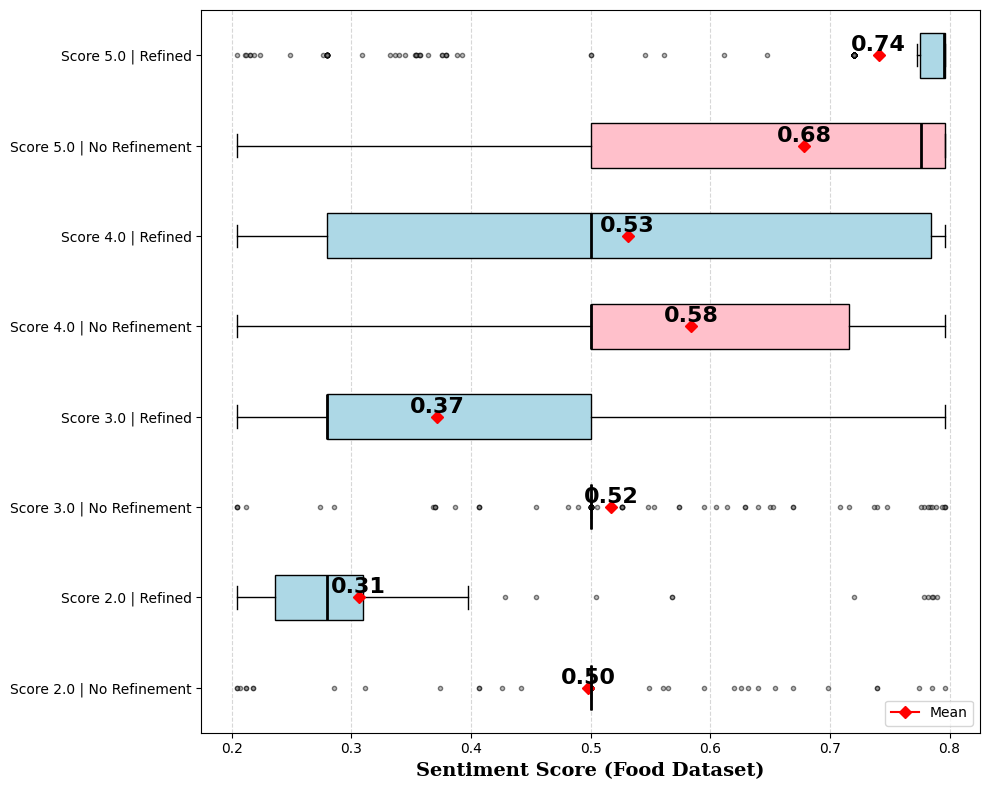

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the scores to include (first 4 distinct ones)
unique_scores = sorted(df_food["Scores"].dropna().unique())[:4]

# Prepare data, labels, and colors
data = []
labels = []
colors = []

for score in unique_scores:
    subset = df_food[df_food["Scores"] == score]

    # No Refinement
    data.append(subset["Overall_Sentiment_NO_refinement"].dropna())
    labels.append(f"Score {score} | No Refinement")
    colors.append("pink")

    # Refined
    data.append(subset["Overall_Sentiment_ReFined"].dropna())
    labels.append(f"Score {score} | Refined")
    colors.append("lightblue")

# Create horizontal boxplots in one canvas
plt.figure(figsize=(10, 8))

# Customize outliers (fliers) to be smaller gray dots
flier_props = dict(marker='o', markersize=3, linestyle='none', markerfacecolor='gray', alpha=0.5)

# Plot the boxplot
box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)

# Apply box colors and emphasize medians
for patch, median, color in zip(box['boxes'], box['medians'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    median.set_color("black")
    median.set_linewidth(2)

# Add mean markers in red and display mean text on top of the red square
for i, d in enumerate(data):
    if len(d) > 0:
        mean_val = np.mean(d)
        # Plot mean as a red diamond
        plt.plot(mean_val, i + 1, marker='D', color='red', label='Mean' if i == 0 else "", markersize=6)

        # Print mean value on top of the red diamond
        # Modify font properties here:
        # fontsize=12: Adjust font size as needed
        # fontweight='bold': Use 'bold' for bold text, or 'normal' for regular text
        # You can change the position of the mean text if necessary by adjusting the x and y positions
        plt.text(mean_val, i + 1, f'{mean_val:.2f}', fontsize=16, fontweight='bold',                                     # 14 or 16
                 ha='center', va='bottom', color='black')

# Aesthetics
#plt.title("Horizontal Sentiment Boxplots per Score (Refined vs No Refinement - Food Dataset)", fontsize=12)
plt.xlabel("Sentiment Score (Food Dataset)", fontsize=14, fontweight='bold', family='serif')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()

# Save figure as high-res JPEG
plt.savefig("Sentiment_Boxplots_Food.jpg", format='jpeg', dpi=800)

# Show plot
plt.show()

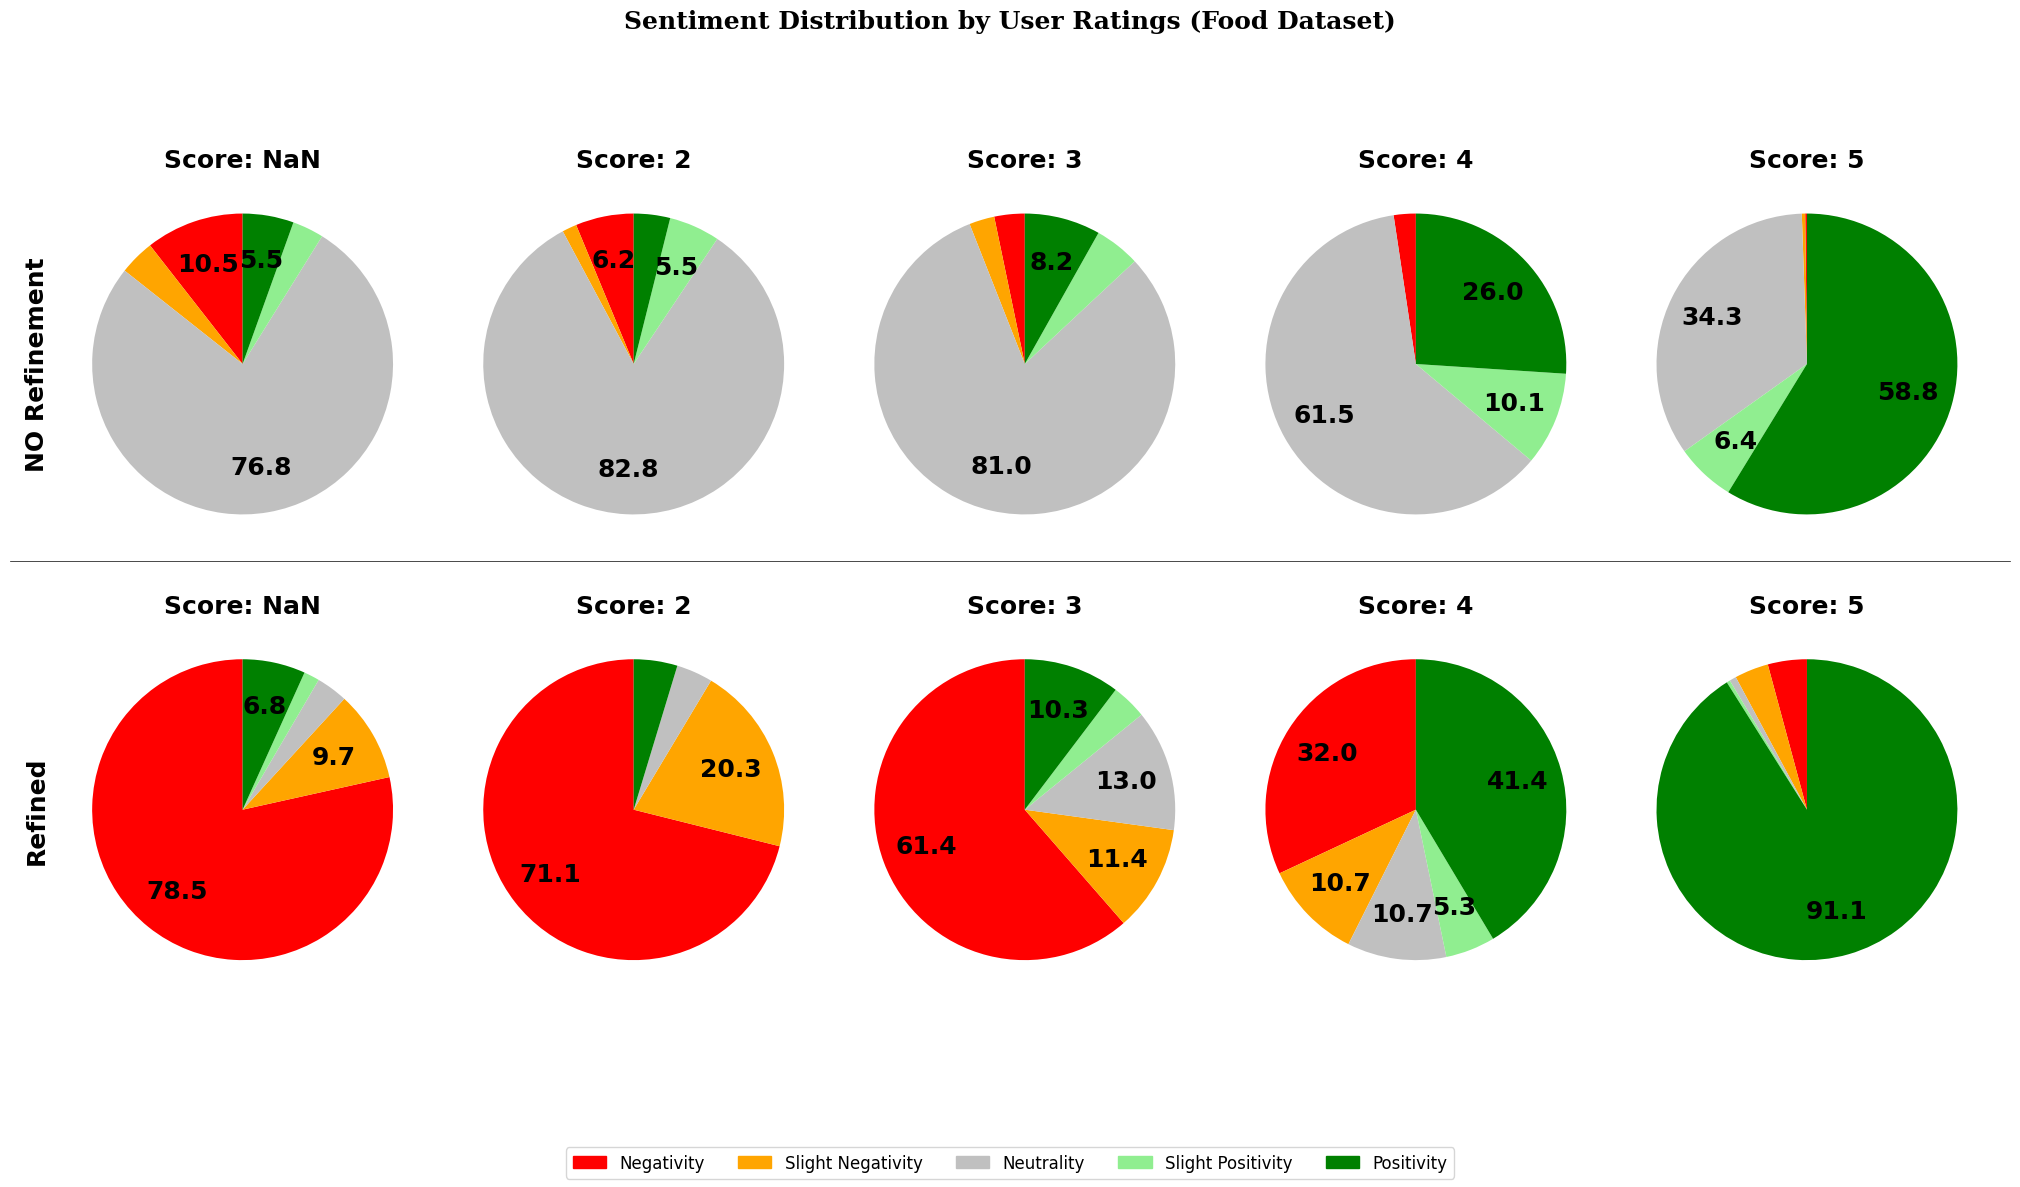

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# Ensure numeric Scores
df_food["Scores"] = pd.to_numeric(df_food["Scores"], errors="coerce")

# Sentiment categories and score bins
sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]
score_values = [np.nan, 2, 3, 4, 5]

# Color mapping
category_colors = {
    "Negativity": "red",
    "Slight Negativity": "orange",
    "Neutrality": "silver",
    "Slight Positivity": "lightgreen",
    "Positivity": "green"
}
colors = [category_colors[cat] for cat in sentiment_categories]

# === PIE TEXT & STYLE CUSTOMIZATION ===
PERCENT_DISTANCE = 0.70
PERCENT_FONTSIZE = 18
LABEL_THRESHOLD = 5  # Only show percentages >= 5%

# === CUSTOM FONTS (EDIT HERE) ===
TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'serif'}     # For main title
SUBTITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'sans-serif'}  # For left-side row labels
PIE_TITLE_FONT = {'fontsize': 18, 'fontweight': 'normal'}  # For chart titles above pies

# New parameter for "Score: X" font size and boldness
SCORE_FONT_SIZE = 18  # Font size for the "Score: X" titles
SCORE_FONT_WEIGHT = 'bold'  # Font weight for "Score: X" titles (options: 'normal', 'bold')

# =======================================

# Custom % formatter with bold text
def autopct_format(pct):
    return f'{pct:.1f}' if pct >= LABEL_THRESHOLD else ''

# Create subplot layout
fig, axs = plt.subplots(2, 5, figsize=(20, 12))
fig.suptitle("Sentiment Distribution by User Ratings (Food Dataset)", **TITLE_FONT)

# Row 1: NO Refinement
for i, score in enumerate(score_values):
    subset = df_food[df_food["Scores"].isna()] if pd.isna(score) else df_food[df_food["Scores"] == score]
    title = "Score: NaN" if pd.isna(score) else f"Score: {int(score)}"
    counts = subset["Overall_Sentiment_NO_refinement_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[0, i].pie(
        counts,
        labels=None,
        autopct=lambda pct: f'{pct:.1f}' if pct >= LABEL_THRESHOLD else '',
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
    )
    axs[0, i].set_title(title, fontsize=SCORE_FONT_SIZE, fontweight=SCORE_FONT_WEIGHT)  # Score title customization

# Row 2: Refined
for i, score in enumerate(score_values):
    subset = df_food[df_food["Scores"].isna()] if pd.isna(score) else df_food[df_food["Scores"] == score]
    title = "Score: NaN" if pd.isna(score) else f"Score: {int(score)}"
    counts = subset["Overall_Sentiment_Refined_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[1, i].pie(
        counts,
        labels=None,
        autopct=lambda pct: f'{pct:.1f}' if pct >= LABEL_THRESHOLD else '',
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
    )
    axs[1, i].set_title(title, fontsize=SCORE_FONT_SIZE, fontweight=SCORE_FONT_WEIGHT)  # Score title customization

# Row labels (left-side)
axs[0, 0].set_ylabel("NO Refinement", **SUBTITLE_FONT)
axs[1, 0].set_ylabel("Refined", **SUBTITLE_FONT)

# Horizontal line between rows
fig.subplots_adjust(hspace=0.35)
line_y = 0.52
fig.canvas.draw()
fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# Legend
legend_patches = [mpatches.Patch(color=category_colors[cat], label=cat) for cat in sentiment_categories]
fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=12)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])

# Save the figure before showing
fig.savefig("Sentiment Distribution by User Ratings (Food Dataset).jpeg", format='jpeg', dpi=800)

plt.show()

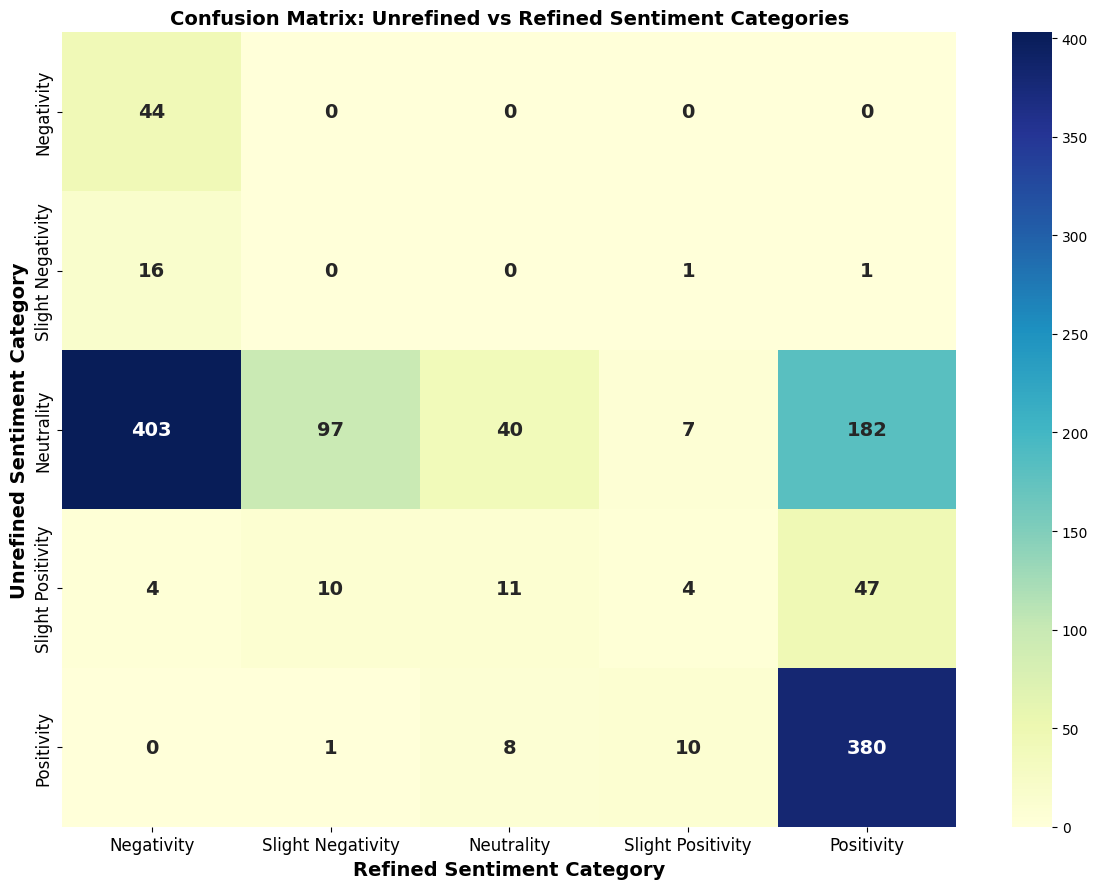

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Ensure you have df_food loaded with the proper columns:
# 'Overall_Sentiment_NO_refinement_Category' and 'Overall_Sentiment_Refined_Category'

# Define category order
sentiment_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Create confusion matrix
cm = confusion_matrix(
    df_food["Overall_Sentiment_NO_refinement_Category"],
    df_food["Overall_Sentiment_Refined_Category"],
    labels=sentiment_order
)

# Create heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap="YlGnBu",
            xticklabels=sentiment_order, yticklabels=sentiment_order,
            annot_kws={"size": 14, "weight": "bold"})  # Annotation styling

# Labeling
plt.title("Confusion Matrix: Unrefined vs Refined Sentiment Categories", fontsize=14, weight='bold')
plt.xlabel("Refined Sentiment Category", fontsize=14, weight='bold')
plt.ylabel("Unrefined Sentiment Category", fontsize=14, weight='bold')

# Ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()

# Save the figure before showing
plt.savefig("Confusion_Matrix_Food.jpeg", format='jpeg', dpi=800)

plt.show()

### **TikTok**

In [ ]:
# # Ensure 'score' column is numeric
# df_tiktok["score"] = pd.to_numeric(df_tiktok["score"], errors='coerce')

# # Define the consistent category order
# category_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# # Count values per category for both sentiment columns
# tiktok_no_ref_counts = df_tiktok["Overall_Sentiment_NO_refinement_Category"].value_counts()
# tiktok_refined_counts = df_tiktok["Overall_Sentiment_Refined_Category"].value_counts()

# # Mean and median scores for NO refinement
# mean_scores_no_ref = df_tiktok.groupby("Overall_Sentiment_NO_refinement_Category")["score"].mean()
# median_scores_no_ref = df_tiktok.groupby("Overall_Sentiment_NO_refinement_Category")["score"].median()

# # Mean and median scores for Refined version
# mean_scores_refined = df_tiktok.groupby("Overall_Sentiment_Refined_Category")["score"].mean()
# median_scores_refined = df_tiktok.groupby("Overall_Sentiment_Refined_Category")["score"].median()

# # Combine everything into one summary DataFrame
# df_tiktok_summary = pd.DataFrame({
#     "NO_Refinement": tiktok_no_ref_counts,
#     "Refined": tiktok_refined_counts,
#     "Mean_Score_NO_Refinement": mean_scores_no_ref,
#     "Median_Score_NO_Refinement": median_scores_no_ref,
#     "Mean_Score_Refined": mean_scores_refined,
#     "Median_Score_Refined": median_scores_refined
# }).reindex(category_order)

# # Fill missing values
# df_tiktok_summary = df_tiktok_summary.fillna(0)

# # Display
# print("=== Enhanced df_tiktok_summary with Mean & Median Scores ===")
# df_tiktok_summary

In [ ]:
# # Ensure relevant columns are numeric
# df_tiktok["score"] = pd.to_numeric(df_tiktok["score"], errors='coerce')
# df_tiktok["Overall_Sentiment_NO_refinement"] = pd.to_numeric(df_tiktok["Overall_Sentiment_NO_refinement"], errors='coerce')
# df_tiktok["Overall_Sentiment_ReFined"] = pd.to_numeric(df_tiktok["Overall_Sentiment_ReFined"], errors='coerce')

# # Group by 'score' and calculate mean and median for each sentiment version
# df_tiktok_score_summary = df_tiktok.groupby("score").agg({
#     "Overall_Sentiment_NO_refinement": ["mean", "median"],
#     "Overall_Sentiment_ReFined": ["mean", "median"]
# })

# # Clean up column names
# df_tiktok_score_summary.columns = [
#     "Mean_NO_Refinement", "Median_NO_Refinement",
#     "Mean_Refined", "Median_Refined"
# ]

# # Display
# print("=== df_tiktok: Mean & Median Sentiment by Score ===")
# df_tiktok_score_summary


In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import pandas as pd
# import numpy as np

# # Ensure numeric 'score' column
# df_tiktok["score"] = pd.to_numeric(df_tiktok["score"], errors="coerce")

# # Sentiment categories and valid score values
# sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]
# score_values = [1, 2, 3, 4, 5]

# # Color mapping
# category_colors = {
#     "Negativity": "red",
#     "Slight Negativity": "orange",
#     "Neutrality": "silver",
#     "Slight Positivity": "lightgreen",
#     "Positivity": "green"
# }
# colors = [category_colors[cat] for cat in sentiment_categories]

# # === TEXT & STYLE SETTINGS (same as before) ===
# PERCENT_DISTANCE = 0.70
# PERCENT_FONTSIZE = 14
# LABEL_THRESHOLD = 5

# TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'serif'}
# SUBTITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'sans-serif'}
# PIE_TITLE_FONT = {'fontsize': 16, 'fontweight': 'normal'}
# # ==============================================

# # Custom format for percentage labels
# def autopct_format(pct):
#     return f'{pct:.1f}' if pct >= LABEL_THRESHOLD else ''

# # Create subplot grid
# fig, axs = plt.subplots(2, 5, figsize=(20, 12))
# fig.suptitle("Emotion Distribution within Each Score (TikTok Dataset)", **TITLE_FONT)

# # Row 1: NO Refinement
# for i, score in enumerate(score_values):
#     subset = df_tiktok[df_tiktok["score"] == score]
#     title = f"Score: {int(score)}"
#     counts = subset["Overall_Sentiment_NO_refinement_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

#     axs[0, i].pie(
#         counts,
#         labels=None,
#         autopct=autopct_format,
#         startangle=90,
#         colors=colors,
#         pctdistance=PERCENT_DISTANCE,
#         textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
#     )
#     axs[0, i].set_title(title, **PIE_TITLE_FONT)

# # Row 2: Refined
# for i, score in enumerate(score_values):
#     subset = df_tiktok[df_tiktok["score"] == score]
#     title = f"Score: {int(score)}"
#     counts = subset["Overall_Sentiment_Refined_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

#     axs[1, i].pie(
#         counts,
#         labels=None,
#         autopct=autopct_format,
#         startangle=90,
#         colors=colors,
#         pctdistance=PERCENT_DISTANCE,
#         textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
#     )
#     axs[1, i].set_title(title, **PIE_TITLE_FONT)

# # Row labels
# axs[0, 0].set_ylabel("NO Refinement", **SUBTITLE_FONT)
# axs[1, 0].set_ylabel("Refined", **SUBTITLE_FONT)

# # Horizontal divider
# fig.subplots_adjust(hspace=0.35)
# line_y = 0.52
# fig.canvas.draw()
# fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# # Legend
# legend_patches = [mpatches.Patch(color=category_colors[cat], label=cat) for cat in sentiment_categories]
# fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=12)

# plt.tight_layout(rect=[0, 0.08, 1, 0.95])
# plt.show()


In [ ]:
# import matplotlib.pyplot as plt
# import pandas as pd
# import numpy as np

# # Define score-based color mapping
# score_colors = {
#     5: "blue",
#     4: "lightblue",
#     3: "silver",
#     2: "orange",
#     1: "red",
#     np.nan: "silver"  # for missing values (neutral, just in case)
# }

# # Sentiment categories
# sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# # === MODIFY THESE TO CONTROL PERCENTAGE APPEARANCE ===
# PERCENT_DISTANCE = 0.70  # Distance from center (0=center, 1=on the edge)
# PERCENT_FONTSIZE = 12    # Font size for the percentage labels
# # =====================================================

# # Custom format function (removes percent sign)
# def autopct_format(pct):
#     return f'{pct:.1f}' if pct > 0 else ''

# # Create subplot grid
# fig, axs = plt.subplots(2, 5, figsize=(20, 12))  # taller figure for spacing
# fig.suptitle("Score Distribution within Each Emotion (TikTok Dataset)", fontsize=16)

# # First row: NO Refinement
# for i, cat in enumerate(sentiment_categories):
#     subset = df_tiktok[df_tiktok["Overall_Sentiment_NO_refinement_Category"] == cat]
#     counts = subset["score"].value_counts(dropna=False).sort_index()

#     labels = [f"NaN" if pd.isna(x) else str(int(x)) for x in counts.index]
#     colors = [score_colors[np.nan] if pd.isna(x) else score_colors.get(int(x), "white") for x in counts.index]

#     axs[0, i].pie(
#         counts,
#         labels=labels,
#         autopct=autopct_format,
#         startangle=90,
#         colors=colors,
#         pctdistance=PERCENT_DISTANCE,
#         textprops={'fontsize': PERCENT_FONTSIZE}
#     )
#     axs[0, i].set_title(cat)

# # Second row: Refined
# for i, cat in enumerate(sentiment_categories):
#     subset = df_tiktok[df_tiktok["Overall_Sentiment_Refined_Category"] == cat]
#     counts = subset["score"].value_counts(dropna=False).sort_index()

#     labels = [f"NaN" if pd.isna(x) else str(int(x)) for x in counts.index]
#     colors = [score_colors[np.nan] if pd.isna(x) else score_colors.get(int(x), "white") for x in counts.index]

#     axs[1, i].pie(
#         counts,
#         labels=labels,
#         autopct=autopct_format,
#         startangle=90,
#         colors=colors,
#         pctdistance=PERCENT_DISTANCE,
#         textprops={'fontsize': PERCENT_FONTSIZE}
#     )
#     axs[1, i].set_title(cat)

# # Axis labels
# axs[0, 0].set_ylabel("NO Refinement")
# axs[1, 0].set_ylabel("Refined")

# # Add vertical space and a horizontal line between rows
# fig.subplots_adjust(hspace=0.35)
# line_y = 0.52
# fig.canvas.draw()
# fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()


### **Trip Advisor**

In [ ]:
# Ensure 'Rating' column is numeric
df_trip_advisor["Rating"] = pd.to_numeric(df_trip_advisor["Rating"], errors='coerce')

# Define the consistent category order
category_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Count values per category for both sentiment columns
trip_no_ref_counts = df_trip_advisor["Overall_Sentiment_NO_refinement_Category"].value_counts()
trip_refined_counts = df_trip_advisor["Overall_Sentiment_Refined_Category"].value_counts()

# Mean and median scores for NO refinement
mean_scores_no_ref = df_trip_advisor.groupby("Overall_Sentiment_NO_refinement_Category")["Rating"].mean()
median_scores_no_ref = df_trip_advisor.groupby("Overall_Sentiment_NO_refinement_Category")["Rating"].median()

# Mean and median scores for Refined version
mean_scores_refined = df_trip_advisor.groupby("Overall_Sentiment_Refined_Category")["Rating"].mean()
median_scores_refined = df_trip_advisor.groupby("Overall_Sentiment_Refined_Category")["Rating"].median()

# Combine everything into one summary DataFrame
df_trip_summary = pd.DataFrame({
    "NO_Refinement": trip_no_ref_counts,
    "Refined": trip_refined_counts,
    "Mean_Score_NO_Refinement": mean_scores_no_ref,
    "Median_Score_NO_Refinement": median_scores_no_ref,
    "Mean_Score_Refined": mean_scores_refined,
    "Median_Score_Refined": median_scores_refined
}).reindex(category_order)

# Fill missing values
df_trip_summary = df_trip_summary.fillna(0)

# Display
print("=== Enhanced df_trip_summary with Mean & Median Scores ===")
df_trip_summary

=== Enhanced df_trip_summary with Mean & Median Scores ===


,NO_Refinement,Refined,Mean_Score_NO_Refinement,Median_Score_NO_Refinement,Mean_Score_Refined,Median_Score_Refined
Negativity,9,3146,1.222222,1.0,2.129371,2.0
Slight Negativity,16,1795,1.187500,1.0,3.101393,3.0
Neutrality,16071,2483,3.801319,4.0,3.881595,4.0
Slight Positivity,2604,656,4.465054,5.0,4.111280,4.0
Positivity,1791,12411,4.599107,5.0,4.543067,5.0


In [ ]:
# Ensure relevant columns are numeric
df_trip_advisor["Rating"] = pd.to_numeric(df_trip_advisor["Rating"], errors='coerce')
df_trip_advisor["Overall_Sentiment_NO_refinement"] = pd.to_numeric(df_trip_advisor["Overall_Sentiment_NO_refinement"], errors='coerce')
df_trip_advisor["Overall_Sentiment_ReFined"] = pd.to_numeric(df_trip_advisor["Overall_Sentiment_ReFined"], errors='coerce')

# Define custom aggregation functions
agg_funcs = {
    "Overall_Sentiment_NO_refinement": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max'],
    "Overall_Sentiment_ReFined": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
}

# Group by Rating and apply the aggregation
df_trip_score_summary = df_trip_advisor.groupby("Rating").agg(agg_funcs)

# Rename columns for clarity
df_trip_score_summary.columns = [
    "Min_NO_Refinement", "Mean_NO_Refinement", "Q1_NO_Refinement", "Median_NO_Refinement", "Q3_NO_Refinement", "Max_NO_Refinement",
    "Min_Refined", "Mean_Refined", "Q1_Refined", "Median_Refined", "Q3_Refined", "Max_Refined"
]

# Display the enhanced summary table
print("=== df_trip_advisor: Sentiment Summary Stats by Rating ===")
df_trip_score_summary

=== df_trip_advisor: Sentiment Summary Stats by Rating ===


,Min_NO_Refinement,Mean_NO_Refinement,Q1_NO_Refinement,Median_NO_Refinement,Q3_NO_Refinement,Max_NO_Refinement,Min_Refined,Mean_Refined,Q1_Refined,Median_Refined,Q3_Refined,Max_Refined
Rating,,,,,,,,,,,,
1,0.204167,0.499901,0.5,0.5,0.500000,0.793131,0.204365,0.281852,0.229957,0.263546,0.289927,0.790236
2,0.222268,0.505981,0.5,0.5,0.500000,0.789404,0.204167,0.341515,0.266876,0.292562,0.332549,0.794936
3,0.366890,0.524239,0.5,0.5,0.500000,0.795426,0.205619,0.492867,0.301940,0.500000,0.769675,0.795833
4,0.411776,0.551832,0.5,0.5,0.592250,0.795833,0.214312,0.670299,0.500000,0.776065,0.781116,0.795833
5,0.500000,0.565557,0.5,0.5,0.624405,0.795833,0.211059,0.732628,0.774780,0.778245,0.783820,0.795833


<ipython-input-532-1a31df623ddd>:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)


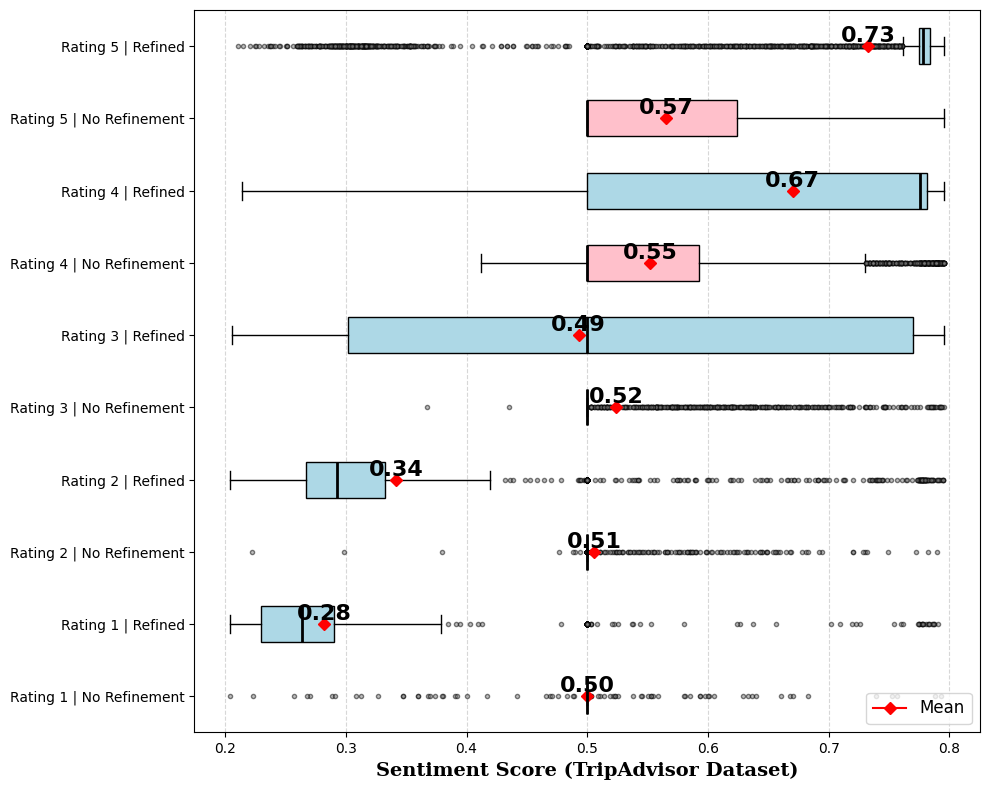

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the ratings to include (first 5 distinct ones)
unique_ratings = sorted(df_trip_advisor["Rating"].dropna().unique())[:5]

# Prepare data, labels, and colors
data = []
labels = []
colors = []

for rating in unique_ratings:
    subset = df_trip_advisor[df_trip_advisor["Rating"] == rating]

    # No Refinement
    data.append(subset["Overall_Sentiment_NO_refinement"].dropna())
    labels.append(f"Rating {rating} | No Refinement")
    colors.append("pink")

    # Refined
    data.append(subset["Overall_Sentiment_ReFined"].dropna())
    labels.append(f"Rating {rating} | Refined")
    colors.append("lightblue")

# Create horizontal boxplots
plt.figure(figsize=(10, 8))

# Customize outliers (fliers) to be smaller gray dots
flier_props = dict(marker='o', markersize=3, linestyle='none', markerfacecolor='gray', alpha=0.5)

# Plot the boxplots
box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)

# Apply box colors and emphasize medians
for patch, median, color in zip(box['boxes'], box['medians'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    median.set_color("black")
    median.set_linewidth(2)

# Add mean markers in red and display mean text on top of the red diamond
for i, d in enumerate(data):
    if len(d) > 0:
        mean_val = np.mean(d)
        # Plot mean as a red diamond
        plt.plot(mean_val, i + 1, marker='D', color='red', label='Mean' if i == 0 else "", markersize=6)

        # Print mean value on top of the red diamond
        plt.text(mean_val, i + 1, f'{mean_val:.2f}', fontsize=16, fontweight='bold',  # 14 or 16
                 ha='center', va='bottom', color='black')

# Aesthetic enhancements with custom fonts
#plt.title("Horizontal Sentiment Boxplots per Rating (Refined vs No Refinement - TripAdvisor)", fontsize=12, fontweight='bold', family='serif')
plt.xlabel("Sentiment Score (TripAdvisor Dataset)", fontsize=14, fontweight='bold', family='serif')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add a legend
plt.legend(loc='lower right', fontsize=12)

# Apply tight layout for the plot
plt.tight_layout()

# Save figure as high-res JPEG
plt.savefig("Sentiment_Boxplots_TripAdvisor.jpg", format='jpeg', dpi=800)

# Show the plot
plt.show()

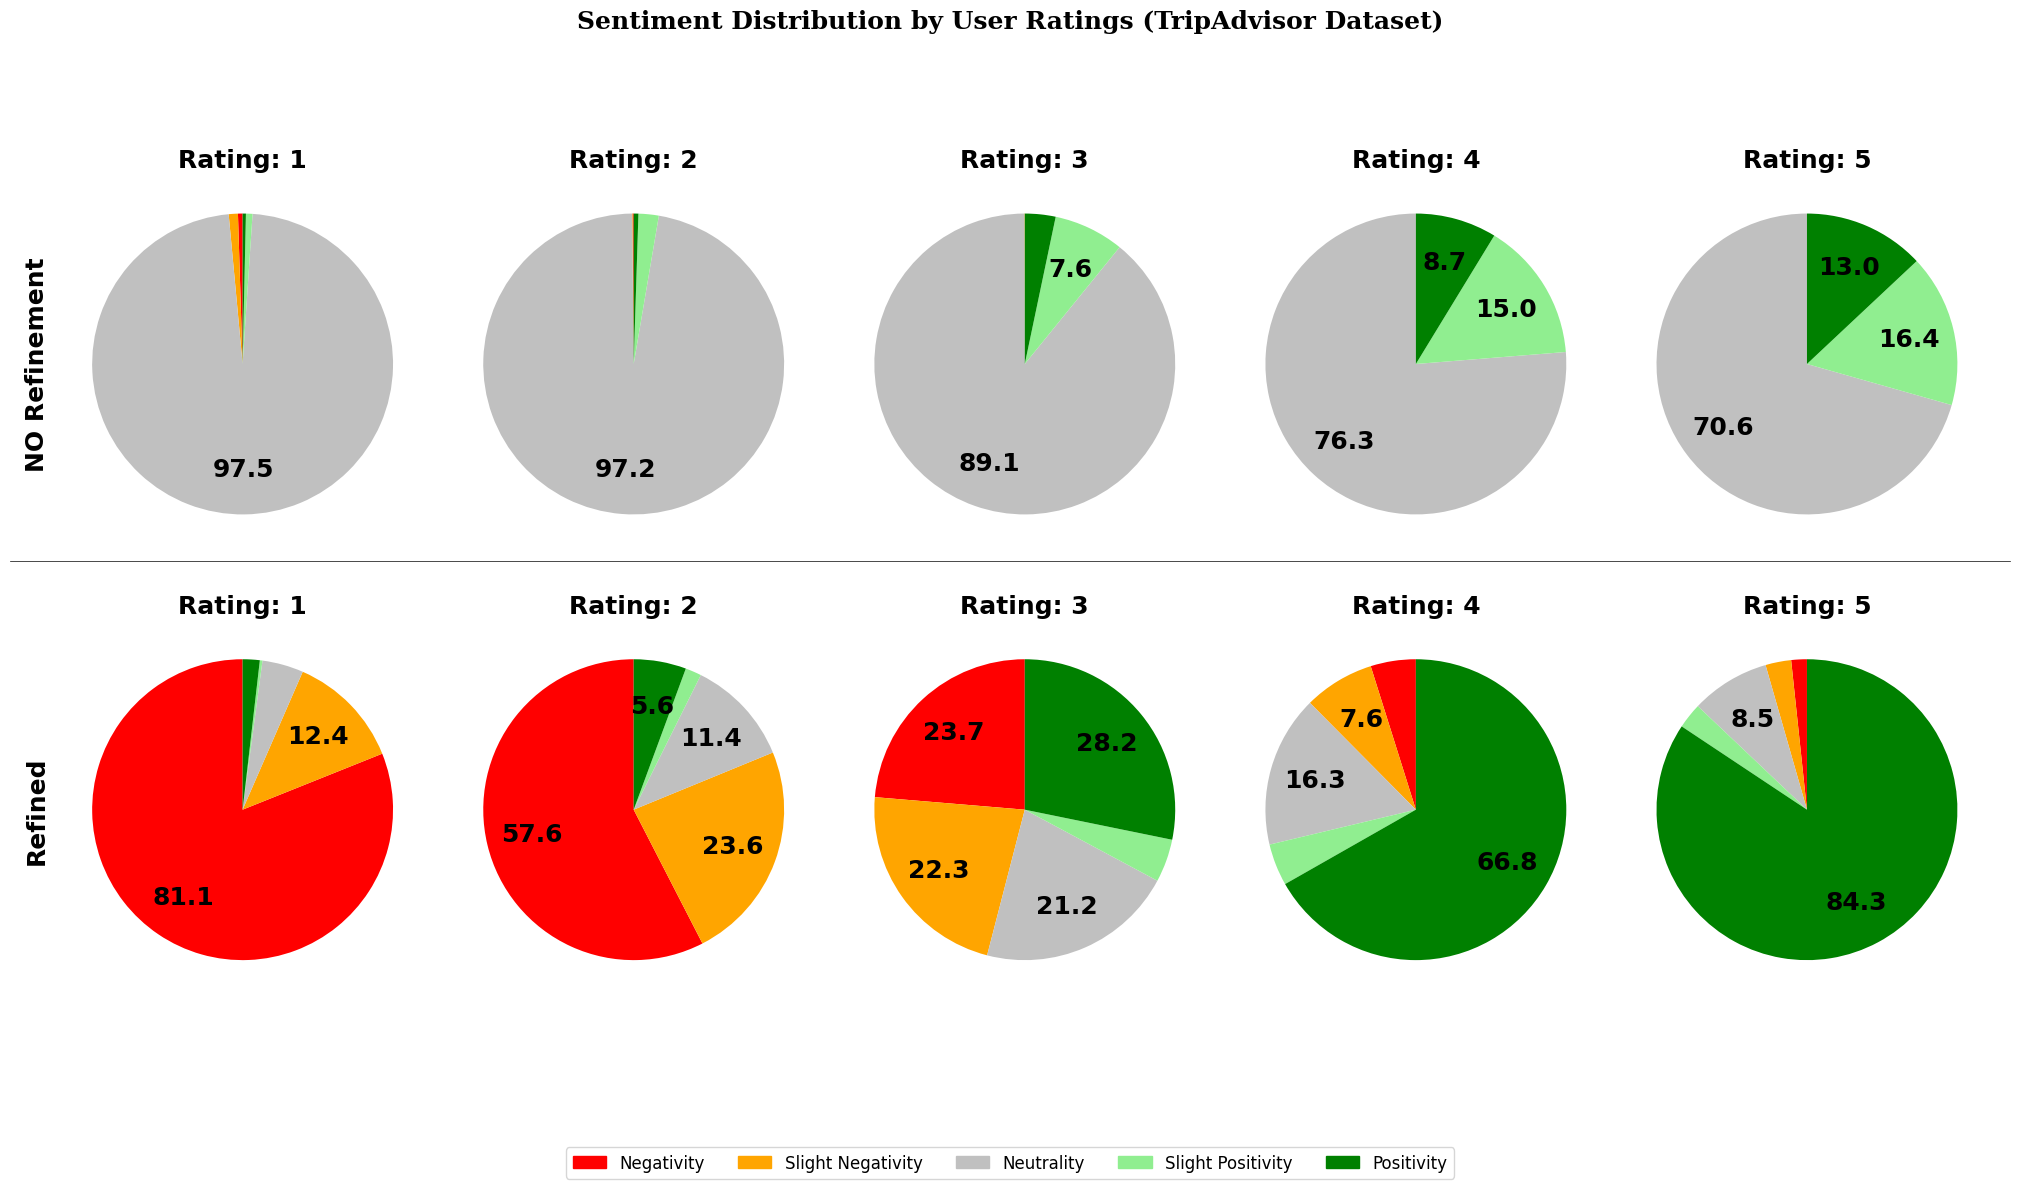

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Ensure numeric 'Rating' column
df_trip_advisor["Rating"] = pd.to_numeric(df_trip_advisor["Rating"], errors="coerce")

# Sentiment categories and score values
sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]
score_values = [1, 2, 3, 4, 5]

# Color mapping
category_colors = {
    "Negativity": "red",
    "Slight Negativity": "orange",
    "Neutrality": "silver",
    "Slight Positivity": "lightgreen",
    "Positivity": "green"
}
colors = [category_colors[cat] for cat in sentiment_categories]

# === STYLING SETTINGS ===
PERCENT_DISTANCE = 0.70
PERCENT_FONTSIZE = 18  # Font size for the percentages
LABEL_THRESHOLD = 5  # Show % if >= 5

# Title and label font settings
TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'serif'}
SUBTITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'sans-serif'}
PIE_TITLE_FONT = {'fontsize': 16, 'fontweight': 'normal'}
SCORE_TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold'}  # For "Score: X" titles

# ========================

# Format function for % labels
def autopct_format(pct):
    return f'{pct:.1f}' if pct >= LABEL_THRESHOLD else ''

# Create plot grid
fig, axs = plt.subplots(2, 5, figsize=(20, 12))
fig.suptitle("Sentiment Distribution by User Ratings (TripAdvisor Dataset)", **TITLE_FONT)

# Row 1: NO Refinement
for i, score in enumerate(score_values):
    subset = df_trip_advisor[df_trip_advisor["Rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_NO_refinement_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[0, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
    )
    axs[0, i].set_title(title, **SCORE_TITLE_FONT)

# Row 2: Refined
for i, score in enumerate(score_values):
    subset = df_trip_advisor[df_trip_advisor["Rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_Refined_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[1, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}
    )
    axs[1, i].set_title(title, **SCORE_TITLE_FONT)

# Row labels
axs[0, 0].set_ylabel("NO Refinement", **SUBTITLE_FONT)
axs[1, 0].set_ylabel("Refined", **SUBTITLE_FONT)

# Horizontal separator
fig.subplots_adjust(hspace=0.35)
line_y = 0.52
fig.canvas.draw()
fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# Legend
legend_patches = [mpatches.Patch(color=category_colors[cat], label=cat) for cat in sentiment_categories]
fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=12)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])

# Save the figure with title as filename, 800 dpi, and JPEG format
fig.savefig("Sentiment Distribution by User Ratings (TripAdvisor Dataset).jpeg", format='jpeg', dpi=800)

# Show the plot
plt.show()

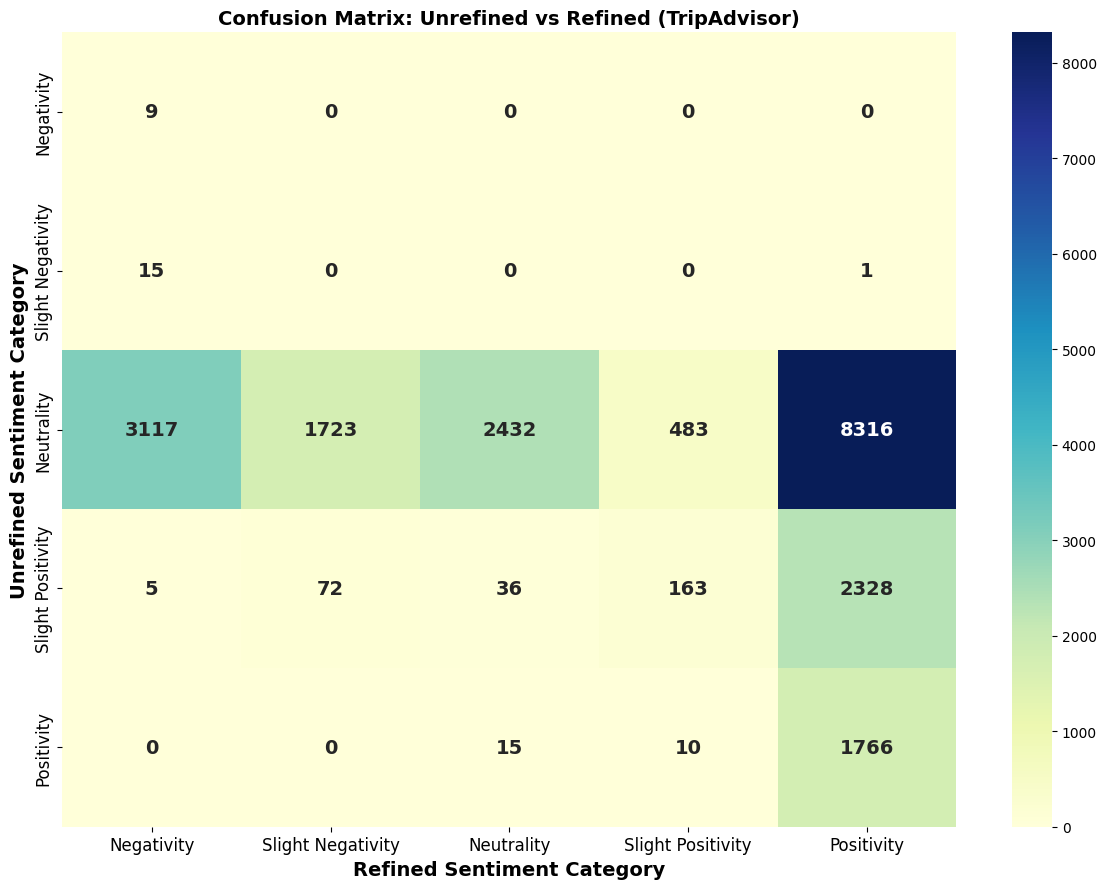

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Define sentiment order
sentiment_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Confusion matrix for trip advisor
cm_trip = confusion_matrix(
    df_trip_advisor["Overall_Sentiment_NO_refinement_Category"],
    df_trip_advisor["Overall_Sentiment_Refined_Category"],
    labels=sentiment_order
)

# Plot
plt.figure(figsize=(12, 9))
sns.heatmap(cm_trip, annot=True, fmt='d', cmap="YlGnBu",
            xticklabels=sentiment_order, yticklabels=sentiment_order,
            annot_kws={"size": 14, "weight": "bold"})

plt.title("Confusion Matrix: Unrefined vs Refined (TripAdvisor)", fontsize=14, weight='bold')
plt.xlabel("Refined Sentiment Category", fontsize=14, weight='bold')
plt.ylabel("Unrefined Sentiment Category", fontsize=14, weight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()

# Save the figure before showing
plt.savefig("Confusion_Matrix_Trip_Advsior.jpeg", format='jpeg', dpi=800)

plt.show()

### **Women's Clothing Reviews**

In [ ]:
# Ensure 'Rating' column is numeric
df_women_clothing["Rating"] = pd.to_numeric(df_women_clothing["Rating"], errors='coerce')

# Define consistent sentiment category order
category_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Count how many reviews fall into each sentiment category
no_ref_counts = df_women_clothing["Overall_Sentiment_NO_refinement_Category"].value_counts()
refined_counts = df_women_clothing["Overall_Sentiment_Refined_Category"].value_counts()

# Compute mean and median Rating for each category (NO refinement)
mean_scores_no_ref = df_women_clothing.groupby("Overall_Sentiment_NO_refinement_Category")["Rating"].mean()
median_scores_no_ref = df_women_clothing.groupby("Overall_Sentiment_NO_refinement_Category")["Rating"].median()

# Compute mean and median Rating for each category (Refined)
mean_scores_refined = df_women_clothing.groupby("Overall_Sentiment_Refined_Category")["Rating"].mean()
median_scores_refined = df_women_clothing.groupby("Overall_Sentiment_Refined_Category")["Rating"].median()

# Combine everything into a single summary DataFrame
df_women_summary = pd.DataFrame({
    "NO_Refinement": no_ref_counts,
    "Refined": refined_counts,
    "Mean_Score_NO_Refinement": mean_scores_no_ref,
    "Median_Score_NO_Refinement": median_scores_no_ref,
    "Mean_Score_Refined": mean_scores_refined,
    "Median_Score_Refined": median_scores_refined
}).reindex(category_order).fillna(0)

# Display the summary
print("=== df_women_clothing: Sentiment Category Summary ===")
df_women_summary

=== df_women_clothing: Sentiment Category Summary ===


,NO_Refinement,Refined,Mean_Score_NO_Refinement,Median_Score_NO_Refinement,Mean_Score_Refined,Median_Score_Refined
Negativity,16,2002,2.500000,2.5,2.754246,3.0
Slight Negativity,30,2106,3.033333,3.0,2.974359,3.0
Neutrality,14293,1941,4.004128,4.0,3.605873,4.0
Slight Positivity,3686,648,4.358926,5.0,3.765432,4.0
Positivity,5461,16789,4.599707,5.0,4.606052,5.0


In [ ]:
# Ensure all required columns are numeric
df_women_clothing["Rating"] = pd.to_numeric(df_women_clothing["Rating"], errors='coerce')
df_women_clothing["Overall_Sentiment_NO_refinement"] = pd.to_numeric(df_women_clothing["Overall_Sentiment_NO_refinement"], errors='coerce')
df_women_clothing["Overall_Sentiment_ReFined"] = pd.to_numeric(df_women_clothing["Overall_Sentiment_ReFined"], errors='coerce')

# Define aggregation functions
agg_funcs = {
    "Overall_Sentiment_NO_refinement": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max'],
    "Overall_Sentiment_ReFined": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
}

# Group by Rating and apply aggregations
df_women_score_summary = df_women_clothing.groupby("Rating").agg(agg_funcs)

# Rename columns for clarity
df_women_score_summary.columns = [
    "Min_NO_Refinement", "Mean_NO_Refinement", "Q1_NO_Refinement", "Median_NO_Refinement", "Q3_NO_Refinement", "Max_NO_Refinement",
    "Min_Refined", "Mean_Refined", "Q1_Refined", "Median_Refined", "Q3_Refined", "Max_Refined"
]

# Display the summary table
print("=== df_women_clothing: Sentiment Summary Stats by Rating ===")
df_women_score_summary

=== df_women_clothing: Sentiment Summary Stats by Rating ===


,Min_NO_Refinement,Mean_NO_Refinement,Q1_NO_Refinement,Median_NO_Refinement,Q3_NO_Refinement,Max_NO_Refinement,Min_Refined,Mean_Refined,Q1_Refined,Median_Refined,Q3_Refined,Max_Refined
Rating,,,,,,,,,,,,
1,0.205802,0.529404,0.5,0.500000,0.500000,0.794198,0.204167,0.390682,0.269320,0.320171,0.500000,0.795833
2,0.210614,0.542733,0.5,0.500000,0.560849,0.795833,0.204167,0.426806,0.282690,0.344103,0.517351,0.795833
3,0.213619,0.552764,0.5,0.500000,0.593271,0.795833,0.204167,0.502551,0.307002,0.500000,0.769614,0.795833
4,0.284212,0.580108,0.5,0.500000,0.660883,0.795833,0.205111,0.667408,0.523683,0.776365,0.784188,0.795833
5,0.218006,0.613925,0.5,0.583773,0.734512,0.795833,0.204167,0.752197,0.775601,0.781003,0.790281,0.795833


<ipython-input-537-aaaaf6b3b906>:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)


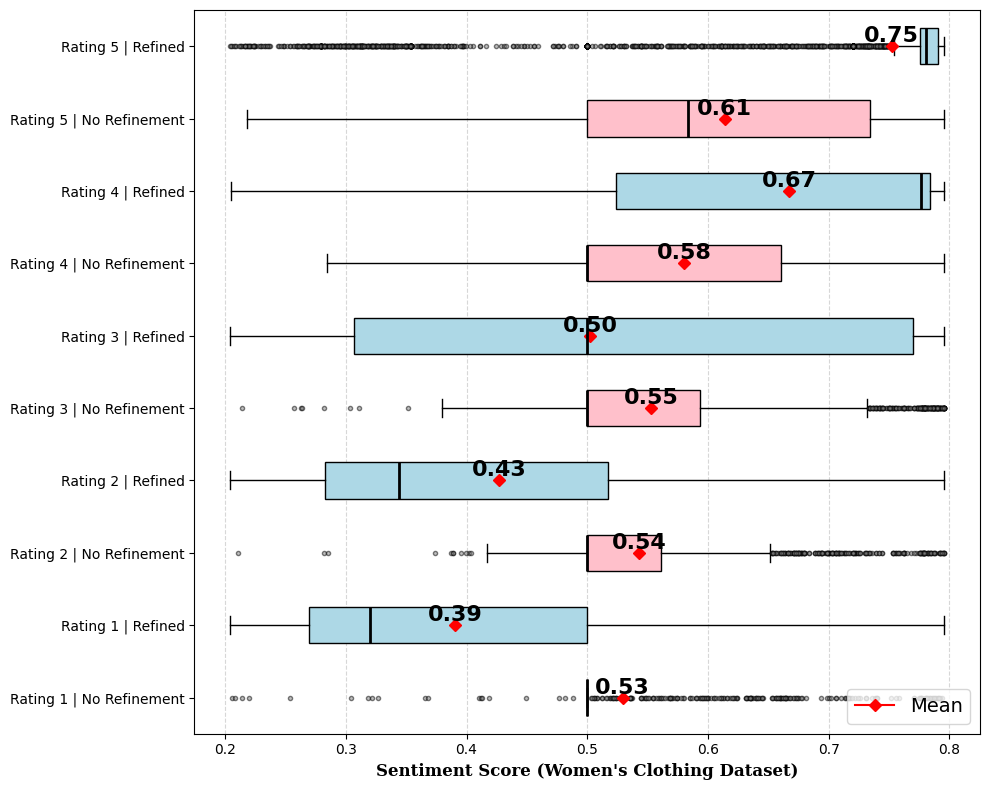

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure numeric 'Rating' column
df_women_clothing["Rating"] = pd.to_numeric(df_women_clothing["Rating"], errors="coerce")

# Define the ratings to include (first 5 distinct ones)
unique_ratings = sorted(df_women_clothing["Rating"].dropna().unique())[:5]

# Prepare data, labels, and colors
data = []
labels = []
colors = []

for rating in unique_ratings:
    subset = df_women_clothing[df_women_clothing["Rating"] == rating]

    # No Refinement
    data.append(subset["Overall_Sentiment_NO_refinement"].dropna())
    labels.append(f"Rating {rating} | No Refinement")
    colors.append("pink")

    # Refined
    data.append(subset["Overall_Sentiment_ReFined"].dropna())
    labels.append(f"Rating {rating} | Refined")
    colors.append("lightblue")

# Create horizontal boxplots
plt.figure(figsize=(10, 8))

# Customize outliers (fliers) to be smaller gray dots
flier_props = dict(marker='o', markersize=3, linestyle='none', markerfacecolor='gray', alpha=0.5)

# Plot boxplots
box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)

# Apply box colors and emphasize medians
for patch, median, color in zip(box['boxes'], box['medians'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    median.set_color("black")
    median.set_linewidth(2)

# Add red mean markers and numeric mean values
for i, d in enumerate(data):
    if len(d) > 0:
        mean_val = np.mean(d)
        plt.plot(mean_val, i + 1, marker='D', color='red', label='Mean' if i == 0 else "", markersize=6)

        # Display mean value above the red diamond
        plt.text(mean_val, i + 1, f'{mean_val:.2f}', fontsize=16, fontweight='bold',  # Font size and boldness for mean
                 ha='center', va='bottom', color='black')

# Apply updated font sizes and boldness as per your style guidelines
# plt.title("Horizontal Sentiment Boxplots per Rating (Refined vs No Refinement - Women Clothing)",
#           fontsize=12, fontweight='bold', family='serif')
plt.xlabel("Sentiment Score (Women's Clothing Dataset)", fontsize=12, fontweight='bold', family='serif')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add a legend with updated font size
plt.legend(loc='lower right', fontsize=14)

# Apply tight layout for the plot
plt.tight_layout()

# Save figure with title as filename, 800 dpi, and JPEG format
plt.savefig("Sentiment_Boxplots_Womens_Clothing.jpg", format='jpeg', dpi=800)

# Show plot
plt.show()

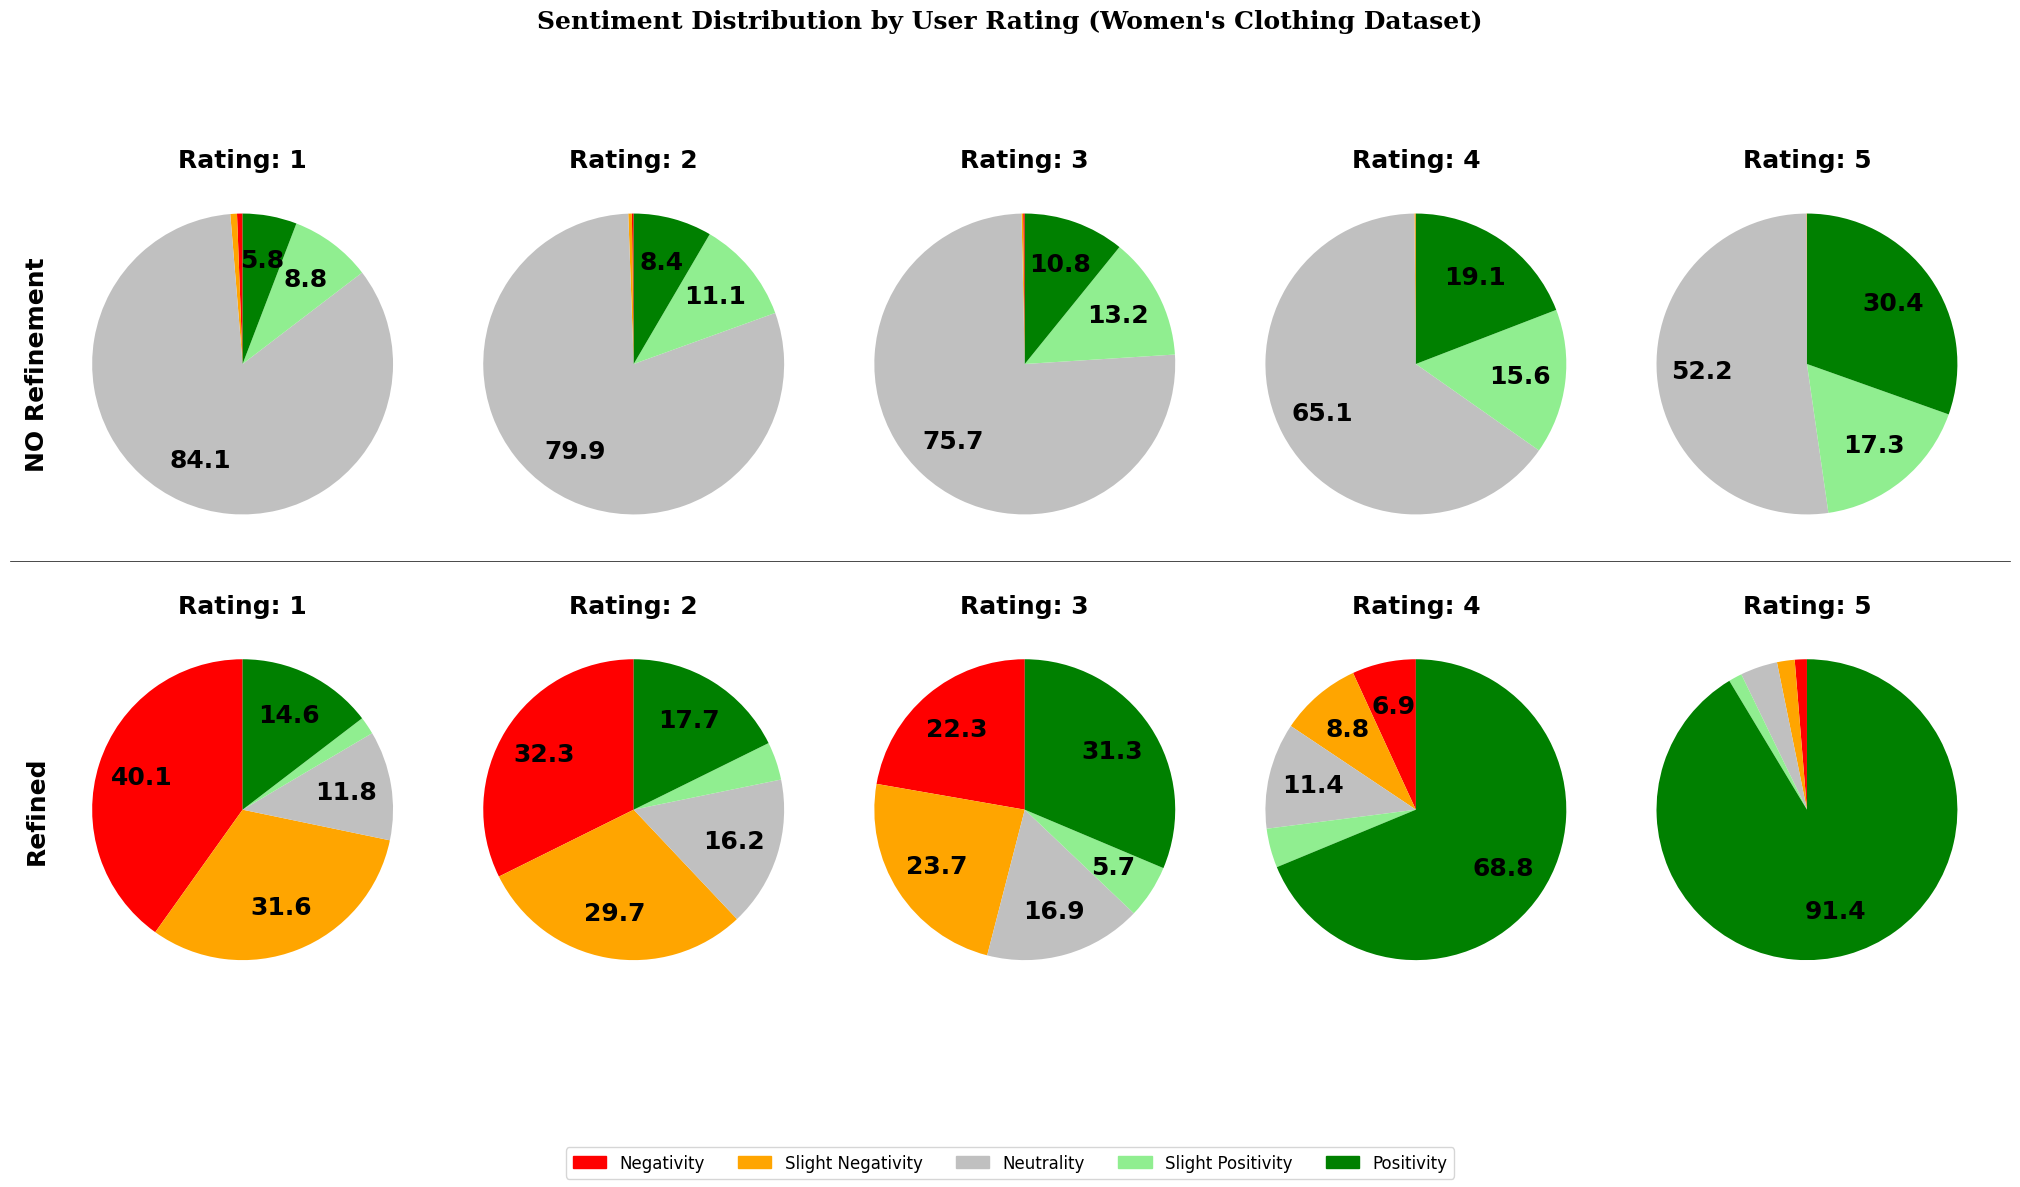

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Ensure numeric 'Rating' column
df_women_clothing["Rating"] = pd.to_numeric(df_women_clothing["Rating"], errors="coerce")

# Categories & Score values
sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]
score_values = [1, 2, 3, 4, 5]

# Color mapping
category_colors = {
    "Negativity": "red",
    "Slight Negativity": "orange",
    "Neutrality": "silver",
    "Slight Positivity": "lightgreen",
    "Positivity": "green"
}
colors = [category_colors[cat] for cat in sentiment_categories]

# === STYLING SETTINGS ===
PERCENT_DISTANCE = 0.70
PERCENT_FONTSIZE = 18  # Font size for percentage text
LABEL_THRESHOLD = 5  # Show percentages greater than or equal to 5%

TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'serif'}  # Title font size and boldness
SUBTITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'sans-serif'}  # Subtitle font size and boldness
PIE_TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold'}  # Pie title font settings
# =========================

# Format for percentage values
def autopct_format(pct):
    return f'{pct:.1f}' if pct >= LABEL_THRESHOLD else ''

# Subplot layout
fig, axs = plt.subplots(2, 5, figsize=(20, 12))
fig.suptitle("Sentiment Distribution by User Rating (Women's Clothing Dataset)", **TITLE_FONT)

# Row 1: NO Refinement
for i, score in enumerate(score_values):
    subset = df_women_clothing[df_women_clothing["Rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_NO_refinement_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[0, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}  # Set font size and boldness for percentages
    )
    axs[0, i].set_title(title, **PIE_TITLE_FONT)

# Row 2: Refined
for i, score in enumerate(score_values):
    subset = df_women_clothing[df_women_clothing["Rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_Refined_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[1, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}  # Set font size and boldness for percentages
    )
    axs[1, i].set_title(title, **PIE_TITLE_FONT)

# Y-axis labels
axs[0, 0].set_ylabel("NO Refinement", **SUBTITLE_FONT)
axs[1, 0].set_ylabel("Refined", **SUBTITLE_FONT)

# Horizontal separator
fig.subplots_adjust(hspace=0.35)
line_y = 0.52
fig.canvas.draw()
fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# Legend
legend_patches = [mpatches.Patch(color=category_colors[cat], label=cat) for cat in sentiment_categories]
fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=12)  # Set legend font size

# Apply tight layout for the plot
plt.tight_layout(rect=[0, 0.08, 1, 0.95])

# Save the figure with the title as the filename, 800 dpi, and JPEG format
fig.savefig("Sentiment Distribution by User Ratings (Womens Clothing Dataset).jpeg", format='jpeg', dpi=800)

# Show the plot
plt.show()

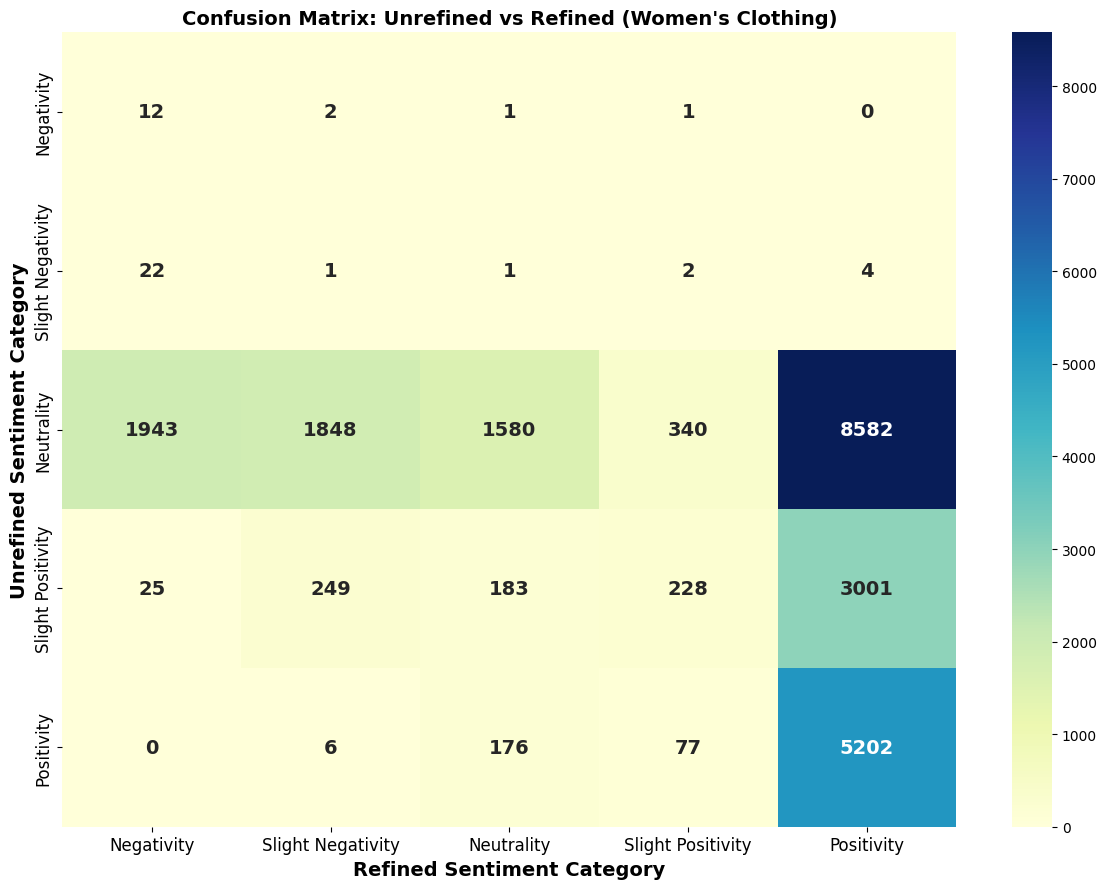

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Define sentiment order
sentiment_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Confusion matrix for women's clothing
cm_women = confusion_matrix(
    df_women_clothing["Overall_Sentiment_NO_refinement_Category"],
    df_women_clothing["Overall_Sentiment_Refined_Category"],
    labels=sentiment_order
)

# Plot
plt.figure(figsize=(12, 9))
sns.heatmap(cm_women, annot=True, fmt='d', cmap="YlGnBu",
            xticklabels=sentiment_order, yticklabels=sentiment_order,
            annot_kws={"size": 14, "weight": "bold"})

plt.title("Confusion Matrix: Unrefined vs Refined (Women's Clothing)", fontsize=14, weight='bold')
plt.xlabel("Refined Sentiment Category", fontsize=14, weight='bold')
plt.ylabel("Unrefined Sentiment Category", fontsize=14, weight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()

# Save the figure before showing
plt.savefig("Confusion_Matrix_Women_Clothing.jpeg", format='jpeg', dpi=800)

plt.show()

### **FlipKart**

In [ ]:
# Ensure 'rating' column is numeric
df_Flipkart["rating"] = pd.to_numeric(df_Flipkart["rating"], errors='coerce')

# Define consistent sentiment category order
category_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Count how many reviews fall into each sentiment category
no_ref_counts = df_Flipkart["Overall_Sentiment_NO_refinement_Category"].value_counts()
refined_counts = df_Flipkart["Overall_Sentiment_Refined_Category"].value_counts()

# Compute mean and median rating for each category (NO refinement)
mean_scores_no_ref = df_Flipkart.groupby("Overall_Sentiment_NO_refinement_Category")["rating"].mean()
median_scores_no_ref = df_Flipkart.groupby("Overall_Sentiment_NO_refinement_Category")["rating"].median()

# Compute mean and median Rating for each category (Refined)
mean_scores_refined = df_Flipkart.groupby("Overall_Sentiment_Refined_Category")["rating"].mean()
median_scores_refined = df_Flipkart.groupby("Overall_Sentiment_Refined_Category")["rating"].median()

# Combine everything into a single summary DataFrame
df_flipkart_summary = pd.DataFrame({
    "NO_Refinement": no_ref_counts,
    "Refined": refined_counts,
    "Mean_Score_NO_Refinement": mean_scores_no_ref,
    "Median_Score_NO_Refinement": median_scores_no_ref,
    "Mean_Score_Refined": mean_scores_refined,
    "Median_Score_Refined": median_scores_refined
}).reindex(category_order).fillna(0)

# Display the summary
print("=== df_Flipkart: Sentiment Category Summary ===")
df_flipkart_summary

=== df_Flipkart: Sentiment Category Summary ===


,NO_Refinement,Refined,Mean_Score_NO_Refinement,Median_Score_NO_Refinement,Mean_Score_Refined,Median_Score_Refined
Negativity,186,1819,2.005376,1.0,3.175921,3.0
Slight Negativity,97,537,2.340206,2.0,3.972067,4.0
Neutrality,5165,1287,4.011423,5.0,4.143745,5.0
Slight Positivity,832,227,4.394231,5.0,4.303965,4.0
Positivity,3696,6106,4.620671,5.0,4.558303,5.0


In [ ]:
# Ensure all required columns are numeric
df_Flipkart["rating"] = pd.to_numeric(df_Flipkart["rating"], errors='coerce')
df_Flipkart["Overall_Sentiment_NO_refinement"] = pd.to_numeric(df_Flipkart["Overall_Sentiment_NO_refinement"], errors='coerce')
df_Flipkart["Overall_Sentiment_ReFined"] = pd.to_numeric(df_Flipkart["Overall_Sentiment_ReFined"], errors='coerce')

# Define aggregation functions
agg_funcs = {
    "Overall_Sentiment_NO_refinement": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max'],
    "Overall_Sentiment_ReFined": ['min', 'mean', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
}

# Group by rating and apply aggregation
df_flipkart_score_summary = df_Flipkart.groupby("rating").agg(agg_funcs)

# Rename columns for clarity
df_flipkart_score_summary.columns = [
    "Min_NO_Refinement", "Mean_NO_Refinement", "Q1_NO_Refinement", "Median_NO_Refinement", "Q3_NO_Refinement", "Max_NO_Refinement",
    "Min_Refined", "Mean_Refined", "Q1_Refined", "Median_Refined", "Q3_Refined", "Max_Refined"
]

# Display the result
print("=== df_Flipkart: Sentiment Summary Stats by Rating ===")
df_flipkart_score_summary

=== df_Flipkart: Sentiment Summary Stats by Rating ===


,Min_NO_Refinement,Mean_NO_Refinement,Q1_NO_Refinement,Median_NO_Refinement,Q3_NO_Refinement,Max_NO_Refinement,Min_Refined,Mean_Refined,Q1_Refined,Median_Refined,Q3_Refined,Max_Refined
rating,,,,,,,,,,,,
1,0.204167,0.469518,0.5,0.500000,0.500000,0.795833,0.204167,0.348729,0.217790,0.279576,0.462786,0.795833
2,0.204167,0.506284,0.5,0.500000,0.500000,0.795833,0.204167,0.409868,0.225158,0.279576,0.500000,0.795833
3,0.204167,0.549822,0.5,0.500000,0.612784,0.795833,0.204167,0.505519,0.279576,0.500000,0.774263,0.795833
4,0.204167,0.617231,0.5,0.544371,0.778644,0.795833,0.204167,0.629087,0.500000,0.720424,0.795282,0.795833
5,0.204167,0.644043,0.5,0.661561,0.786381,0.795833,0.204167,0.674145,0.563974,0.779384,0.795833,0.795833


<ipython-input-350-192b7a509bc5>:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)


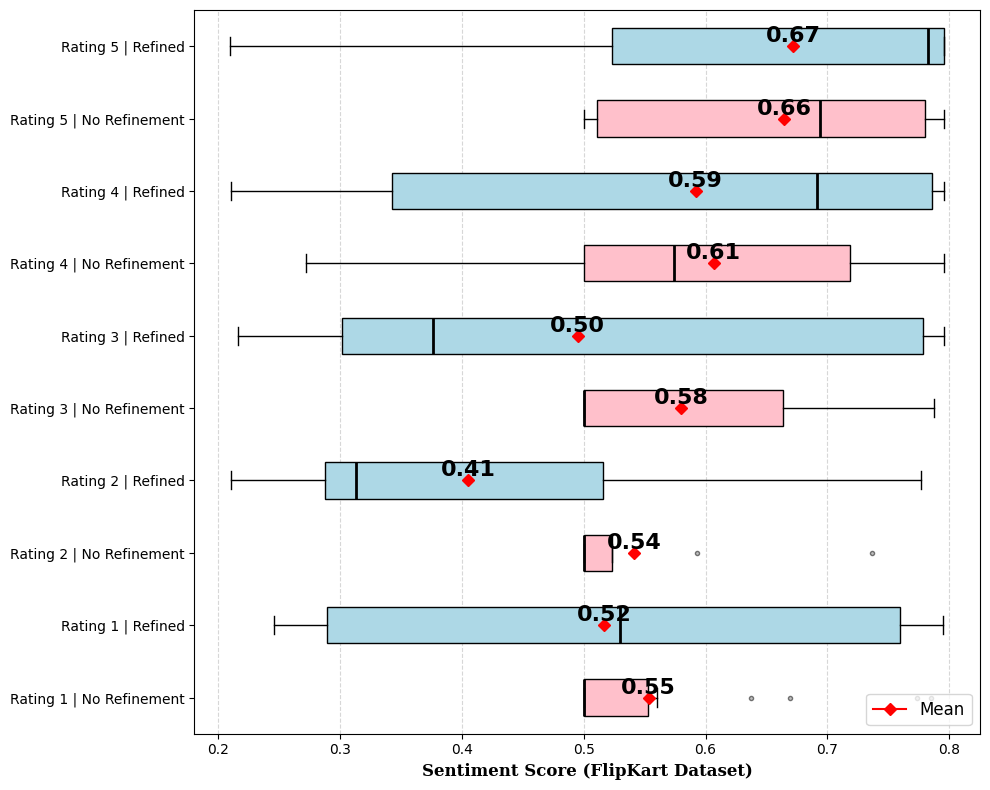

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the ratings to include (first 4 distinct ones)
unique_ratings = sorted(df_Flipkart["rating"].dropna().unique())[:5]

# Prepare data, labels, and colors
data = []
labels = []
colors = []

for rating in unique_ratings:
    subset = df_Flipkart[df_Flipkart["rating"] == rating]

    # No Refinement
    data.append(subset["Overall_Sentiment_NO_refinement"].dropna())
    labels.append(f"Rating {rating} | No Refinement")
    colors.append("pink")

    # Refined
    data.append(subset["Overall_Sentiment_ReFined"].dropna())
    labels.append(f"Rating {rating} | Refined")
    colors.append("lightblue")

# Create horizontal boxplots
plt.figure(figsize=(10, 8))

# Customize outliers (fliers) to be smaller gray dots
flier_props = dict(marker='o', markersize=3, linestyle='none', markerfacecolor='gray', alpha=0.5)

# Plot boxplots
box = plt.boxplot(data, patch_artist=True, vert=False, labels=labels, flierprops=flier_props)

# Apply box colors and emphasize medians
for patch, median, color in zip(box['boxes'], box['medians'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    median.set_color("black")
    median.set_linewidth(2)

# Add mean markers in red and display numeric mean values above the markers
for i, d in enumerate(data):
    if len(d) > 0:
        mean_val = np.mean(d)
        plt.plot(mean_val, i + 1, marker='D', color='red', label='Mean' if i == 0 else "", markersize=6)

        # Display the mean value on top of the red diamond
        plt.text(mean_val, i + 1, f'{mean_val:.2f}', fontsize=16, fontweight='bold',  # Adjust font size and boldness
                 ha='center', va='bottom', color='black')

# Apply updated font sizes and boldness as per previous boxplot settings
# plt.title("Horizontal Sentiment Boxplots per Rating (Refined vs No Refinement - Flipkart)",
#           fontsize=12, fontweight='bold', family='serif')
plt.xlabel("Sentiment Score (FlipKart Dataset)", fontsize=12, fontweight='bold', family='serif')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add a legend with font size of 12
plt.legend(loc='lower right', fontsize=12)

# Apply tight layout for the plot
plt.tight_layout()

# Save as JPEG with high resolution
plt.savefig("Sentiment_Boxplots_FlipKart.jpg", format='jpeg', dpi=800)

# Display plot
plt.show()

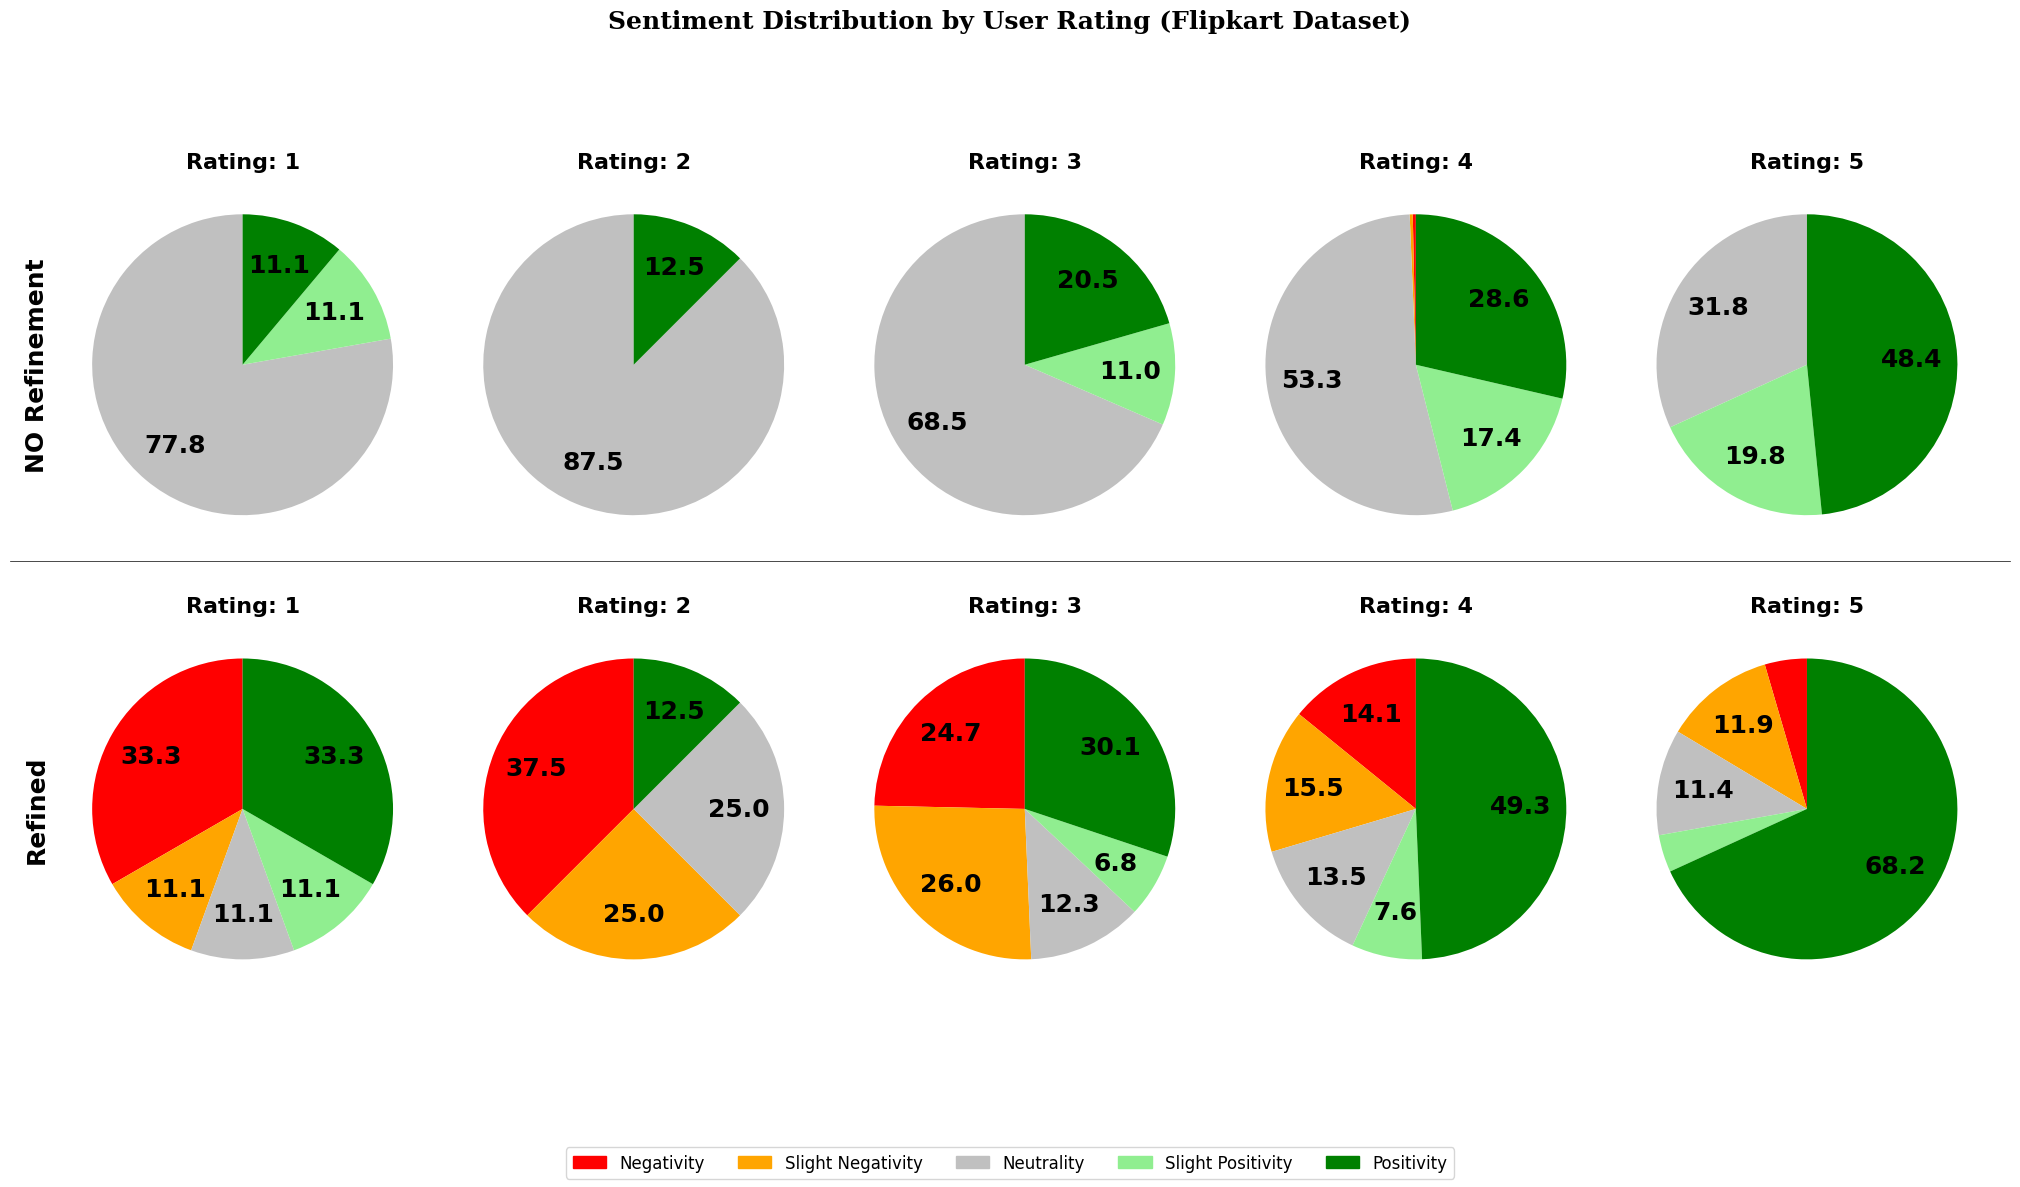

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Ensure numeric 'rating' column
df_Flipkart["rating"] = pd.to_numeric(df_Flipkart["rating"], errors="coerce")

# Categories & Score values
sentiment_categories = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]
score_values = [1, 2, 3, 4, 5]

# Color mapping
category_colors = {
    "Negativity": "red",
    "Slight Negativity": "orange",
    "Neutrality": "silver",
    "Slight Positivity": "lightgreen",
    "Positivity": "green"
}
colors = [category_colors[cat] for cat in sentiment_categories]

# === STYLING SETTINGS ===
PERCENT_DISTANCE = 0.70
PERCENT_FONTSIZE = 18  # Increased font size for percentages
LABEL_THRESHOLD = 5  # Show percentages greater than or equal to 5%

TITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'serif'}  # Title font size and boldness
SUBTITLE_FONT = {'fontsize': 18, 'fontweight': 'bold', 'family': 'sans-serif'}  # Subtitle font size and boldness
PIE_TITLE_FONT = {'fontsize': 16, 'fontweight': 'bold'}  # Pie title font settings for boldness
# =========================

# Format for percentage values
def autopct_format(pct):
    return f'{pct:.1f}' if pct >= LABEL_THRESHOLD else ''

# Subplot layout
fig, axs = plt.subplots(2, 5, figsize=(20, 12))
fig.suptitle("Sentiment Distribution by User Rating (Flipkart Dataset)", **TITLE_FONT)

# Row 1: NO Refinement
for i, score in enumerate(score_values):
    subset = df_Flipkart[df_Flipkart["rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_NO_refinement_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[0, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}  # Set font size and boldness for percentages
    )
    axs[0, i].set_title(title, **PIE_TITLE_FONT)

# Row 2: Refined
for i, score in enumerate(score_values):
    subset = df_Flipkart[df_Flipkart["rating"] == score]
    title = f"Rating: {int(score)}"
    counts = subset["Overall_Sentiment_Refined_Category"].value_counts().reindex(sentiment_categories, fill_value=0)

    axs[1, i].pie(
        counts,
        labels=None,
        autopct=autopct_format,
        startangle=90,
        colors=colors,
        pctdistance=PERCENT_DISTANCE,
        textprops={'fontsize': PERCENT_FONTSIZE, 'fontweight': 'bold'}  # Set font size and boldness for percentages
    )
    axs[1, i].set_title(title, **PIE_TITLE_FONT)

# Y-axis labels with subtitle font
axs[0, 0].set_ylabel("NO Refinement", **SUBTITLE_FONT)
axs[1, 0].set_ylabel("Refined", **SUBTITLE_FONT)

# Horizontal separator between rows
fig.subplots_adjust(hspace=0.35)
line_y = 0.52
fig.canvas.draw()
fig.lines.append(plt.Line2D([0, 1], [line_y, line_y], transform=fig.transFigure, color='black', linewidth=0.5))

# Legend with updated font size
legend_patches = [mpatches.Patch(color=category_colors[cat], label=cat) for cat in sentiment_categories]
fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=12)  # Set legend font size

# Apply tight layout for the plot to avoid overlap
plt.tight_layout(rect=[0, 0.08, 1, 0.95])

# Save the figure before showing
fig.savefig("Sentiment Distribution by User Rating (Flipkart Dataset).jpeg", format='jpeg', dpi=800)

# Show the plot
plt.show()


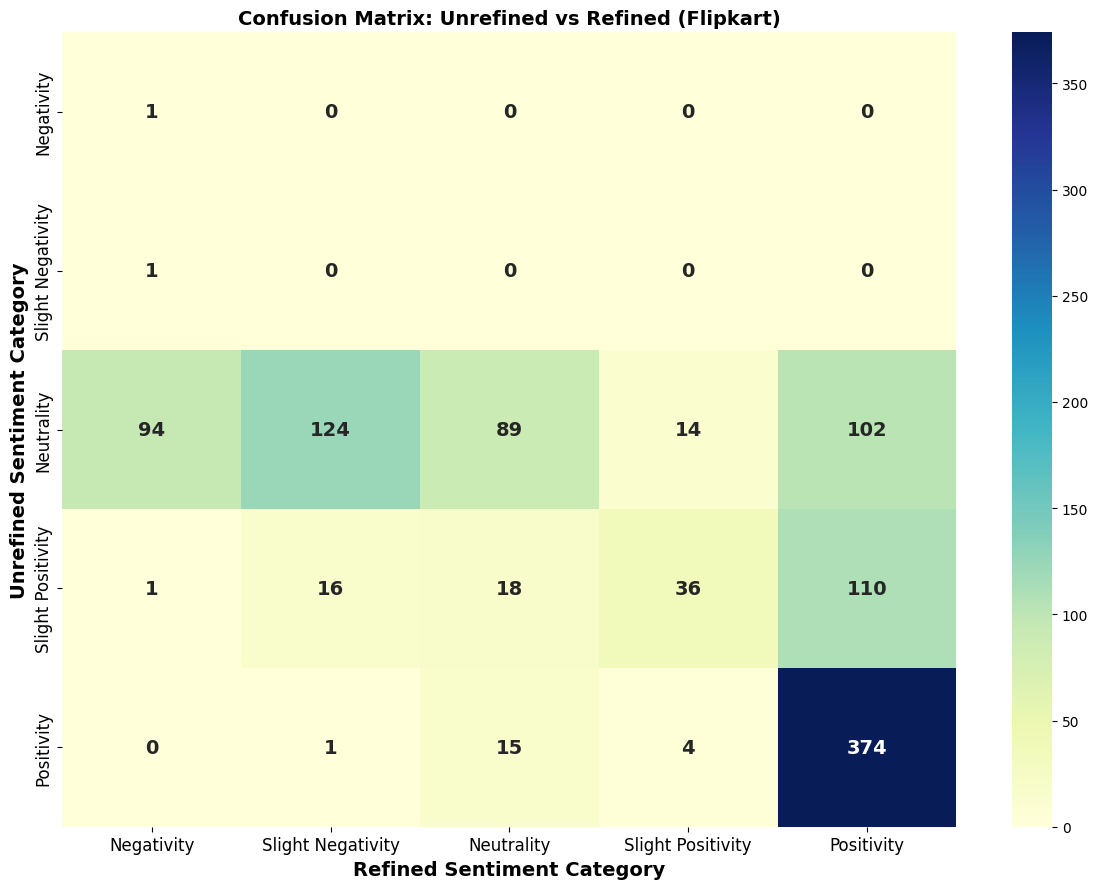

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Define sentiment order
sentiment_order = ["Negativity", "Slight Negativity", "Neutrality", "Slight Positivity", "Positivity"]

# Confusion matrix for Flipkart
cm_flipkart = confusion_matrix(
    df_Flipkart["Overall_Sentiment_NO_refinement_Category"],
    df_Flipkart["Overall_Sentiment_Refined_Category"],
    labels=sentiment_order
)

# Plot
plt.figure(figsize=(12, 9))
sns.heatmap(cm_flipkart, annot=True, fmt='d', cmap="YlGnBu",
            xticklabels=sentiment_order, yticklabels=sentiment_order,
            annot_kws={"size": 14, "weight": "bold"})

plt.title("Confusion Matrix: Unrefined vs Refined (Flipkart)", fontsize=14, weight='bold')
plt.xlabel("Refined Sentiment Category", fontsize=14, weight='bold')
plt.ylabel("Unrefined Sentiment Category", fontsize=14, weight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()

# Save the figure before showing
plt.savefig("Confusion_Matrix_FlipKart.jpeg", format='jpeg', dpi=800)

plt.show()

## **SAVING**

In [ ]:
# Save all processed DataFrames as CSV files
df_food.to_csv("df_food.csv", index=False)
df_Flipkart.to_csv("df_FlipKart.csv", index=False)
df_women_clothing.to_csv("df_women_clothing.csv", index=False)
df_trip_advisor.to_csv("df_trip_advisor.csv", index=False)

print("All DataFrames saved successfully.")

All DataFrames saved successfully.
